In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.signal import butter, filtfilt
from sklearn.metrics import r2_score
from mpl_toolkits.mplot3d import Axes3D
from sklearn.metrics import r2_score, mean_squared_error
from scipy.optimize import curve_fit
from scipy.optimize import minimize
from scipy.stats import linregress
from matplotlib.lines import Line2D
folder = r"C:\Users\lmicklem\Documents\GitHub\Muscle_Sensory\Muscle_length_sensory\18-05-2026 Literature Comparison\2026-07-16 Test Data\2026-08-04"

### Convert .txt files to .csv

In [6]:
# Set your directory path here - Commented out to prevent re-running
folder = r"C:\Users\lmicklem\Documents\GitHub\Muscle_Sensory\Muscle_length_sensory\18-05-2026 Literature Comparison\2026-07-16 Test Data\2026-08-04"
# C:\Users\lmicklem\Documents\GitHub\Muscle_Sensory\Muscle_length_sensory\18-05-2026 Literature Comparison\2026-07-16 Test Data\2026-08-04
for s in range(100, 128):       # S100 to S128
    for p in range(1, 6):    # P001 to P005
        
        filename = f"S{s:03d}P{p:03d}.txt"
        input_path = os.path.join(folder, filename)
        
        if not os.path.exists(input_path):
            print(f"Missing: {filename}")
            continue
        
        # print(f"Processing: {filename}")
        
        # Read comma-separated txt
        df = pd.read_csv(input_path)
        
        # Force first two columns to 3-digit zero-padded format
        for col in df.columns[:2]:
            df[col] = df[col].astype(int).astype(str).str.zfill(3)

        # Rename third column to 't (ms)'
        cols = list(df.columns)
        cols[2] = 't (ms)'
        df.columns = cols
        
        # Save as CSV (same folder)
        output_filename = filename.replace('.txt', '.csv')
        output_path = os.path.join(folder, output_filename)
        
        df.to_csv(output_path, index=False)

Missing: S100P002.txt
Missing: S100P003.txt
Missing: S100P004.txt
Missing: S100P005.txt
Missing: S102P002.txt
Missing: S102P004.txt
Missing: S104P004.txt
Missing: S105P001.txt
Missing: S105P004.txt
Missing: S106P004.txt
Missing: S108P001.txt
Missing: S108P005.txt
Missing: S109P003.txt
Missing: S111P002.txt
Missing: S111P003.txt
Missing: S111P004.txt
Missing: S111P005.txt
Missing: S112P003.txt
Missing: S114P003.txt
Missing: S114P005.txt
Missing: S115P002.txt
Missing: S116P002.txt
Missing: S117P002.txt
Missing: S118P005.txt
Missing: S119P002.txt
Missing: S119P003.txt
Missing: S119P004.txt
Missing: S121P005.txt
Missing: S122P003.txt
Missing: S122P004.txt
Missing: S123P002.txt
Missing: S124P001.txt


In [8]:
def butter_lowpass_filter(data, cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return filtfilt(b, a, data)

### Tare time, convert LW bits to V, Velocity

In [10]:
cutoff_freq = 2.0  # ADJUST THIS: Set your desired cutoff frequency in Hz

for s in range(100, 128):
    for p in range(1, 6):
        
        filename = f"S{s:03d}P{p:03d}.csv"
        file_path = os.path.join(folder, filename)
        
        if not os.path.exists(file_path):
            print(f"Missing: {filename}")
            continue
        
        df = pd.read_csv(file_path)
        df.columns = df.columns.str.strip()
        
        # 1. Time Setup
        time_col = pd.to_numeric(df['t (ms)'], errors='coerce')
        t0 = time_col.iloc[0]
        df['t_rel(s)'] = (time_col - t0) / 1000
        
        # 2. Voltage Calculation
        if 'LW RAW' in df.columns:
            lw_raw_col = pd.to_numeric(df['LW RAW'], errors='coerce')
            df['LW RAW (V)'] = lw_raw_col * (5 / 1024)
        
        # 3. Filter Length and Convert to Meters
        if 'Length (mm)' in df.columns:
            # Coerce to numeric, handle missing values (using the updated pandas syntax)
            length_mm = pd.to_numeric(df['Length (mm)'], errors='coerce').ffill().bfill()
            
            # Convert to meters
            length_m = length_mm / 1000
            
            # Dynamically calculate sampling frequency (fs) from time steps
            dt = df['t_rel(s)'].diff().mean()
            fs = 1.0 / dt
            
            # Apply butterworth filter
            df['Length filtered (mm)'] = butter_lowpass_filter(length_mm, cutoff=cutoff_freq, fs=fs)
            
            # 4. Calculate Velocity using Central Difference
            # np.gradient naturally performs central diff on interior points with respect to the time step
            df['Velocity (mm/s)'] = np.gradient(df['Length filtered (mm)'], df['t_rel(s)'])
        else:
            print(f"Warning: 'Length (mm)' column missing in {filename}")
        
        # Save back to same file
        df.to_csv(file_path, index=False)

Missing: S100P002.csv
Missing: S100P003.csv
Missing: S100P004.csv
Missing: S100P005.csv
Missing: S102P002.csv
Missing: S102P004.csv
Missing: S104P004.csv
Missing: S105P001.csv
Missing: S105P004.csv
Missing: S106P004.csv
Missing: S108P001.csv
Missing: S108P005.csv
Missing: S109P003.csv
Missing: S111P002.csv
Missing: S111P003.csv
Missing: S111P004.csv
Missing: S111P005.csv
Missing: S112P003.csv
Missing: S114P003.csv
Missing: S114P005.csv
Missing: S115P002.csv
Missing: S116P002.csv
Missing: S117P002.csv
Missing: S118P005.csv
Missing: S119P002.csv
Missing: S119P003.csv
Missing: S119P004.csv
Missing: S121P005.csv
Missing: S122P003.csv
Missing: S122P004.csv
Missing: S123P002.csv
Missing: S124P001.csv


### Calculate Filter Voltage, dV/dt

In [12]:
# ADJUST THESE: Savitzky-Golay parameters
# window_length must be an odd integer, polyorder must be less than window_length
window_length = 21 
polyorder = 3       

for s in range(100, 128):
    for p in range(1, 6):
        
        filename = f"S{s:03d}P{p:03d}.csv"
        file_path = os.path.join(folder, filename)
        
        if not os.path.exists(file_path):
            print(f"Missing: {filename}")
            continue
        
        df = pd.read_csv(file_path)
        df.columns = df.columns.str.strip()
        
        if 'LW RAW (V)' in df.columns and 't_rel(s)' in df.columns:
            # Handle missing values (savgol_filter fails on NaNs) using the updated Pandas syntax
            voltage = pd.to_numeric(df['LW RAW (V)'], errors='coerce').ffill().bfill()
            time = pd.to_numeric(df['t_rel(s)'], errors='coerce')
            
            # Ensure the dataset is large enough for the chosen window length
            if len(voltage) >= window_length:
                # 1. Apply Savitzky-Golay filter
                df['LW Filtered (V)'] = savgol_filter(voltage, window_length, polyorder)
                
                # 2. Calculate dv/dt using central difference
                df['dv/dt (V/s)'] = np.gradient(df['LW Filtered (V)'], time)
            else:
                print(f"Warning: Not enough data in {filename} for window length {window_length}")
        else:
            print(f"Warning: 'LW RAW (V)' or 't_rel(s)' column missing in {filename}")

        # 2. Type Ia Firing Rate Calculation
        if 'Velocity (mm/s)' in df.columns and 'Length filtered (mm)' in df.columns:
            velocity = pd.to_numeric(df['Velocity (mm/s)'], errors='coerce')
            length_filtered = pd.to_numeric(df['Length filtered (mm)'], errors='coerce')
            
            # Calculate firing rate using the fractional power model
            df['Type Ia Firing Rate'] = 4.3 * (np.sign(velocity) * np.abs(velocity)**0.6) + 2 * length_filtered + 82
        else:
            print(f"Warning: Velocity or Length missing in {filename}. Cannot compute Firing Rate.")
            
        # Save back to same file
        df.to_csv(file_path, index=False)

Missing: S100P002.csv
Missing: S100P003.csv
Missing: S100P004.csv
Missing: S100P005.csv
Missing: S102P002.csv
Missing: S102P004.csv
Missing: S104P004.csv
Missing: S105P001.csv
Missing: S105P004.csv
Missing: S106P004.csv
Missing: S108P001.csv
Missing: S108P005.csv
Missing: S109P003.csv
Missing: S111P002.csv
Missing: S111P003.csv
Missing: S111P004.csv
Missing: S111P005.csv
Missing: S112P003.csv
Missing: S114P003.csv
Missing: S114P005.csv
Missing: S115P002.csv
Missing: S116P002.csv
Missing: S117P002.csv
Missing: S118P005.csv
Missing: S119P002.csv
Missing: S119P003.csv
Missing: S119P004.csv
Missing: S121P005.csv
Missing: S122P003.csv
Missing: S122P004.csv
Missing: S123P002.csv
Missing: S124P001.csv


In [278]:
def plot_sensor_data(filename):
    file_path = os.path.join(folder, filename)
    
    if not os.path.exists(file_path):
        print(f"Error: File {filename} not found.")
        return
        
    df = pd.read_csv(file_path)
    df.columns = df.columns.str.strip()
    
    if 't_rel(s)' not in df.columns:
        print(f"Error: 't_rel(s)' column missing in {filename}")
        return

    max_time = df['t_rel(s)'].max()
    df = df[df['t_rel(s)'] <= (max_time - 0.5)].copy()

    time = df['t_rel(s)']
    
# --- Calculate Both Voltage-Based Models ---
    if 'LW Filtered (V)' in df.columns and 'dv/dt (V/s)' in df.columns:
        V = df['LW Filtered (V)']
        dvdt = df['dv/dt (V/s)']
        
        # 1. Global Equation (using the constants you provided)
        # df['FR Global'] = 35.433 * (np.sign(dvdt) * np.abs(dvdt)**0.636) + 67.960 * V + 75.515
        ### Optimised coefficients
        df['FR Global'] = 38.118 * (np.sign(dvdt) * np.abs(dvdt)**0.546) + 77.298 * V + 72.484
        
        # 2. Split Equation (Hysteresis)
        # inf_A, inf_B, inf_C, inf_D = 41.887, 0.486, 79.713, 64.167
        # def_A, def_B, def_C, def_D = 39.792, 0.595, 63.276, 80.114

### Optimised Coefficients
        inf_A, inf_B, inf_C, inf_D = 49.555, 0.390, 88.644, 55.313
        def_A, def_B, def_C, def_D = 42.297, 0.622, 67.602, 79.182
        
        fr_inflation = inf_A * (np.sign(dvdt) * np.abs(dvdt)**inf_B) + inf_C * V + inf_D
        fr_deflation = def_A * (np.sign(dvdt) * np.abs(dvdt)**def_B) + def_C * V + def_D
        
        df['FR Split'] = np.where(dvdt > 0, fr_inflation, fr_deflation)

    # Calculate RMSE
    rmse_global, rmse_split = None, None
    if 'Type Ia Firing Rate' in df.columns:
        target = df['Type Ia Firing Rate']

        # Calculate the dynamic range of the target signal
        target_range = target.max() - target.min()
        
        if 'FR Global' in df.columns:
            valid_mask_g = target.notna() & df['FR Global'].notna()
            if valid_mask_g.any():
                rmse_global = np.sqrt(np.mean((target[valid_mask_g] - df.loc[valid_mask_g, 'FR Global'])**2))
                nrmse_global = (rmse_global / target_range) * 100
                
        if 'FR Split' in df.columns:
            valid_mask_s = target.notna() & df['FR Split'].notna()
            if valid_mask_s.any():
                rmse_split = np.sqrt(np.mean((target[valid_mask_s] - df.loc[valid_mask_s, 'FR Split'])**2))
                nrmse_split = (rmse_split / target_range) * 100

    fig, axs = plt.subplots(5, 1, figsize=(10, 14), sharex=True)
    fig.suptitle(f"Sensor Data Overview: {filename}", fontsize=14, fontweight='bold')
    
    # 1. Plot Displacement
    if 'Length filtered (mm)' in df.columns:
        axs[0].plot(time, df['Length filtered (mm)'], color='blue', label='Filtered Length')
        axs[0].set_ylabel("Displacement (mm)")
    else:
        axs[0].text(0.5, 0.5, "Displacement Data Missing", ha='center')
    axs[0].legend(loc="lower left")
    axs[0].grid(True, linestyle='--', alpha=0.7)

    # 2. Plot Velocity
    if 'Velocity (mm/s)' in df.columns:
        axs[1].plot(time, df['Velocity (mm/s)'], color='orange', label='Velocity')
        axs[1].set_ylabel("Velocity (mm/s)")
    else:
        axs[1].text(0.5, 0.5, "Velocity Data Missing", ha='center')
    axs[1].legend(loc="lower left")
    axs[1].grid(True, linestyle='--', alpha=0.7)

    # 3. Plot Firing Rates with RMSE in Legend
    if 'Type Ia Firing Rate' in df.columns:
        axs[2].plot(time, df['Type Ia Firing Rate'], color='purple', label='FR (Target Mechanical)', linewidth=2.5)
        
    if 'FR Global' in df.columns:
        g_label = f'FR Global Model (NRMSE: {nrmse_global:.2f}%)' if rmse_global is not None else 'FR Global Model'
        axs[2].plot(time, df['FR Global'], color='cyan', linestyle=':', label=g_label, linewidth=1.5)
        
    if 'FR Split' in df.columns:
        s_label = f'FR Split Model (NRMSE: {nrmse_split:.2f}%)' if rmse_split is not None else 'FR Split Model'
        axs[2].plot(time, df['FR Split'], color='magenta', linestyle='--', label=s_label, linewidth=1.5)
        
    axs[2].set_ylabel("Firing Rate (Hz)")
    axs[2].legend(loc="lower left")
    axs[2].grid(True, linestyle='--', alpha=0.7)

    # 4. Plot Voltage
    if 'LW Filtered (V)' in df.columns:
        axs[3].plot(time, df['LW Filtered (V)'], color='green', label='Filtered Voltage')
        axs[3].set_ylabel("Voltage (V)")
    elif 'LW RAW (V)' in df.columns:
        axs[3].plot(time, df['LW RAW (V)'], color='green', alpha=0.5, label='Raw Voltage')
        axs[3].set_ylabel("Voltage (V)")
    else:
        axs[3].text(0.5, 0.5, "Voltage Data Missing", ha='center')
    axs[3].legend(loc="lower left")
    axs[3].grid(True, linestyle='--', alpha=0.7)

    # 5. Plot dv/dt
    if 'dv/dt (V/s)' in df.columns:
        axs[4].plot(time, df['dv/dt (V/s)'], color='red', label='dv/dt')
        axs[4].set_ylabel("Rate of Change (V/s)")
    else:
        axs[4].text(0.5, 0.5, "dv/dt Data Missing", ha='center')
    axs[4].legend(loc="lower left")
    axs[4].grid(True, linestyle='--', alpha=0.7)

    axs[4].set_xlabel("Time (s)")
    
    plt.tight_layout()
    plt.subplots_adjust(top=0.95) # Make room for the main title
    

# Save the plot
    output_filename = filename.replace('.csv', '.png')
    output_path = os.path.join(folder, output_filename)
    plt.savefig(output_path, dpi=150, bbox_inches='tight')
    
    # Close the figure to free up memory
    plt.close(fig)
    plt.show();
    return rmse_global, rmse_split

# Example usage:
plot_sensor_data("S125P001.csv")

(8.10731845616198, 7.227167219996231)

In [280]:
global_rmses = []
split_rmses = []

for s in range(100, 128):
    for p in range(1, 6):
        
        filename = f"S{s:03d}P{p:03d}.csv"
        file_path = os.path.join(folder, filename)

        if not os.path.exists(file_path):
            continue
            
        rmse_g, rmse_s = plot_sensor_data(filename)
        
        # Aggregate valid RMSE scores
        if rmse_g is not None:
            global_rmses.append(rmse_g)
        if rmse_s is not None:
            split_rmses.append(rmse_s)
            
        print(f"Processed {filename} - Global RMSE: {rmse_g:.2f} | Split RMSE: {rmse_s:.2f}")

# Calculate and display the final average errors across the entire dataset
print("\n=== FINAL RMSE EVALUATION ===")
if global_rmses:
    print(f"Average Global Model RMSE: {np.mean(global_rmses):.3f} Hz (Evaluated {len(global_rmses)} files)")
else:
    print("No valid Global RMSE data found.")
    
if split_rmses:
    print(f"Average Split Model RMSE:  {np.mean(split_rmses):.3f} Hz (Evaluated {len(split_rmses)} files)")
else:
    print("No valid Split RMSE data found.")

Processed S100P001.csv - Global RMSE: 5.36 | Split RMSE: 3.29
Processed S101P001.csv - Global RMSE: 5.47 | Split RMSE: 5.65
Processed S101P002.csv - Global RMSE: 6.69 | Split RMSE: 6.28
Processed S101P003.csv - Global RMSE: 7.10 | Split RMSE: 6.13
Processed S101P004.csv - Global RMSE: 7.15 | Split RMSE: 6.43
Processed S101P005.csv - Global RMSE: 7.11 | Split RMSE: 6.68
Processed S102P001.csv - Global RMSE: 6.86 | Split RMSE: 6.62
Processed S102P003.csv - Global RMSE: 7.41 | Split RMSE: 6.65
Processed S102P005.csv - Global RMSE: 7.78 | Split RMSE: 6.73
Processed S103P001.csv - Global RMSE: 7.47 | Split RMSE: 6.22
Processed S103P002.csv - Global RMSE: 7.46 | Split RMSE: 6.06
Processed S103P003.csv - Global RMSE: 7.48 | Split RMSE: 6.40
Processed S103P004.csv - Global RMSE: 7.43 | Split RMSE: 6.50
Processed S103P005.csv - Global RMSE: 7.35 | Split RMSE: 6.24
Processed S104P001.csv - Global RMSE: 5.05 | Split RMSE: 4.49
Processed S104P002.csv - Global RMSE: 5.61 | Split RMSE: 4.94
Processe

### Model Optimisation

In [260]:
# Define the mathematical structure
def voltage_fr_model(X, A, B, C, D):
    V, dvdt = X
    return A * (np.sign(dvdt) * np.abs(dvdt)**B) + C * V + D

def optimize_coefficients(folder):
    voltages = []
    dvdts = []
    target_frs = []
    
    print("Aggregating data from all files...")
    
    for s in range(101, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(folder, filename)
            
            if not os.path.exists(file_path):
                continue
                
            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()
            
            req_cols = ['t_rel(s)', 'LW Filtered (V)', 'dv/dt (V/s)', 'Type Ia Firing Rate']
            if all(col in df.columns for col in req_cols):
                
                # Trim the last 0.5 seconds of data before extracting
                max_time = df['t_rel(s)'].max()
                df_trimmed = df[df['t_rel(s)'] <= (max_time - 0.5)].copy()
                
                # Drop NaNs to ensure X and Y arrays remain perfectly aligned
                temp_df = df_trimmed[req_cols].dropna()
                
                voltages.extend(temp_df['LW Filtered (V)'].values)
                dvdts.extend(temp_df['dv/dt (V/s)'].values)
                target_frs.extend(temp_df['Type Ia Firing Rate'].values)
                
    # Convert to numpy arrays for the optimizer
    V = np.array(voltages)
    dvdt = np.array(dvdts)
    FR = np.array(target_frs)
    
    if len(V) == 0:
        print("Error: No valid data found.")
        return
        
    print(f"Optimization running on {len(V)} total data points...\n")
    
    # ---------------------------------------------------------
    # 1. Optimize Global Model
    # ---------------------------------------------------------
   # Calculate weights: higher FR gets exponentially higher priority
    weights_global = (FR / np.max(FR)) ** 3
    sigma_global = 1.0 / (weights_global + 0.01) # Convert weight to uncertainty (sigma)
    
    global_popt, _ = curve_fit(
        voltage_fr_model, 
        (V, dvdt), 
        FR, 
        p0=(36.0, 0.55, 79.0, 74.0), 
        sigma=sigma_global,         # <-- NEW: Pass the sigma array
        absolute_sigma=False,       # <-- NEW: Treat sigma as relative weights
        maxfev=15000
    )
    # Calculate Global RMSE
    FR_pred_global = voltage_fr_model((V, dvdt), *global_popt)
    rmse_global = np.sqrt(np.mean((FR - FR_pred_global)**2))
    
    print("=== OPTIMAL GLOBAL CONSTANTS ===")
    print(f"A = {global_popt[0]:.3f}, B = {global_popt[1]:.3f}, C = {global_popt[2]:.3f}, D = {global_popt[3]:.3f}")
    print(f"Dataset-Wide Global RMSE: {rmse_global:.2f} Hz\n")
    
    # ---------------------------------------------------------
    # 2. Optimize Split Model (Hysteresis)
    # ---------------------------------------------------------
    inflation_mask = dvdt > 0
    deflation_mask = dvdt <= 0
    
    # Isolate data arrays for each state
    V_inf, dvdt_inf, FR_inf = V[inflation_mask], dvdt[inflation_mask], FR[inflation_mask]
    V_def, dvdt_def, FR_def = V[deflation_mask], dvdt[deflation_mask], FR[deflation_mask]
    
    # Weight and Fit Inflation
    weights_inf = (FR_inf / np.max(FR)) ** 2
    sigma_inf = 1.0 / (weights_inf + 0.01)
    
    inf_popt, _ = curve_fit(
        voltage_fr_model, (V_inf, dvdt_inf), FR_inf, 
        p0=(36.0, 0.75, 70.0, 75.0), 
        sigma=sigma_inf, 
        absolute_sigma=False, 
        maxfev=45000
    )
    
    # Weight and Fit Deflation
    weights_def = (FR_def / np.max(FR)) ** 2
    sigma_def = 1.0 / (weights_def + 0.01)
    
    def_popt, _ = curve_fit(
        voltage_fr_model, (V_def, dvdt_def), FR_def, 
        p0=(36.0, 0.74, 68.0, 73.0), 
        sigma=sigma_def, 
        absolute_sigma=False, 
        maxfev=45000
    )
    
    # Calculate Split RMSE
    FR_pred_split = np.empty_like(FR)
    FR_pred_split[inflation_mask] = voltage_fr_model((V_inf, dvdt_inf), *inf_popt)
    FR_pred_split[deflation_mask] = voltage_fr_model((V_def, dvdt_def), *def_popt)
    rmse_split = np.sqrt(np.mean((FR - FR_pred_split)**2))
    
    print("=== OPTIMAL SPLIT CONSTANTS ===")
    print("Inflation (dv/dt > 0):")
    print(f"inf_A = {inf_popt[0]:.3f}, inf_B = {inf_popt[1]:.3f}, inf_C = {inf_popt[2]:.3f}, inf_D = {inf_popt[3]:.3f}")
    print("\nDeflation (dv/dt <= 0):")
    print(f"def_A = {def_popt[0]:.3f}, def_B = {def_popt[1]:.3f}, def_C = {def_popt[2]:.3f}, def_D = {def_popt[3]:.3f}")
    print(f"\nDataset-Wide Split RMSE: {rmse_split:.2f} Hz")

# Run the optimizer
if __name__ == "__main__":
    optimize_coefficients(folder)

Aggregating data from all files...
Optimization running on 38468 total data points...

=== OPTIMAL GLOBAL CONSTANTS ===
A = 38.118, B = 0.546, C = 77.298, D = 72.484
Dataset-Wide Global RMSE: 8.19 Hz

=== OPTIMAL SPLIT CONSTANTS ===
Inflation (dv/dt > 0):
inf_A = 49.555, inf_B = 0.390, inf_C = 88.644, inf_D = 55.313

Deflation (dv/dt <= 0):
def_A = 42.297, def_B = 0.622, def_C = 67.602, def_D = 79.182

Dataset-Wide Split RMSE: 7.24 Hz


### Scatter plot of all data

Aggregating data across all files...
Plotting 40667 total data points...
Linear Fit Evaluation -> Raw RMSE: 2.1753 mm
Normalized RMSE (NRMSE): 9.20%


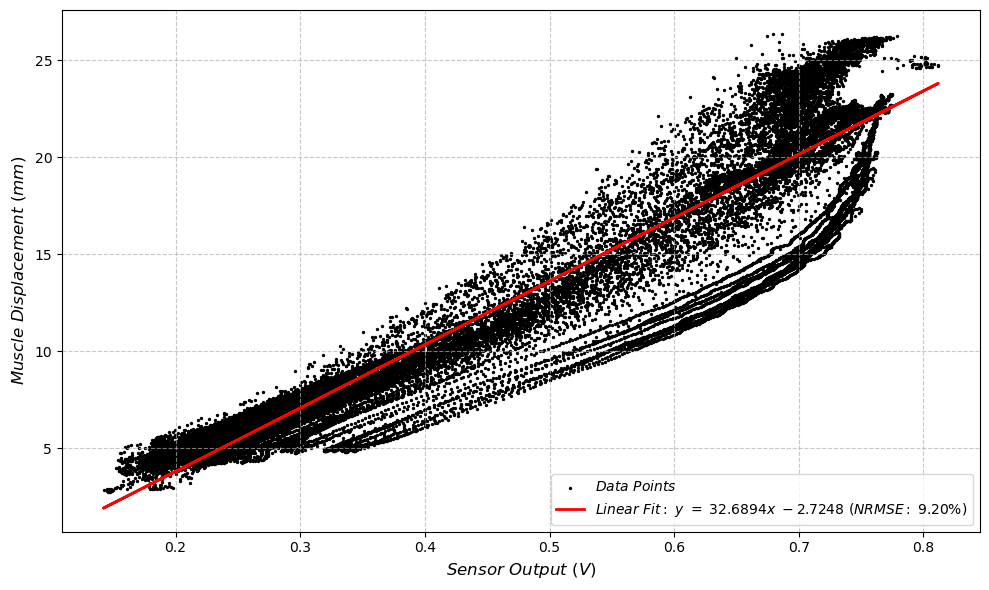

In [204]:
all_lengths = []
all_voltages = []

print("Aggregating data across all files...")

for s in range(101, 128):
    for p in range(1, 6):
        filename = f"S{s:03d}P{p:03d}.csv"
        file_path = os.path.join(folder, filename)
        
        if not os.path.exists(file_path):
            continue
            
        df = pd.read_csv(file_path)
        df.columns = df.columns.str.strip()
        
        if 'Length filtered (mm)' in df.columns and 'LW Filtered (V)' in df.columns:
            temp_df = pd.DataFrame()
            temp_df['Length'] = pd.to_numeric(df['Length filtered (mm)'], errors='coerce')
            temp_df['Voltage'] = pd.to_numeric(df['LW Filtered (V)'], errors='coerce')
            
            temp_df = temp_df.dropna()
            
            all_lengths.extend(temp_df['Length'].values)
            all_voltages.extend(temp_df['Voltage'].values)

lengths = np.array(all_lengths)
voltages = np.array(all_voltages)

if len(lengths) == 0:
    print("Error: No valid data found to plot.")
else:
    print(f"Plotting {len(lengths)} total data points...")
    
    # Assign axes: X = Voltage, Y = Length
    x_data = voltages
    y_data = lengths
    
    # Calculate linear fit
    m, b = np.polyfit(x_data, y_data, 1)
    fit_line = m * x_data + b
    
    # ==========================================
    # Calculate NRMSE (%)
    # ==========================================
    rmse = np.sqrt(np.mean((y_data - fit_line)**2))
    y_range = np.max(y_data) - np.min(y_data)
    nrmse_pct = (rmse / y_range) * 100.0
    
    print(f"Linear Fit Evaluation -> Raw RMSE: {rmse:.4f} mm")
    print(f"Normalized RMSE (NRMSE): {nrmse_pct:.2f}%")
    
    plt.figure(figsize=(10, 6))
    
    plt.scatter(x_data, y_data, color='k', alpha=1, label='$ Data~Points $', s=2) 
    
    # Updated label displaying percent NRMSE
    fit_label = f'$ Linear~Fit:~y~=~{m:.4f}x~{b:.4f}~(NRMSE:~{nrmse_pct:.2f}\\%) $'
    plt.plot(x_data, fit_line, color='red', linewidth=2, label=fit_label)
    
    plt.xlabel("$ Sensor~Output~(V) $", fontsize=12)
    plt.ylabel("$ Muscle~Displacement~(mm) $", fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend(loc='lower right', fontsize=10)
    
    plt.tight_layout()
    plt.savefig("Length_vs_Voltage_Scatter.jpg", dpi=150)
    plt.show()

Scanning files for cases > 116 and extracting peak windows...


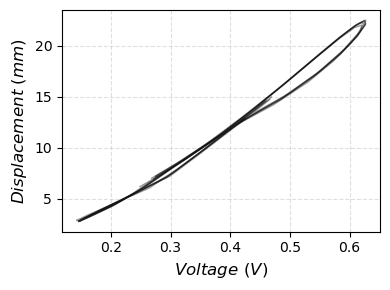

Processing complete. Plotted 5 windowed traces and saved as Windowed_Displacement_vs_Voltage_Traces.png.


In [31]:
def plot_windowed_displacement_vs_voltage(input_folder):
    fig, ax = plt.subplots(figsize=(4, 3))
    
    print("Scanning files for cases > 116 and extracting peak windows...")
    processed_count = 0
    
    # Loop through S117 to S127
    for s in range(127, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(input_folder, filename)
            
            if not os.path.exists(file_path):
                continue
                
            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()
            
            if 't_rel(s)' not in df.columns:
                continue

            # Trim the last 0.5 seconds globally
            max_time_global = df['t_rel(s)'].max()
            df = df[df['t_rel(s)'] <= (max_time_global - 0.5)].copy()
            
            if df.empty:
                continue
                
            # Identify velocity column for peak finding
            if 'Velocity (mm/s)' in df.columns:
                df['Vel_Standard'] = df['Velocity (mm/s)']
                len_col = 'Length filtered (mm)' if 'Length filtered (mm)' in df.columns else 'Length filtered (m)'
            elif 'Velocity (m/s)' in df.columns:
                df['Vel_Standard'] = df['Velocity (m/s)'] * 1000.0
                len_col = 'Length filtered (m)' if 'Length filtered (m)' in df.columns else 'Length filtered (mm)'
            else:
                continue
                
            vol_col = 'LW Filtered (V)' if 'LW Filtered (V)' in df.columns else 'LW RAW (V)'
            
            # Find Peak Velocity (Ignoring the last 15% of the run)
            search_limit_time = df['t_rel(s)'].max() * 0.85
            df_search_window = df[df['t_rel(s)'] <= search_limit_time]
            
            if df_search_window['Vel_Standard'].isna().all():
                continue
                
            peak_idx = df_search_window['Vel_Standard'].idxmax()
            peak_time = df.loc[peak_idx, 't_rel(s)']
            
            # Extract Custom Window: -0.5s to +1.0s around the peak
            win_mask = (df['t_rel(s)'] >= (peak_time - 0.45)) & (df['t_rel(s)'] <= (peak_time + 0.65))
            df_win = df[win_mask].copy()
            
            # Standardize Length to mm for the plot
            if 'mm' in len_col:
                displacement = df_win[len_col]
            else:
                displacement = df_win[len_col] * 1000.0
                
            voltage = df_win[vol_col]
            
            # Plot the trace
            ax.plot(voltage, displacement, color='k', alpha=0.4, linewidth=1.0)
            processed_count += 1
            
    if processed_count == 0:
        print("No valid files found matching the criteria.")
        plt.close(fig)
        return

    # Formatting axes and labels
    ax.set_xlabel("$ Voltage~(V) $", color='black', fontsize=12)
    ax.set_ylabel("$ Displacement~(mm) $", color='black', fontsize=12)
    ax.tick_params(axis='both', labelcolor='black', labelsize=10)
    ax.grid(True, linestyle='--', alpha=0.4)

    plt.tight_layout()
    out_name = "Windowed_Displacement_vs_Voltage_Traces.png"
    # plt.savefig(out_name, dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"Processing complete. Plotted {processed_count} windowed traces and saved as {out_name}.")
# Example usage:
plot_windowed_displacement_vs_voltage(folder)

Aggregating data across all files for scatter plot...
Plotting 40667 total data points with trace inset...


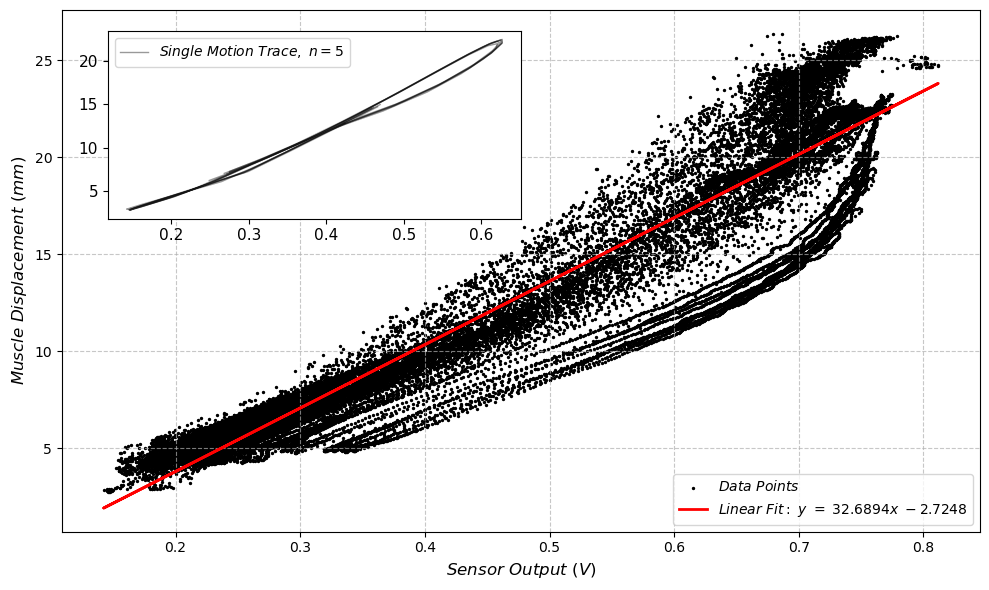

In [67]:
def plot_scatter_with_trace_inset(folder):
    all_lengths = []
    all_voltages = []

    print("Aggregating data across all files for scatter plot...")

    for s in range(101, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(folder, filename)
            
            if not os.path.exists(file_path):
                continue
                
            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()
            
            if 'Length filtered (mm)' in df.columns and 'LW Filtered (V)' in df.columns:
                temp_df = pd.DataFrame()
                temp_df['Length'] = pd.to_numeric(df['Length filtered (mm)'], errors='coerce')
                temp_df['Voltage'] = pd.to_numeric(df['LW Filtered (V)'], errors='coerce')
                
                temp_df = temp_df.dropna()
                
                all_lengths.extend(temp_df['Length'].values)
                all_voltages.extend(temp_df['Voltage'].values)

    lengths = np.array(all_lengths)
    voltages = np.array(all_voltages)

    if len(lengths) == 0:
        print("Error: No valid data found to plot.")
        return

    print(f"Plotting {len(lengths)} total data points with trace inset...")
        
    x_data = voltages
    y_data = lengths
        
    # Linear fit
    m, b = np.polyfit(x_data, y_data, 1)
    fit_line = m * x_data + b
        
    # Create Main Plot
    fig, ax_main = plt.subplots(figsize=(10, 6))
        
    ax_main.scatter(x_data, y_data, color='k', alpha=1, label='$ Data~Points $', s=2) 
    ax_main.plot(x_data, fit_line, color='red', linewidth=2, label=f'$ Linear~Fit:~y~=~{m:.4f}x~{b:.4f} $')
        
    ax_main.set_xlabel("$ Sensor~Output~(V) $", fontsize=12)
    ax_main.set_ylabel("$ Muscle~Displacement~(mm) $", fontsize=12)
    ax_main.grid(True, linestyle='--', alpha=0.7)
    ax_main.legend(loc='lower right')
    
    # =========================================================
    # Top-Left Inset: Windowed Displacement vs Voltage Traces
    # =========================================================
    # [x_origin, y_origin, width, height] relative to main axes
    ax_inset = ax_main.inset_axes([0.05, 0.60, 0.45, 0.36])
    
    processed_count = 0
    
    # Loop for test cases > 116 (S117 through S127)
    for s in range(127, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(folder, filename)
            
            if not os.path.exists(file_path):
                continue
                
            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()
            
            if 't_rel(s)' not in df.columns:
                continue

            # Trim the last 0.5 seconds globally
            max_time_global = df['t_rel(s)'].max()
            df = df[df['t_rel(s)'] <= (max_time_global - 0.5)].copy()
            
            if df.empty:
                continue
                
            # Velocity standardisation
            if 'Velocity (mm/s)' in df.columns:
                df['Vel_Standard'] = df['Velocity (mm/s)']
                len_col = 'Length filtered (mm)' if 'Length filtered (mm)' in df.columns else 'Length filtered (m)'
            elif 'Velocity (m/s)' in df.columns:
                df['Vel_Standard'] = df['Velocity (m/s)'] * 1000.0
                len_col = 'Length filtered (m)' if 'Length filtered (m)' in df.columns else 'Length filtered (mm)'
            else:
                continue
                
            vol_col = 'LW Filtered (V)' if 'LW Filtered (V)' in df.columns else 'LW RAW (V)'
            
            # Find Peak Velocity (Ignoring the last 15% of the run)
            search_limit_time = df['t_rel(s)'].max() * 0.85
            df_search_window = df[df['t_rel(s)'] <= search_limit_time]
            
            if df_search_window['Vel_Standard'].isna().all():
                continue
                
            peak_idx = df_search_window['Vel_Standard'].idxmax()
            peak_time = df.loc[peak_idx, 't_rel(s)']
            
            # Extract Window: -0.45s to +0.65s around peak velocity
            win_mask = (df['t_rel(s)'] >= (peak_time - 0.45)) & (df['t_rel(s)'] <= (peak_time + 0.65))
            df_win = df[win_mask].copy()
            
            if 'mm' in len_col:
                displacement = df_win[len_col]
            else:
                displacement = df_win[len_col] * 1000.0
                
            voltage = df_win[vol_col]
            
            # Plot trace on inset axis
            ax_inset.plot(voltage, displacement, color='k', alpha=0.4, linewidth=1.0)
            processed_count += 1

    # Format inset axis
    # ax_inset.set_xlabel("$ Sensor~Output~(V) $", color='black', fontsize=11)
    # ax_inset.set_ylabel("$ Muscle~Displacement~(mm) $", color='black', fontsize=11)
    ax_inset.tick_params(axis='both', labelcolor='black', labelsize=11)
    ax_inset.grid(True, linestyle='--', alpha=0)
    # Create proxy line handle for the custom legend entry
    trace_legend_handle = [Line2D([0], [0], color='k', alpha=0.4, linewidth=1.0)]
    
    # Add single-item legend to the inset
    ax_inset.legend(
        trace_legend_handle, 
        ['$ Single~Motion~Trace,~n=5 $'], 
        loc='upper left', 
        fontsize=10, 
        frameon=True, 
        framealpha=0.8
    )

    # Save and output
    plt.tight_layout()
    plt.savefig("Length_vs_Voltage_Scatter_With_Inset.png", dpi=300, bbox_inches='tight')
    plt.show()

# Example usage:
plot_scatter_with_trace_inset(folder)

Aggregating data across all files for scatter plot...


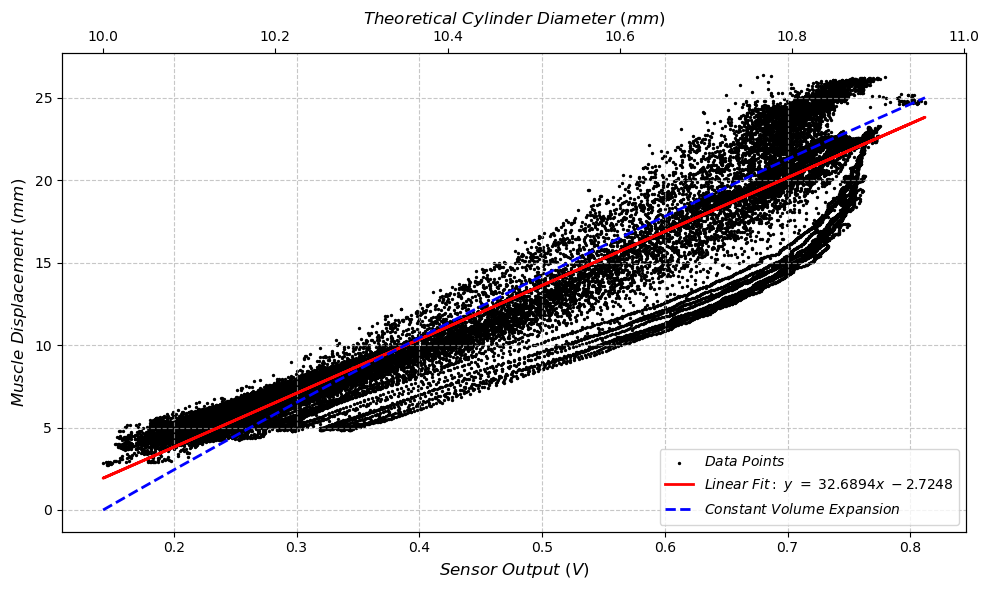

In [115]:
def plot_scatter_with_quadratic_diameter(folder):
    all_lengths = []
    all_voltages = []

    print("Aggregating data across all files for scatter plot...")

    for s in range(101, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(folder, filename)
            
            if not os.path.exists(file_path):
                continue
                
            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()
            
            if 'Length filtered (mm)' in df.columns and 'LW Filtered (V)' in df.columns:
                temp_df = pd.DataFrame()
                temp_df['Length'] = pd.to_numeric(df['Length filtered (mm)'], errors='coerce')
                temp_df['Voltage'] = pd.to_numeric(df['LW Filtered (V)'], errors='coerce')
                
                temp_df = temp_df.dropna()
                
                all_lengths.extend(temp_df['Length'].values)
                all_voltages.extend(temp_df['Voltage'].values)

    lengths = np.array(all_lengths)
    voltages = np.array(all_voltages)

    if len(lengths) == 0:
        print("Error: No valid data found to plot.")
        return

    x_data = voltages
    y_data = lengths
        
    fig, ax_main = plt.subplots(figsize=(10, 6))
        
    # Main Scatter Plot and Linear Fit
    m, b = np.polyfit(x_data, y_data, 1)
    fit_line = m * x_data + b
    
    ax_main.scatter(x_data, y_data, color='k', alpha=1, label='$ Data~Points $', s=2) 
    ax_main.plot(x_data, fit_line, color='red', linewidth=2, label=f'$ Linear~Fit:~y~=~{m:.4f}x~{b:.4f} $')
        
    ax_main.set_xlabel("$ Sensor~Output~(V) $", fontsize=12)
    ax_main.set_ylabel("$ Muscle~Displacement~(mm) $", fontsize=12)
    ax_main.grid(True, linestyle='--', alpha=0.7)
    # ax_main.set_ylim(0, 25)

    # =========================================================
    # True Non-Linear Cylinder Diameter Curve
    # =========================================================
    L0 = 150.0  # mm
    D0 = 10.0   # mm
    V0 = 0.25 * np.pi * (D0**2) * L0  # Constant Volume = 4000 * pi mm^3

    # Generate 200 non-linear evaluation points across displacement range (0 to 25 mm)
    disp_range = np.linspace(0, 25, 200)
    
    # Exact non-linear diameter formula: D(x) = sqrt(4 * V0 / (pi * (L0 - x)))
    diam_range = np.sqrt((4.0 * V0) / (np.pi * (L0 - disp_range)))

    # Secondary X-Axis tied to the top of the plot
    ax_top = ax_main.twiny()
    
    # Plot displacement (Y) against non-linear diameter (X_top)
    ax_top.plot(diam_range, disp_range, color='blue', linestyle='--', linewidth=2, 
                label='$ Constant~Volume~Expansion $')

    # Configure top axis
    ax_top.set_xlabel("$ Theoretical~Cylinder~Diameter~(mm) $", fontsize=12)
    ax_top.tick_params(axis='x')
    ax_top.grid(False)  # Keep grid clean

    # Combine legends from both axes
    lines_main, labels_main = ax_main.get_legend_handles_labels()
    lines_top, labels_top = ax_top.get_legend_handles_labels()
    ax_main.legend(lines_main + lines_top, labels_main + labels_top, loc='lower right', fontsize=10)

    plt.tight_layout()
    plt.savefig("Length_vs_Voltage_Quadratic_Cylinder.png", dpi=300, bbox_inches='tight')
    plt.show()

# Example usage:
plot_scatter_with_quadratic_diameter(folder)

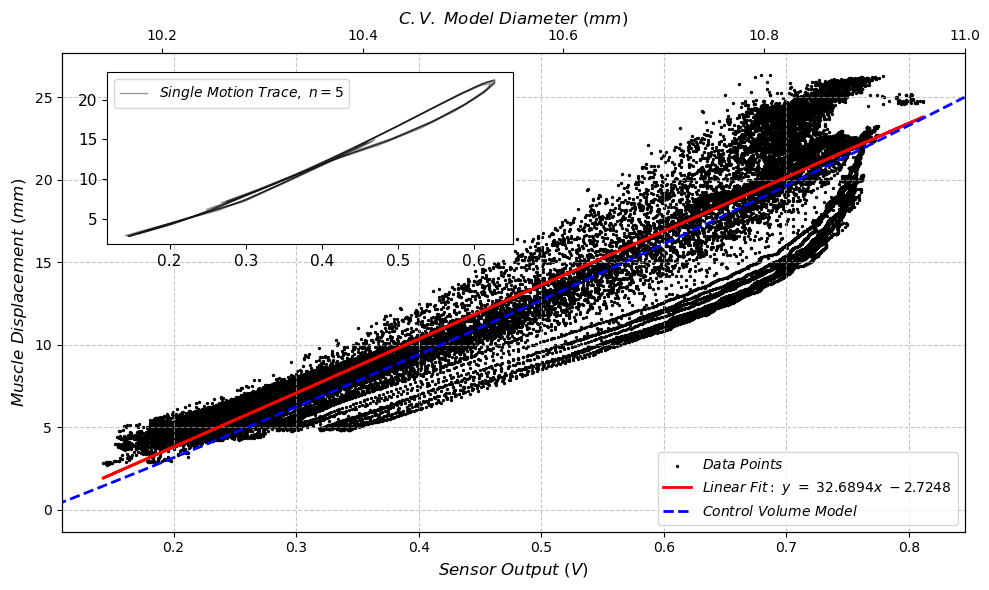

In [3]:
def plot_scatter_fixed_ref_diameter(folder):
    all_lengths = []
    all_voltages = []

    for s in range(101, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(folder, filename)
            
            if not os.path.exists(file_path):
                continue
                
            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()
            
            if 'Length filtered (mm)' in df.columns and 'LW Filtered (V)' in df.columns:
                temp_df = pd.DataFrame()
                temp_df['Length'] = pd.to_numeric(df['Length filtered (mm)'], errors='coerce')
                temp_df['Voltage'] = pd.to_numeric(df['LW Filtered (V)'], errors='coerce')
                
                temp_df = temp_df.dropna()
                
                all_lengths.extend(temp_df['Length'].values)
                all_voltages.extend(temp_df['Voltage'].values)

    lengths = np.array(all_lengths)
    voltages = np.array(all_voltages)

    if len(lengths) == 0:
        print("Error: No valid data found to plot.")
        return

    x_data = voltages
    y_data = lengths
        
    fig, ax_main = plt.subplots(figsize=(10, 6))
        
    # Main Scatter Plot and Linear Fit
    m, b = np.polyfit(x_data, y_data, 1)
    fit_line = m * x_data + b
    
    ax_main.scatter(x_data, y_data, color='k', alpha=1, label='$ Data~Points $', s=2) 
    ax_main.plot(x_data, fit_line, color='red', linewidth=2, label=f'$ Linear~Fit:~y~=~{m:.4f}x~{b:.4f} $')
        
    ax_main.set_xlabel("$ Sensor~Output~(V) $", fontsize=12)
    ax_main.set_ylabel("$ Muscle~Displacement~(mm) $", fontsize=12)
    ax_main.grid(True, linestyle='--', alpha=0.7)
    # ax_main.set_ylim(0, 25)

    # =========================================================
    # Extension Cylinder (D = 10mm fixed at L = 160mm / x = 25mm)
    # =========================================================
    L_ref = 155.0  # Length at 25mm displacement
    D_ref = 10.0   # Diameter at 25mm displacement
    V0 = 0.25 * np.pi * (D_ref**2) * L_ref  # Constant Volume = 4000 * pi mm^3

    disp_range = np.linspace(0, 25, 200)
    
    # Extension equation: L(x) = 135 + x
    diam_range = np.sqrt((4.0 * V0) / (np.pi * (130.0 + disp_range)))

    # Secondary X-Axis tied to top
    ax_top = ax_main.twiny()
    
    # Plot displacement vs non-linear diameter
    ax_top.plot(21 - diam_range, disp_range, color='blue', linestyle='--', linewidth=2, 
                label='$ Control~Volume~Model $')

    # Configure top axis limits to span 10.89mm -> 10.00mm
    ax_top.set_xlabel("$ C.V.~Model~Diameter~(mm) $", fontsize=12)
    ax_top.tick_params(axis='x')
    ax_top.grid(False)
    ax_top.set_xlim(10.1, 11)


    # Combined Legend
    lines_main, labels_main = ax_main.get_legend_handles_labels()
    lines_top, labels_top = ax_top.get_legend_handles_labels()
    ax_main.legend(lines_main + lines_top, labels_main + labels_top, loc='lower right', fontsize=10)

     # =========================================================
    # Top-Left Inset: Windowed Displacement vs Voltage Traces
    # =========================================================
    # [x_origin, y_origin, width, height] relative to main axes
    ax_inset = ax_main.inset_axes([0.05, 0.60, 0.45, 0.36])
    
    processed_count = 0
    
    # Loop for test cases > 116 (S117 through S127)
    for s in range(127, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(folder, filename)
            
            if not os.path.exists(file_path):
                continue
                
            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()
            
            if 't_rel(s)' not in df.columns:
                continue

            # Trim the last 0.5 seconds globally
            max_time_global = df['t_rel(s)'].max()
            df = df[df['t_rel(s)'] <= (max_time_global - 0.5)].copy()
            
            if df.empty:
                continue
                
            # Velocity standardisation
            if 'Velocity (mm/s)' in df.columns:
                df['Vel_Standard'] = df['Velocity (mm/s)']
                len_col = 'Length filtered (mm)' if 'Length filtered (mm)' in df.columns else 'Length filtered (m)'
            elif 'Velocity (m/s)' in df.columns:
                df['Vel_Standard'] = df['Velocity (m/s)'] * 1000.0
                len_col = 'Length filtered (m)' if 'Length filtered (m)' in df.columns else 'Length filtered (mm)'
            else:
                continue
                
            vol_col = 'LW Filtered (V)' if 'LW Filtered (V)' in df.columns else 'LW RAW (V)'
            
            # Find Peak Velocity (Ignoring the last 15% of the run)
            search_limit_time = df['t_rel(s)'].max() * 0.85
            df_search_window = df[df['t_rel(s)'] <= search_limit_time]
            
            if df_search_window['Vel_Standard'].isna().all():
                continue
                
            peak_idx = df_search_window['Vel_Standard'].idxmax()
            peak_time = df.loc[peak_idx, 't_rel(s)']
            
            # Extract Window: -0.45s to +0.65s around peak velocity
            win_mask = (df['t_rel(s)'] >= (peak_time - 0.45)) & (df['t_rel(s)'] <= (peak_time + 0.65))
            df_win = df[win_mask].copy()
            
            if 'mm' in len_col:
                displacement = df_win[len_col]
            else:
                displacement = df_win[len_col] * 1000.0
                
            voltage = df_win[vol_col]
            
            # Plot trace on inset axis
            ax_inset.plot(voltage, displacement, color='k', alpha=0.4, linewidth=1.0)
            processed_count += 1

    # Format inset axis
    # ax_inset.set_xlabel("$ Sensor~Output~(V) $", color='black', fontsize=11)
    # ax_inset.set_ylabel("$ Muscle~Displacement~(mm) $", color='black', fontsize=11)
    ax_inset.tick_params(axis='both', labelcolor='black', labelsize=11)
    ax_inset.grid(True, linestyle='--', alpha=0)
    # Create proxy line handle for the custom legend entry
    trace_legend_handle = [Line2D([0], [0], color='k', alpha=0.4, linewidth=1.0)]
    
    # Add single-item legend to the inset
    ax_inset.legend(
        trace_legend_handle, 
        ['$ Single~Motion~Trace,~n=5 $'], 
        loc='upper left', 
        fontsize=10, 
        frameon=True, 
        framealpha=0.8
    )

    plt.tight_layout()
    plt.savefig("Length_vs_Voltage_Extension_Anchored.png", dpi=300, bbox_inches='tight')
    plt.show()

# Example usage:
plot_scatter_fixed_ref_diameter(folder)


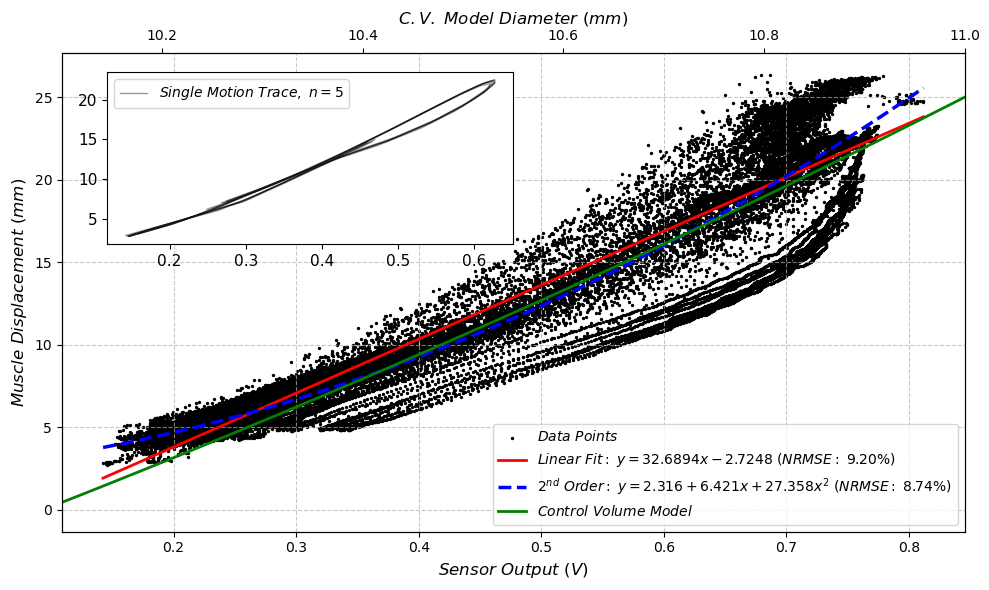

In [33]:
def plot_scatter_fixed_ref_diameter(folder):
    all_lengths = []
    all_voltages = []

    for s in range(101, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(folder, filename)
            
            if not os.path.exists(file_path):
                continue
                
            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()
            
            if 'Length filtered (mm)' in df.columns and 'LW Filtered (V)' in df.columns:
                temp_df = pd.DataFrame()
                temp_df['Length'] = pd.to_numeric(df['Length filtered (mm)'], errors='coerce')
                temp_df['Voltage'] = pd.to_numeric(df['LW Filtered (V)'], errors='coerce')
                
                temp_df = temp_df.dropna()
                
                all_lengths.extend(temp_df['Length'].values)
                all_voltages.extend(temp_df['Voltage'].values)

    lengths = np.array(all_lengths)
    voltages = np.array(all_voltages)

    if len(lengths) == 0:
        print("Error: No valid data found to plot.")
        return

    x_data = voltages
    y_data = lengths
    
    # Calculate target range for NRMSE normalization
    y_range = np.max(y_data) - np.min(y_data)
        
    fig, ax_main = plt.subplots(figsize=(10, 6))
        
    # =========================================================
    # 1. Linear Fit and NRMSE
    # =========================================================
    m, b = np.polyfit(x_data, y_data, 1)
    linear_preds = m * x_data + b
    rmse_lin = np.sqrt(np.mean((y_data - linear_preds)**2))
    nrmse_lin = (rmse_lin / y_range) * 100.0
    
    # =========================================================
    # 2. ODE (Quadratic) Fit and NRMSE
    # =========================================================
    c2, c1, c0 = np.polyfit(x_data, y_data, 2)
    ode_preds = c2 * (x_data**2) + c1 * x_data + c0
    rmse_ode = np.sqrt(np.mean((y_data - ode_preds)**2))
    nrmse_ode = (rmse_ode / y_range) * 100.0

    # Generate smooth x-axis values for plotting the fit lines
    x_plot = np.linspace(np.min(x_data), np.max(x_data), 500)
    linear_plot = m * x_plot + b
    ode_plot = c2 * (x_plot**2) + c1 * x_plot + c0
    
    # Plot Main Scatter and Fits
    ax_main.scatter(x_data, y_data, color='k', alpha=1, label='$ Data~Points $', s=2) 
    ax_main.plot(x_plot, linear_plot, color='red', linewidth=2, 
                 label=f'$ Linear~Fit:~y={m:.4f}x{b:+.4f}~(NRMSE:~{nrmse_lin:.2f}\\%) $')
    ax_main.plot(x_plot, ode_plot, color='blue', linestyle='--', linewidth=2.5, 
                 label=f'$ 2^{{nd}}~Order:~y={c0:.3f}+{c1:.3f}x+{c2:.3f}x^2~(NRMSE:~{nrmse_ode:.2f}\\%) $')
        
    ax_main.set_xlabel("$ Sensor~Output~(V) $", fontsize=12)
    ax_main.set_ylabel("$ Muscle~Displacement~(mm) $", fontsize=12)
    ax_main.grid(True, linestyle='--', alpha=0.7)

    # =========================================================
    # 3. Extension Cylinder (D = 10mm fixed at L = 160mm / x = 25mm)
    # =========================================================
    L_ref = 155.0  # Length at 25mm displacement
    D_ref = 10.0   # Diameter at 25mm displacement
    V0 = 0.25 * np.pi * (D_ref**2) * L_ref  # Constant Volume = 4000 * pi mm^3

    disp_range = np.linspace(0, 25, 200)
    
    # Extension equation: L(x) = 135 + x
    diam_range = np.sqrt((4.0 * V0) / (np.pi * (130.0 + disp_range)))

    # Secondary X-Axis tied to top
    ax_top = ax_main.twiny()
    
    # Plot displacement vs non-linear diameter
    ax_top.plot(21 - diam_range, disp_range, color='green', linestyle='-', linewidth=2, 
                label='$ Control~Volume~Model $')

    # Configure top axis limits to span 10.1mm -> 11.00mm
    ax_top.set_xlabel("$ C.V.~Model~Diameter~(mm) $", fontsize=12)
    ax_top.tick_params(axis='x')
    ax_top.grid(False)
    ax_top.set_xlim(10.1, 11)

    # Combined Legend
    lines_main, labels_main = ax_main.get_legend_handles_labels()
    lines_top, labels_top = ax_top.get_legend_handles_labels()
    ax_main.legend(lines_main + lines_top, labels_main + labels_top, loc='lower right', fontsize=10)

     # =========================================================
    # 4. Top-Left Inset: Windowed Displacement vs Voltage Traces
    # =========================================================
    ax_inset = ax_main.inset_axes([0.05, 0.60, 0.45, 0.36])
    
    processed_count = 0
    
    # Loop for test cases > 116 (S117 through S127)
    for s in range(127, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(folder, filename)
            
            if not os.path.exists(file_path):
                continue
                
            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()
            
            if 't_rel(s)' not in df.columns:
                continue

            max_time_global = df['t_rel(s)'].max()
            df = df[df['t_rel(s)'] <= (max_time_global - 0.5)].copy()
            
            if df.empty:
                continue
                
            # Velocity standardisation
            if 'Velocity (mm/s)' in df.columns:
                df['Vel_Standard'] = df['Velocity (mm/s)']
                len_col = 'Length filtered (mm)' if 'Length filtered (mm)' in df.columns else 'Length filtered (m)'
            elif 'Velocity (m/s)' in df.columns:
                df['Vel_Standard'] = df['Velocity (m/s)'] * 1000.0
                len_col = 'Length filtered (m)' if 'Length filtered (m)' in df.columns else 'Length filtered (mm)'
            else:
                continue
                
            vol_col = 'LW Filtered (V)' if 'LW Filtered (V)' in df.columns else 'LW RAW (V)'
            
            # Find Peak Velocity (Ignoring the last 15% of the run)
            search_limit_time = df['t_rel(s)'].max() * 0.85
            df_search_window = df[df['t_rel(s)'] <= search_limit_time]
            
            if df_search_window['Vel_Standard'].isna().all():
                continue
                
            peak_idx = df_search_window['Vel_Standard'].idxmax()
            peak_time = df.loc[peak_idx, 't_rel(s)']
            
            # Extract Window: -0.45s to +0.65s around peak velocity
            win_mask = (df['t_rel(s)'] >= (peak_time - 0.45)) & (df['t_rel(s)'] <= (peak_time + 0.65))
            df_win = df[win_mask].copy()
            
            if 'mm' in len_col:
                displacement = df_win[len_col]
            else:
                displacement = df_win[len_col] * 1000.0
                
            voltage = df_win[vol_col]
            
            # Plot trace on inset axis
            ax_inset.plot(voltage, displacement, color='k', alpha=0.4, linewidth=1.0)
            processed_count += 1

    ax_inset.tick_params(axis='both', labelcolor='black', labelsize=11)
    ax_inset.grid(True, linestyle='--', alpha=0)
    
    trace_legend_handle = [Line2D([0], [0], color='k', alpha=0.4, linewidth=1.0)]
    
    ax_inset.legend(
        trace_legend_handle, 
        ['$ Single~Motion~Trace,~n=5 $'], 
        loc='upper left', 
        fontsize=10, 
        frameon=True, 
        framealpha=0.8
    )

    plt.tight_layout()
    plt.savefig("Length_vs_Voltage_Extension_Anchored_Updated.png", dpi=300, bbox_inches='tight')
    plt.show()

# Example usage:
plot_scatter_fixed_ref_diameter(folder)

<>:112: SyntaxWarning: invalid escape sequence '\%'
<>:112: SyntaxWarning: invalid escape sequence '\%'
C:\Users\lmicklem\AppData\Local\Temp\ipykernel_55564\3501916068.py:112: SyntaxWarning: invalid escape sequence '\%'
  label=f'$Collapsed~Data~Points~(NRMSE:~{final_nrmse:.1f}\%)$', s=1)


Aggregating data for optimization...
Optimizing model coefficients for minimum NRMSE...

--- Optimized Polynomial Coefficients ---
tau : 0.199999
c0  : -1.4687
c1  : 25.8256
c2  : 7.3908
c3  : 6.8619

Polynomial Model NRMSE: 4.61%


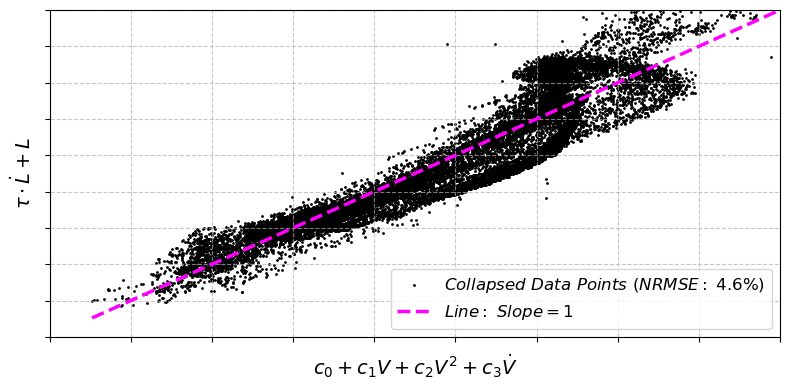

Processing complete. Plotted clean data collapse and saved as Pure_Data_Collapse_Model_NRMSE.png.


In [73]:
def plot_pure_data_collapse_nrmse(folder):
    all_L = []
    all_V = []
    all_dLdt = []
    all_dVdt = []

    print("Aggregating data for optimization...")
    # Process all available trials (S101 to S127)
    for s in range(101, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(folder, filename)
            
            if not os.path.exists(file_path):
                continue
                
            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()
            
            # Identify required columns
            len_col = 'Length filtered (mm)' if 'Length filtered (mm)' in df.columns else 'Length filtered (m)'
            vel_col = 'Velocity (mm/s)' if 'Velocity (mm/s)' in df.columns else 'Velocity (m/s)'
            vol_col = 'LW Filtered (V)' if 'LW Filtered (V)' in df.columns else 'LW RAW (V)'
            
            req_cols = [len_col, vol_col, vel_col, 'dv/dt (V/s)']
            if not all(col in df.columns for col in req_cols):
                continue
                
            temp_df = df[req_cols].dropna().copy()
            if temp_df.empty:
                continue
                
            # Standardize length to mm and velocity to mm/s
            L = temp_df[len_col].values
            if 'm' in len_col and 'mm' not in len_col:
                L = L * 1000.0
                
            dLdt = temp_df[vel_col].values
            if 'm/s' in vel_col and 'mm' not in vel_col:
                dLdt = dLdt * 1000.0
                
            V = temp_df[vol_col].values
            dVdt = temp_df['dv/dt (V/s)'].values
            
            all_L.extend(L)
            all_V.extend(V)
            all_dLdt.extend(dLdt)
            all_dVdt.extend(dVdt)

    L_arr = np.array(all_L)
    V_arr = np.array(all_V)
    dLdt_arr = np.array(all_dLdt)
    dVdt_arr = np.array(all_dVdt)

    if len(L_arr) == 0:
        print("Error: No valid data found for optimization.")
        return

    # =========================================================
    # 1. Optimize Coefficients for NRMSE (%)
    # =========================================================
    def objective(params):
        tau, c0, c1, c2, c3 = params
        
        # Prevent optimizer from blowing up tau just to inflate the denominator
        if tau < 0.0 or tau > 0.2: 
            return 1e5
            
        mechanical_state = tau * dLdt_arr + L_arr
        sensor_model = c0 + c1 * V_arr + c2 * (V_arr**2) + c3 * dVdt_arr
        
        rmse = np.sqrt(np.mean((mechanical_state - sensor_model)**2))
        
        # Normalize by the range of the evaluated mechanical state
        state_range = np.max(mechanical_state) - np.min(mechanical_state)
        if state_range == 0:
            return 1e5
            
        nrmse = (rmse / state_range) * 100.0
        return nrmse

    # Initial guess [tau, c0, c1, c2, c3]
    initial_guess = [0.01, 100.0, 10.0, 0.0, 0.0]
    print("Optimizing model coefficients for minimum NRMSE...")
    res = minimize(objective, initial_guess, method='Nelder-Mead')
    opt_tau, opt_c0, opt_c1, opt_c2, opt_c3 = res.x
    
    print("\n--- Optimized Polynomial Coefficients ---")
    print(f"tau : {opt_tau:.6f}")
    print(f"c0  : {opt_c0:.4f}")
    print(f"c1  : {opt_c1:.4f}")
    print(f"c2  : {opt_c2:.4f}")
    print(f"c3  : {opt_c3:.4f}\n")

    # Evaluate optimal collapse arrays and final NRMSE
    mechanical_y = opt_tau * dLdt_arr + L_arr
    sensor_x = opt_c0 + opt_c1 * V_arr + opt_c2 * (V_arr**2) + opt_c3 * dVdt_arr
    
    final_rmse = np.sqrt(np.mean((mechanical_y - sensor_x)**2))
    final_range = np.max(mechanical_y) - np.min(mechanical_y)
    final_nrmse = (final_rmse / final_range) * 100.0
    
    print(f"Polynomial Model NRMSE: {final_nrmse:.2f}%")

    # =========================================================
    # 2. Main Plot Generation
    # =========================================================
    fig, ax = plt.subplots(figsize=(8, 4))
        
    # Plot collapsed scatter
    ax.scatter(sensor_x, mechanical_y, color='k', alpha=1, 
               label=f'$Collapsed~Data~Points~(NRMSE:~{final_nrmse:.1f}\%)$', s=1) 
    
    # Plot ideal 45-degree line (y = x)
    min_val = min(np.min(sensor_x), np.min(mechanical_y))
    max_val = max(np.max(sensor_x), np.max(mechanical_y))
    
    ax.plot([min_val, max_val], [min_val, max_val], color='magenta', linewidth=2.5, linestyle='--', 
            label=r'$Line:~Slope=1$')
        
    ax.set_xlabel(r"$c_0 + c_1V + c_2V^2 + c_3\dot{V}$", fontsize=14)
    ax.set_ylabel(r"$\tau\cdot \dot{L} + L$", fontsize=14)
    ax.tick_params(axis='both', labelsize=12)
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.set_xlim(-10,35)
    ax.set_ylim(-10,35)
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    
    # Keep the aspect ratio square to emphasize the 45-degree geometry
    # ax.set_aspect('equal', adjustable='box')
    
    ax.legend(loc='lower right', fontsize=12)

    plt.tight_layout()
    out_name = "Pure_Data_Collapse_Model_NRMSE.png"
    plt.savefig(out_name, dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"Processing complete. Plotted clean data collapse and saved as {out_name}.")

# Example usage:
plot_pure_data_collapse_nrmse(folder)

### Basic mathematical model

In [240]:
# Define the target mathematical model
def voltage_fr_model(X, A, B, C, D): 
    V, dvdt = X
    return A * (np.sign(dvdt) * np.abs(dvdt)**B) + C * V + D

# Initialize lists to aggregate data
voltages = []
dvdts = []
target_frs = []

print("Aggregating data for curve fitting...")

for s in range(101, 128):
    for p in range(1, 6):
        filename = f"S{s:03d}P{p:03d}.csv"
        file_path = os.path.join(folder, filename)
        
        if not os.path.exists(file_path):
            continue
            
        df = pd.read_csv(file_path)
        df.columns = df.columns.str.strip()
        
        req_cols = ['LW Filtered (V)', 'dv/dt (V/s)', 'Type Ia Firing Rate']
        if all(col in df.columns for col in req_cols):
            temp_df = df[req_cols].dropna()
            
            voltages.extend(temp_df['LW Filtered (V)'].values)
            dvdts.extend(temp_df['dv/dt (V/s)'].values)
            target_frs.extend(temp_df['Type Ia Firing Rate'].values)

# Convert to numpy arrays
V = np.array(voltages)
dvdt = np.array(dvdts)
FR = np.array(target_frs)

if len(V) > 0:
    # 1. Global Fit (Assuming no hysteresis)
    # p0 are initial guesses based on your original equation structure
    global_popt, _ = curve_fit(voltage_fr_model, (V, dvdt), FR, p0=(4.3, 0.6, 2, 82), maxfev=10000)
    
    print("\n--- GLOBAL EQUATION (Combined) ---")
    print(f"FR = {global_popt[0]:.3f} * (sign(dv/dt) * |dv/dt|^{global_popt[1]:.3f}) + {global_popt[2]:.3f} * V + {global_popt[3]:.3f}")

    # 2. Hysteresis Fit (Split by Inflation vs Deflation)
    inflation_mask = dvdt > 0
    deflation_mask = dvdt < 0
    
    if np.any(inflation_mask) and np.any(deflation_mask):
        inf_popt, _ = curve_fit(voltage_fr_model, (V[inflation_mask], dvdt[inflation_mask]), FR[inflation_mask], p0=(4.3, 0.6, 2, 82), maxfev=10000)
        def_popt, _ = curve_fit(voltage_fr_model, (V[deflation_mask], dvdt[deflation_mask]), FR[deflation_mask], p0=(4.3, 0.6, 2, 82), maxfev=10000)
        
        print("\n--- INFLATION EQUATION (dv/dt > 0) ---")
        print(f"FR = {inf_popt[0]:.3f} * (sign(dv/dt) * |dv/dt|^{inf_popt[1]:.3f}) + {inf_popt[2]:.3f} * V + {inf_popt[3]:.3f}")
        
        print("\n--- DEFLATION EQUATION (dv/dt < 0) ---")
        print(f"FR = {def_popt[0]:.3f} * (sign(dv/dt) * |dv/dt|^{def_popt[1]:.3f}) + {def_popt[2]:.3f} * V + {def_popt[3]:.3f}\n")
    else:
        print("Not enough dynamic data to split into inflation/deflation.")
else:
    print("No valid data found to fit.")

Aggregating data for curve fitting...

--- GLOBAL EQUATION (Combined) ---
FR = 35.433 * (sign(dv/dt) * |dv/dt|^0.636) + 67.960 * V + 75.515

--- INFLATION EQUATION (dv/dt > 0) ---
FR = 41.887 * (sign(dv/dt) * |dv/dt|^0.486) + 79.713 * V + 64.167

--- DEFLATION EQUATION (dv/dt < 0) ---
FR = 39.792 * (sign(dv/dt) * |dv/dt|^0.595) + 63.276 * V + 80.114



### Example data

In [81]:
output_folder = "LenV_Plots"

def plot_length_vs_voltage(filename):
    file_path = os.path.join(folder, filename)
    
    if not os.path.exists(file_path):
        print(f"Error: File '{filename}' not found.")
        return
        
    df = pd.read_csv(file_path)
    df.columns = df.columns.str.strip()
    
    # Check for required columns
    required_cols = ['t_rel(s)']
    if 't_rel(s)' not in df.columns:
        print(f"Error: 't_rel(s)' column missing in {filename}.")
        return
        
    time = df['t_rel(s)']
    
    # Determine the exact length column name based on your previous processing
    if 'Length (m)' in df.columns:
        length_col = 'Length (m)'
        length_label = 'Displacement (m)'
    elif 'Length (mm)' in df.columns:
        length_col = 'Length (mm)'
        length_label = 'Displacement (mm)'
    else:
        print(f"Error: Filtered length column missing in {filename}.")
        return

    if 'LW RAW (V)' not in df.columns:
        print(f"Error: 'LW RAW (V)' column missing in {filename}.")
        return
        
    voltage = df['LW RAW (V)']
    length = df[length_col]
    
    # Create figure with a 2:3 aspect ratio (Width=6, Height=9)
    fig, ax1 = plt.subplots(figsize=(9, 6))
    # Create secondary Y-axis (Right) sharing the same X-axis
    ax2 = ax1.twinx() 
    
    # Plot Filtered Length on primary Y-axis (Left)
    ax1.set_xlabel("$Time~(s)$", fontsize=16)
    ax2.set_ylabel("$Length~(mm)$", color='k', fontsize=16)
    ax2.plot(time, length, color='blue', label='$Length$', linewidth=3)
    ax2.grid(True, linestyle='--', alpha=0.7)
    
     
    
    # Plot Raw Voltage on secondary Y-axis
    ax1.set_ylabel("$Voltage~(V)$", color='k', fontsize=16)
    ax1.plot(time, voltage, color='green', alpha=1, label='$Voltage$', linewidth=3)
    
    # Combine legends from both axes
    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax2.get_legend_handles_labels()
    ax1.legend(lines_1 + lines_2, labels_1 + labels_2, fontsize=16)
    
    plt.tight_layout()
    plt.subplots_adjust(top=0.95)
    
    # Save and display
    output_filename = filename.replace('.csv', '_DualAxisPlot.png')
    plt.savefig(output_filename, dpi=150, bbox_inches='tight')
    # plt.show();

    out_name = f"S{s:03d}P{p:03d}-LenV.jpg"
    out_path = os.path.join(output_folder, out_name)
    
    # Save as JPG and close figure to prevent memory leaks
    plt.savefig(out_path, dpi=150, bbox_inches='tight', format='jpg')
    plt.close(fig)

# Example usage:
plot_length_vs_voltage("S117P004.csv")

In [83]:
for s in range(100, 128):
    for p in range(1, 6):
        filename = f"S{s:03d}P{p:03d}.csv"
        file_path = os.path.join(folder, filename)
        
        # Only call the function if the file actually exists
        if os.path.exists(file_path):
            print(f"Processing {filename}...")
            
            # Call your pre-written plotting function here
            plot_length_vs_voltage(filename)

Processing S100P001.csv...
Processing S101P001.csv...
Processing S101P002.csv...
Processing S101P003.csv...
Processing S101P004.csv...
Processing S101P005.csv...
Processing S102P001.csv...
Processing S102P003.csv...
Processing S102P005.csv...
Processing S103P001.csv...
Processing S103P002.csv...
Processing S103P003.csv...
Processing S103P004.csv...
Processing S103P005.csv...
Processing S104P001.csv...
Processing S104P002.csv...
Processing S104P003.csv...
Processing S104P005.csv...
Processing S105P002.csv...
Processing S105P003.csv...
Processing S105P005.csv...
Processing S106P001.csv...
Processing S106P002.csv...
Processing S106P003.csv...
Processing S106P005.csv...
Processing S107P001.csv...
Processing S107P002.csv...
Processing S107P003.csv...
Processing S107P004.csv...
Processing S107P005.csv...
Processing S108P002.csv...
Processing S108P003.csv...
Processing S108P004.csv...
Processing S109P001.csv...
Processing S109P002.csv...
Processing S109P004.csv...
Processing S109P005.csv...
P

In [24]:
output_folder = "LenV_Plots"
os.makedirs(output_folder, exist_ok=True)

def plot_length_voltage_models(filename):
  file_path = os.path.join(folder, filename)

  if not os.path.exists(file_path):
    print(f"Error: File '{filename}' not found.")
    return

  df = pd.read_csv(file_path)
  df.columns = df.columns.str.strip()

  # Check required columns
  req_cols = ['t_rel(s)', 'Type Ia Firing Rate', 'dv/dt (V/s)']
  if not all(col in df.columns for col in req_cols):
    print(f"Error: Required columns missing in {filename}.")
    return

  # Determine Voltage column
  if 'LW Filtered (V)' in df.columns:
    vol_col = 'LW Filtered (V)'
  elif 'LW RAW (V)' in df.columns:
    vol_col = 'LW RAW (V)'
  else:
    print(f"Error: Voltage column missing in {filename}.")
    return

  # Determine Length column
  if 'Length filtered (mm)' in df.columns:
    len_col = 'Length filtered (mm)'
    len_label = 'Displacement (mm)'
  elif 'Length (mm)' in df.columns:
    len_col = 'Length (mm)'
    len_label = 'Displacement (mm)'
  elif 'Length filtered (m)' in df.columns:
    len_col = 'Length filtered (m)'
    len_label = 'Displacement (m)'
  elif 'Length (m)' in df.columns:
    len_col = 'Length (m)'
    len_label = 'Displacement (m)'
  else:
    print(f"Error: Length column missing in {filename}.")
    return

  # Clean data
  df_clean = df.dropna(subset=['t_rel(s)', vol_col, len_col] + req_cols).copy()
  time = df_clean['t_rel(s)'].values
  voltage = df_clean[vol_col].values
  length = df_clean[len_col].values
  dvdt = df_clean['dv/dt (V/s)'].values
  target_fr = df_clean['Type Ia Firing Rate'].values

  dt = time[1] - time[0] if len(time) > 1 else 0.001

  # -------------------------------------------------------------
  # 1. Model Computations
  # -------------------------------------------------------------
  # Rate Model: FR = C * (dv/dt) + D
  C_rate_opt = 30.992407
  D_rate_opt = 107.270551
  FR_rate = C_rate_opt * dvdt + D_rate_opt

  # Laplace Transfer Function Model H_total(s)
  A_laplace, B_laplace, E_laplace, D_laplace = 4.3, 0.6, 2.0, 82.0
  tau_laplace = 0.00051
  C0_raw, C1_raw, C2_raw, C3_raw = 8.1934, 9.1884, 1.5844, 0.0783
  alpha_dyn = 1.4121

  # Edge padding (150 ms) to avoid FFT circular boundary transients
  pad_samples = int(0.15 / dt)
  V_padded = np.pad(voltage, (pad_samples, pad_samples), mode='edge')
  N_padded = len(V_padded)

  V0 = np.mean(voltage) + 0.0055
  Kv = C1_raw + 2.0 * C2_raw * V0
  C0_eff = C0_raw - C2_raw * (V0**2)

  freqs = np.fft.fftfreq(N_padded, d=dt)
  omega = 2.0 * np.pi * freqs
  s_complex = 1j * omega
  s_safe = np.copy(s_complex)
  if s_safe[0] == 0:
    s_safe[0] = 1e-12

  den_sensor = tau_laplace * s_safe + 1.0
  num_dyn = (
      A_laplace * Kv * (s_safe**B_laplace)
      + A_laplace * C3_raw * (s_safe ** (B_laplace + 1.0))
      + E_laplace * C3_raw * s_safe
  )
  num_stat = E_laplace * Kv

  H_total = (alpha_dyn * num_dyn + num_stat) / den_sensor
  V_fft = np.fft.fft(V_padded)
  FR_dyn_padded = np.real(np.fft.ifft(H_total * V_fft))

  t_rel_padded = (
      np.linspace(
          -0.15,
          (len(time) - 1) * dt + 0.15,
          N_padded,
      )
      + 0.15
  )
  L_offset_padded = C0_eff * (1.0 - np.exp(-t_rel_padded / tau_laplace))
  FR_laplace_padded = np.maximum(
      0, FR_dyn_padded + E_laplace * L_offset_padded + D_laplace
  )

  # Discard padding buffers
  FR_laplace = FR_laplace_padded[pad_samples:-pad_samples]

  # Error Metrics
  rmse_rate = np.sqrt(np.mean((target_fr - FR_rate) ** 2))
  rmse_laplace = np.sqrt(np.mean((target_fr - FR_laplace) ** 2))

  # -------------------------------------------------------------
  # 2. Figure Plotting
  # -------------------------------------------------------------
  fig, (ax_top, ax_bot) = plt.subplots(
      2, 1, figsize=(10, 8), sharex=True, gridspec_kw={'height_ratios': [1, 1.2]}
  )

  # --- TOP PANEL: Voltage & Length ---
  ax_top_r = ax_top.twinx()

  line_v = ax_top.plot(
      time, voltage, color='green', linewidth=2.5, label='$Voltage~(V)$'
  )
  line_l = ax_top_r.plot(
      time, length, color='blue', linewidth=2.5, label=f'${len_label}$'
  )

  ax_top.set_ylabel('$Voltage~(V)$', color='black', fontsize=13)
  ax_top_r.set_ylabel(f'${len_label}$', color='black', fontsize=13)
  ax_top.set_title(
      f'Kinematics & Afferent Firing Rate Models — Trial {filename}',
      fontsize=14,
      fontweight='bold',
  )
  ax_top.grid(True, linestyle='--', alpha=0.6)

  # Combined Legend Top
  lines_top = line_v + line_l
  labels_top = [l.get_label() for l in lines_top]
  ax_top.legend(lines_top, labels_top, loc='upper right', fontsize=11)

  # --- BOTTOM PANEL: Target vs Models ---
  ax_bot.plot(
      time,
      target_fr,
      color='purple',
      linewidth=2.5,
      label='Target Firing Rate (Prochazka)',
  )
  ax_bot.plot(
      time,
      FR_rate,
      color='darkcyan',
      linestyle='--',
      linewidth=2.0,
      label=f'Rate Model: $FR(\\dot{{V}})$ (RMSE: {rmse_rate:.1f} Hz)',
  )
  ax_bot.plot(
      time,
      FR_laplace,
      color='darkorange',
      linestyle='-.',
      linewidth=2.0,
      label=f'Laplace Model: $H_{{total}}(s)$ (RMSE: {rmse_laplace:.1f} Hz)',
  )

  ax_bot.set_xlabel('$Time~(s)$', fontsize=13)
  ax_bot.set_ylabel('$Firing~Rate~(s^{-1})$', fontsize=13)
  ax_bot.grid(True, linestyle='--', alpha=0.6)
  ax_bot.legend(loc='upper right', fontsize=11)

  plt.tight_layout()

  # Save as PNG and JPG
  out_base = os.path.splitext(filename)[0]
  out_png = os.path.join(output_folder, f'{out_base}_LenV_Models.png')
  out_jpg = os.path.join(output_folder, f'{out_base}_LenV_Models.jpg')

  plt.savefig(out_png, dpi=200, bbox_inches='tight')
  plt.savefig(out_jpg, dpi=200, bbox_inches='tight', format='jpg')
  plt.close(fig)

  print(
      f"Successfully saved figure for {filename} -> {out_png} and {out_jpg}"
  )


# Example execution
plot_length_voltage_models('S117P004.csv')

Successfully saved figure for S117P004.csv -> LenV_Plots\S117P004_LenV_Models.png and LenV_Plots\S117P004_LenV_Models.jpg


### Sensor Drift

In [54]:
def plot_sensor_drift(df, time_col='t_rel(s)', len_col='Length filtered (mm)', vol_col='LW Filtered (V)'):
    # Drop NaNs and trim startup artifact (first 50s)
    df_clean = df[[time_col, len_col, vol_col]].dropna()
    df_clean = df_clean[df_clean[time_col] > 50]
    
    t = df_clean[time_col]
    L = df_clean[len_col]
    V = df_clean[vol_col]
    
    # Calculate predicted voltage
    slope, intercept, _, _, _ = linregress(L, V)
    V_pred = slope * L + intercept
    
    # Calculate drift (Residual)
    drift = V - V_pred
    
    # Calculate long-term drift trend per hour
    drift_slope, drift_intercept, _, _, _ = linregress(t, drift)
    drift_per_hour = drift_slope * 3600
    
    fig, axs = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
    
    axs[0].plot(t, L, color='blue')
    axs[0].set_ylabel("Length (mm)")
    axs[0].set_title("1. Physical Displacement")
    
    axs[1].plot(t, V, color='green', label='Actual V', alpha=0.8)
    axs[1].plot(t, V_pred, color='red', linestyle='--', label='Predicted V')
    axs[1].set_ylabel("Voltage (V)")
    axs[1].set_title("2. Expected vs Actual Voltage")
    axs[1].legend()
    
    axs[2].plot(t, drift, color='purple')
    axs[2].plot(t, drift_slope * t + drift_intercept, color='black', linestyle=':', label=f'Drift Trend: {drift_per_hour:.4f} V/hr')
    axs[2].set_ylabel("Drift Error (V)")
    axs[2].set_xlabel("Time (s)")
    axs[2].set_title("3. Isolated Sensor Drift (Actual - Predicted)")
    axs[2].legend()
    
    plt.tight_layout()
    plt.show()

def plot_isolated_drift(df, time_col='t_rel(s)', len_col='Length filtered (mm)', vol_col='LW Filtered (V)'):
    # Drop NaNs and trim startup artifact (first 50s)
    df_clean = df[[time_col, len_col, vol_col]].dropna()
    df_clean = df_clean[df_clean[time_col] > 50]
    
    t = df_clean[time_col]
    L = df_clean[len_col]
    V = df_clean[vol_col]
    
    # Calculate baseline sensitivity and expected voltage
    slope, intercept, _, _, _ = linregress(L, V)
    V_pred = slope * L + intercept
    
    # Isolate drift (Residual)
    drift = V - V_pred
    
    # Calculate long-term drift trend per hour
    drift_slope, drift_intercept, _, _, _ = linregress(t, drift)
    drift_per_hour = drift_slope * 3600
    
    # Generate the single plot
    fig, ax = plt.subplots(figsize=(10, 4))
    
    ax.plot(t/60, 100*drift/max(V), color='green', label='$Voltage$')
    # ax.plot(t/60, drift_slope * t + drift_intercept, color='black', linestyle=':', 
    #         linewidth=2.5, label=f'Drift Trend: {drift_per_hour:.4f} V/hr')
    ax.axhline(y=0, color='black')
    
    ax.set_ylabel("$Sensor~Drift~(\\%)$", fontsize=16)
    ax.set_xlabel("$Time~(minutes)$", fontsize=16)
    # ax.set_title("Isolated Sensor Drift (Actual - Predicted Voltage)", fontsize=14, fontweight='bold')
    ax.legend(loc='upper right', fontsize=16)
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.tick_params(axis='both', labelsize=16)
    
    plt.tight_layout()
    # plt.show()
    out_name = f"Sensor_Drift_percent.jpg"
    
    # Save as JPG and close figure to prevent memory leaks
    plt.savefig(out_name, dpi=150, bbox_inches='tight', format='jpg')
    plt.close(fig)




filename = "S100P001.csv"

file_path = os.path.join(folder, filename)
    
if not os.path.exists(file_path):
    print(f"Error: File '{filename}' not found.")
    
    
df = pd.read_csv(file_path)
df.columns = df.columns.str.strip()

# 3. Call the drift plotting function
# plot_sensor_drift(df)
plot_isolated_drift(df)

### Overlaid Data

In [32]:
def plot_compact_sensor_summary(filename, output_folder="Compact_Plots"):
    file_path = os.path.join(folder, filename)
    
    if not os.path.exists(file_path):
        print(f"Error: File '{filename}' not found.")
        return
        
    df = pd.read_csv(file_path)
    df.columns = df.columns.str.strip()
    
    if 't_rel(s)' not in df.columns:
        print(f"Error: 't_rel(s)' missing in {filename}")
        return

    # Trim the last 0.5 seconds of data 
    max_time = df['t_rel(s)'].max()
    df = df[df['t_rel(s)'] <= (max_time - 0.5)].copy()
    time = df['t_rel(s)']
    
    # ---------------------------------------------------------
    # 1. Model & Error Calculation
    # ---------------------------------------------------------
    nrmse_global, nrmse_split = None, None
    if 'LW Filtered (V)' in df.columns and 'dv/dt (V/s)' in df.columns:
        V = df['LW Filtered (V)']
        dvdt = df['dv/dt (V/s)']
        
        # Calculate Models (Replace constants with your optimal values)
        df['FR Global'] = 38.118 * (np.sign(dvdt) * np.abs(dvdt)**0.546) + 77.298 * V + 72.484
        
        inf_A, inf_B, inf_C, inf_D = 49.555, 0.390, 88.644, 55.313
        def_A, def_B, def_C, def_D = 42.297, 0.622, 67.602, 79.182
        
        fr_inflation = inf_A * (np.sign(dvdt) * np.abs(dvdt)**inf_B) + inf_C * V + inf_D
        fr_deflation = def_A * (np.sign(dvdt) * np.abs(dvdt)**def_B) + def_C * V + def_D
        df['FR Split'] = np.where(dvdt > 0, fr_inflation, fr_deflation)

        # Calculate NRMSE
        if 'Type Ia Firing Rate' in df.columns:
            target = df['Type Ia Firing Rate']
            target_range = target.max() - target.min()
            
            valid_g = target.notna() & df['FR Global'].notna()
            if valid_g.any():
                rmse_g = np.sqrt(np.mean((target[valid_g] - df.loc[valid_g, 'FR Global'])**2))
                nrmse_global = (rmse_g / target_range) * 100
                
            valid_s = target.notna() & df['FR Split'].notna()
            if valid_s.any():
                rmse_s = np.sqrt(np.mean((target[valid_s] - df.loc[valid_s, 'FR Split'])**2))
                nrmse_split = (rmse_s / target_range) * 100

    # ---------------------------------------------------------
    # 2. Plotting Setup (3 Subplots)
    # ---------------------------------------------------------
    os.makedirs(output_folder, exist_ok=True)
    fig, axs = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
    
    # Identify dynamic columns
    len_col = 'Length filtered (mm)' if 'Length filtered (mm)' in df.columns else 'Length filtered (m)'
    vel_col = 'Velocity (mm/s)' if 'Velocity (mm/s)' in df.columns else 'Velocity (m/s)'
    vol_col = 'LW Filtered (V)' if 'LW Filtered (V)' in df.columns else 'LW RAW (V)'
    
    # --- Subplot 1: Length (Blue) & Voltage (Green) ---
    ax1 = axs[0]
    ax1.plot(time, df.get(len_col, []), color='blue', label='$Length$', linewidth=2)
    ax1.set_ylabel("$Displacement~(mm)$", color='k', fontsize=12)
    ax1.tick_params(axis='y', labelcolor='k')
    ax1.grid(True, linestyle='--', alpha=0.7)
    
    ax1_twin = ax1.twinx()
    ax1_twin.plot(time, df.get(vol_col, []), color='green', label='$Voltage$', alpha=0.7)
    ax1_twin.set_ylabel("$Voltage~(V)$", color='k', fontsize=12)
    ax1_twin.tick_params(axis='y', labelcolor='k')
    
    # Combine legends for Subplot 1
    l1, lab1 = ax1.get_legend_handles_labels()
    l2, lab2 = ax1_twin.get_legend_handles_labels()
    ax1.legend(l1 + l2, lab1 + lab2, loc = "lower left")

    # --- Subplot 2: Velocity (Orange) & dv/dt (Red) ---
    ax2 = axs[1]
    ax2.plot(time, df.get(vel_col, []), color='orange', label='$Velocity$', linewidth=1.5)
    ax2.set_ylabel("$Velocity~(mms^{-1})$", color='k', fontsize=12)
    ax2.tick_params(axis='y', labelcolor='k')
    ax2.grid(True, linestyle='--', alpha=0.7)
    
    ax2_twin = ax2.twinx()
    ax2_twin.plot(time, df.get('dv/dt (V/s)', []), color='red', label='$dv/dt$', alpha=0.7)
    ax2_twin.set_ylabel("$dv/dt~(Vs^{-1})$", color='k', fontsize=12)
    ax2_twin.tick_params(axis='y', labelcolor='k')
    
    # Combine legends for Subplot 2
    l3, lab3 = ax2.get_legend_handles_labels()
    l4, lab4 = ax2_twin.get_legend_handles_labels()
    ax2.legend(l3 + l4, lab3 + lab4, loc = "upper left")

    # --- Subplot 3: Firing Rates (Purple, Cyan, Magenta) ---
    ax3 = axs[2]
    if 'Type Ia Firing Rate' in df.columns:
        ax3.plot(time, df['Type Ia Firing Rate'], color='purple', label='$Prochazka~Firing~Rate$', linewidth=2.5)
        
    if 'FR Global' in df.columns:
        g_label = f"$Global~Model~(NRMSE:$ {nrmse_global:.1f}%)" if nrmse_global is not None else "Global Model"
        ax3.plot(time, df['FR Global'], color='g', linestyle=':', label=g_label, linewidth=2.5)
        
    if 'FR Split' in df.columns:
        s_label = f"$Split~Model~(NRMSE:$ {nrmse_split:.1f}%)" if nrmse_split is not None else "Split Model"
        ax3.plot(time, df['FR Split'], color='magenta', linestyle='--', label=s_label, linewidth=1.5)
        
    ax3.set_ylabel("$Firing~Rate~(s^{-1})$", fontsize=12)
    ax3.set_xlabel("$Time~(s)$", fontsize=12)
    ax3.legend(loc = "lower left")
    ax3.grid(True, linestyle='--', alpha=0.7)

    plt.tight_layout()
    
    # Save Output
    out_name = filename.replace('.csv', '_Compact3.png')
    out_path = os.path.join(output_folder, out_name)
    plt.savefig(out_path, dpi=150, bbox_inches='tight')
    plt.close(fig)
    print(f"Saved: {out_name}")

# Example usage:
plot_compact_sensor_summary("S119P001.csv", output_folder="Compact_Plots")

Saved: S119P001_Compact3.png


In [139]:
for s in range(100, 128):
    for p in range(1, 6):
        filename = f"S{s:03d}P{p:03d}.csv"
        file_path = os.path.join(folder, filename)
        
        # Only call the function if the file actually exists
        if os.path.exists(file_path):
            print(f"Processing {filename}...")
            
            # Call your pre-written plotting function here
            plot_compact_sensor_summary(filename)

Processing S100P001.csv...
Saved: S100P001_Compact3.png
Processing S101P001.csv...
Saved: S101P001_Compact3.png
Processing S101P002.csv...
Saved: S101P002_Compact3.png
Processing S101P003.csv...
Saved: S101P003_Compact3.png
Processing S101P004.csv...
Saved: S101P004_Compact3.png
Processing S101P005.csv...
Saved: S101P005_Compact3.png
Processing S102P001.csv...
Saved: S102P001_Compact3.png
Processing S102P003.csv...
Saved: S102P003_Compact3.png
Processing S102P005.csv...
Saved: S102P005_Compact3.png
Processing S103P001.csv...
Saved: S103P001_Compact3.png
Processing S103P002.csv...
Saved: S103P002_Compact3.png
Processing S103P003.csv...
Saved: S103P003_Compact3.png
Processing S103P004.csv...
Saved: S103P004_Compact3.png
Processing S103P005.csv...
Saved: S103P005_Compact3.png
Processing S104P001.csv...
Saved: S104P001_Compact3.png
Processing S104P002.csv...
Saved: S104P002_Compact3.png
Processing S104P003.csv...
Saved: S104P003_Compact3.png
Processing S104P005.csv...
Saved: S104P005_Compa

In [26]:
def plot_compact_sensor_summary(filename, output_folder="Compact_Plots"):
  file_path = os.path.join(folder, filename)

  if not os.path.exists(file_path):
    print(f"Error: File '{filename}' not found.")
    return

  df = pd.read_csv(file_path)
  df.columns = df.columns.str.strip()

  if "t_rel(s)" not in df.columns:
    print(f"Error: 't_rel(s)' missing in {filename}")
    return

  # Trim the last 0.5 seconds of data
  max_time = df["t_rel(s)"].max()
  df = df[df["t_rel(s)"] <= (max_time - 0.5)].copy()
  time = df["t_rel(s)"].values
  dt = time[1] - time[0] if len(time) > 1 else 0.001

  # ---------------------------------------------------------
  # 1. Model & Error Calculations
  # ---------------------------------------------------------
  nrmse_global, nrmse_split, nrmse_rate, nrmse_laplace = (
      None,
      None,
      None,
      None,
  )

  if "LW Filtered (V)" in df.columns or "LW RAW (V)" in df.columns:
    vol_col = (
        "LW Filtered (V)" if "LW Filtered (V)" in df.columns else "LW RAW (V)"
    )
    V = df[vol_col].values
    dvdt = df["dv/dt (V/s)"].values

    # 1A. Global & Split Models
    df["FR Global"] = (
        38.118 * (np.sign(dvdt) * np.abs(dvdt) ** 0.546) + 77.298 * V + 72.484
    )

    inf_A, inf_B, inf_C, inf_D = 49.555, 0.390, 88.644, 55.313
    def_A, def_B, def_C, def_D = 42.297, 0.622, 67.602, 79.182

    fr_inflation = (
        inf_A * (np.sign(dvdt) * np.abs(dvdt) ** inf_B) + inf_C * V + inf_D
    )
    fr_deflation = (
        def_A * (np.sign(dvdt) * np.abs(dvdt) ** def_B) + def_C * V + def_D
    )
    df["FR Split"] = np.where(dvdt > 0, fr_inflation, fr_deflation)

    # 1B. Model 2 Rate Linear Model: FR = C*(dv/dt) + D
    C_rate_opt = 30.992407
    D_rate_opt = 107.270551
    df["FR Rate"] = C_rate_opt * dvdt + D_rate_opt

    # 1C. Laplace s-Domain Model H_total(s) (with 150ms Edge Padding)
    A_laplace, B_laplace, E_laplace, D_laplace = 4.3, 0.6, 2.0, 82.0
    tau_laplace = 0.00051
    C0_raw, C1_raw, C2_raw, C3_raw = 8.1934, 9.1884, 1.5844, 0.0783
    alpha_dyn = 1.4121

    pad_samples = int(0.15 / dt)
    V_padded = np.pad(V, (pad_samples, pad_samples), mode="edge")
    N_padded = len(V_padded)

    V0 = np.mean(V) + 0.0055
    Kv = C1_raw + 2.0 * C2_raw * V0
    C0_eff = C0_raw - C2_raw * (V0**2)

    freqs = np.fft.fftfreq(N_padded, d=dt)
    omega = 2.0 * np.pi * freqs
    s_complex = 1j * omega
    s_safe = np.copy(s_complex)
    if s_safe[0] == 0:
      s_safe[0] = 1e-12

    den_sensor = tau_laplace * s_safe + 1.0
    num_dyn = (
        A_laplace * Kv * (s_safe**B_laplace)
        + A_laplace * C3_raw * (s_safe ** (B_laplace + 1.0))
        + E_laplace * C3_raw * s_safe
    )
    num_stat = E_laplace * Kv

    H_total = (alpha_dyn * num_dyn + num_stat) / den_sensor
    V_fft = np.fft.fft(V_padded)
    FR_dyn_padded = np.real(np.fft.ifft(H_total * V_fft))

    t_rel_padded = (
        np.linspace(-0.15, (len(time) - 1) * dt + 0.15, N_padded) + 0.15
    )
    L_offset_padded = C0_eff * (
        1.0 - np.exp(-t_rel_padded / tau_laplace)
    )
    FR_laplace_padded = np.maximum(
        0, FR_dyn_padded + E_laplace * L_offset_padded + D_laplace
    )

    # Discard padding
    df["FR Laplace"] = FR_laplace_padded[pad_samples:-pad_samples]

    # Calculate NRMSE metrics
    if "Type Ia Firing Rate" in df.columns:
      target = df["Type Ia Firing Rate"].values
      target_range = np.max(target) - np.min(target)

      if target_range > 0:
        rmse_g = np.sqrt(np.mean((target - df["FR Global"].values) ** 2))
        nrmse_global = (rmse_g / target_range) * 100

        rmse_s = np.sqrt(np.mean((target - df["FR Split"].values) ** 2))
        nrmse_split = (rmse_s / target_range) * 100

        rmse_r = np.sqrt(np.mean((target - df["FR Rate"].values) ** 2))
        nrmse_rate = (rmse_r / target_range) * 100

        rmse_l = np.sqrt(np.mean((target - df["FR Laplace"].values) ** 2))
        nrmse_laplace = (rmse_l / target_range) * 100

  # ---------------------------------------------------------
  # 2. Plotting Setup (3 Subplots)
  # ---------------------------------------------------------
  os.makedirs(output_folder, exist_ok=True)
  fig, axs = plt.subplots(3, 1, figsize=(10, 11), sharex=True)

  len_col = (
      "Length filtered (mm)"
      if "Length filtered (mm)" in df.columns
      else "Length filtered (m)"
  )
  vel_col = (
      "Velocity (mm/s)"
      if "Velocity (mm/s)" in df.columns
      else "Velocity (m/s)"
  )

  # --- Subplot 1: Length (Blue) & Voltage (Green) ---
  ax1 = axs[0]
  ax1.plot(
      time, df.get(len_col, []), color="blue", label="$Length$", linewidth=2
  )
  ax1.set_ylabel("$Displacement~(mm)$", color="k", fontsize=12)
  ax1.tick_params(axis="y", labelcolor="k")
  ax1.grid(True, linestyle="--", alpha=0.7)

  ax1_twin = ax1.twinx()
  ax1_twin.plot(
      time, df.get(vol_col, []), color="green", label="$Voltage$", alpha=0.7
  )
  ax1_twin.set_ylabel("$Voltage~(V)$", color="k", fontsize=12)
  ax1_twin.tick_params(axis="y", labelcolor="k")

  l1, lab1 = ax1.get_legend_handles_labels()
  l2, lab2 = ax1_twin.get_legend_handles_labels()
  ax1.legend(l1 + l2, lab1 + lab2, loc="lower left")

  # --- Subplot 2: Velocity (Orange) & dv/dt (Red) ---
  ax2 = axs[1]
  ax2.plot(
      time,
      df.get(vel_col, []),
      color="orange",
      label="$Velocity$",
      linewidth=1.5,
  )
  ax2.set_ylabel("$Velocity~(mm s^{-1})$", color="k", fontsize=12)
  ax2.tick_params(axis="y", labelcolor="k")
  ax2.grid(True, linestyle="--", alpha=0.7)

  ax2_twin = ax2.twinx()
  ax2_twin.plot(
      time,
      df.get("dv/dt (V/s)", []),
      color="red",
      label="$dv/dt$",
      alpha=0.7,
  )
  ax2_twin.set_ylabel("$dv/dt~(V s^{-1})$", color="k", fontsize=12)
  ax2_twin.tick_params(axis="y", labelcolor="k")

  l3, lab3 = ax2.get_legend_handles_labels()
  l4, lab4 = ax2_twin.get_legend_handles_labels()
  ax2.legend(l3 + l4, lab3 + lab4, loc="upper left")

  # --- Subplot 3: Firing Rates (All Models) ---
  ax3 = axs[2]
  if "Type Ia Firing Rate" in df.columns:
    ax3.plot(
        time,
        df["Type Ia Firing Rate"],
        color="purple",
        label="$Prochazka~Target$",
        linewidth=2.5,
    )

  if "FR Rate" in df.columns:
    r_label = (
        f"$Rate~Model~(NRMSE:~{nrmse_rate:.1f}\\%)$"
        if nrmse_rate is not None
        else "$Rate~Model$"
    )
    ax3.plot(
        time,
        df["FR Rate"],
        color="darkcyan",
        linestyle="--",
        label=r_label,
        linewidth=1.8,
    )

  if "FR Split" in df.columns:
    s_label = (
        f"$Split~Model~(NRMSE:~{nrmse_split:.1f}\\%)$"
        if nrmse_split is not None
        else "$Split~Model$"
    )
    ax3.plot(
        time,
        df["FR Split"],
        color="magenta",
        linestyle="--",
        label=s_label,
        linewidth=1.5,
    )

  if "FR Global" in df.columns:
    g_label = (
        f"$Global~Model~(NRMSE:~{nrmse_global:.1f}\\%)$"
        if nrmse_global is not None
        else "$Global~Model$"
    )
    ax3.plot(
        time,
        df["FR Global"],
        color="g",
        linestyle=":",
        label=g_label,
        linewidth=2.0,
    )

  if "FR Laplace" in df.columns:
    l_label = (
        f"$Laplace~Model~(NRMSE:~{nrmse_laplace:.1f}\\%)$"
        if nrmse_laplace is not None
        else "$Laplace~Model$"
    )
    ax3.plot(
        time,
        df["FR Laplace"],
        color="darkorange",
        linestyle="-.",
        label=l_label,
        linewidth=1.8,
    )

  ax3.set_ylabel("$Firing~Rate~(s^{-1})$", fontsize=12)
  ax3.set_xlabel("$Time~(s)$", fontsize=12)
  ax3.legend(loc="upper right", fontsize=9.5)
  ax3.grid(True, linestyle="--", alpha=0.7)

  plt.tight_layout()

  # Save Output
  out_name = filename.replace(".csv", "_Compact3.png")
  out_path = os.path.join(output_folder, out_name)
  plt.savefig(out_path, dpi=150, bbox_inches="tight")
  plt.close(fig)
  print(f"Saved: {out_path}")


# Example usage:
plot_compact_sensor_summary("S119P001.csv", output_folder="Compact_Plots")

Saved: Compact_Plots\S119P001_Compact3.png


In [80]:
def plot_compact_sensor_summary(filename, output_folder="Compact_Plots"):
  file_path = os.path.join(folder, filename)

  if not os.path.exists(file_path):
    print(f"Error: File '{filename}' not found.")
    return

  df = pd.read_csv(file_path)
  df.columns = df.columns.str.strip()

  if "t_rel(s)" not in df.columns:
    print(f"Error: 't_rel(s)' missing in {filename}")
    return

  # Trim the last 0.5 seconds of data
  max_time = df["t_rel(s)"].max()
  df = df[df["t_rel(s)"] <= (max_time - 0.5)].copy()
  time = df["t_rel(s)"].values
  dt = time[1] - time[0] if len(time) > 1 else 0.001

  # ---------------------------------------------------------
  # 1. Model & Error Calculations
  # ---------------------------------------------------------
  nrmse_global, nrmse_split, nrmse_rate, nrmse_laplace = (
      None,
      None,
      None,
      None,
  )

  if "LW Filtered (V)" in df.columns or "LW RAW (V)" in df.columns:
    vol_col = (
        "LW Filtered (V)" if "LW Filtered (V)" in df.columns else "LW RAW (V)"
    )
    V = df[vol_col].values
    dvdt = df["dv/dt (V/s)"].values

    # 1A. Global & Split Models
    df["FR Global"] = (
        38.118 * (np.sign(dvdt) * np.abs(dvdt) ** 0.546) + 77.298 * V + 72.484
    )

    inf_A, inf_B, inf_C, inf_D = 49.555, 0.390, 88.644, 55.313
    def_A, def_B, def_C, def_D = 42.297, 0.622, 67.602, 79.182

    fr_inflation = (
        inf_A * (np.sign(dvdt) * np.abs(dvdt) ** inf_B) + inf_C * V + inf_D
    )
    fr_deflation = (
        def_A * (np.sign(dvdt) * np.abs(dvdt) ** def_B) + def_C * V + def_D
    )
    df["FR Split"] = np.where(dvdt > 0, fr_inflation, fr_deflation)

    # 1B. Model 2 Rate Linear Model: FR = C*(dv/dt) + D
    C_rate_opt = 30.992407
    D_rate_opt = 107.270551
    df["FR Rate"] = C_rate_opt * dvdt + D_rate_opt

    # 1C. Laplace s-Domain Model H_total(s) (with 150ms Edge Padding)
    A_laplace, B_laplace, E_laplace, D_laplace = 4.3, 0.6, 2.0, 82.0
    tau_laplace = 0.00051
    C0_raw, C1_raw, C2_raw, C3_raw = 8.1934, 9.1884, 1.5844, 0.0783
    alpha_dyn = 1.4121

    pad_samples = int(0.15 / dt)
    V_padded = np.pad(V, (pad_samples, pad_samples), mode="edge")
    N_padded = len(V_padded)

    V0 = np.mean(V) + 0.0055
    Kv = C1_raw + 2.0 * C2_raw * V0
    C0_eff = C0_raw - C2_raw * (V0**2)

    freqs = np.fft.fftfreq(N_padded, d=dt)
    omega = 2.0 * np.pi * freqs
    s_complex = 1j * omega
    s_safe = np.copy(s_complex)
    if s_safe[0] == 0:
      s_safe[0] = 1e-12

    den_sensor = tau_laplace * s_safe + 1.0
    num_dyn = (
        A_laplace * Kv * (s_safe**B_laplace)
        + A_laplace * C3_raw * (s_safe ** (B_laplace + 1.0))
        + E_laplace * C3_raw * s_safe
    )
    num_stat = E_laplace * Kv

    H_total = (alpha_dyn * num_dyn + num_stat) / den_sensor
    V_fft = np.fft.fft(V_padded)
    FR_dyn_padded = np.real(np.fft.ifft(H_total * V_fft))

    t_rel_padded = (
        np.linspace(-0.15, (len(time) - 1) * dt + 0.15, N_padded) + 0.15
    )
    L_offset_padded = C0_eff * (
        1.0 - np.exp(-t_rel_padded / tau_laplace)
    )
    FR_laplace_padded = np.maximum(
        0, FR_dyn_padded + E_laplace * L_offset_padded + D_laplace
    )

    # Discard padding
    df["FR Laplace"] = FR_laplace_padded[pad_samples:-pad_samples]

    # Calculate NRMSE metrics
    if "Type Ia Firing Rate" in df.columns:
      target = df["Type Ia Firing Rate"].values
      target_range = np.max(target) - np.min(target)

      if target_range > 0:
        rmse_g = np.sqrt(np.mean((target - df["FR Global"].values) ** 2))
        nrmse_global = (rmse_g / target_range) * 100

        rmse_s = np.sqrt(np.mean((target - df["FR Split"].values) ** 2))
        nrmse_split = (rmse_s / target_range) * 100

        rmse_r = np.sqrt(np.mean((target - df["FR Rate"].values) ** 2))
        nrmse_rate = (rmse_r / target_range) * 100

        rmse_l = np.sqrt(np.mean((target - df["FR Laplace"].values) ** 2))
        nrmse_laplace = (rmse_l / target_range) * 100

  # ---------------------------------------------------------
  # 2. Plotting Setup (3 Subplots with 25%:25%:50% Height Ratios)
  # ---------------------------------------------------------
  os.makedirs(output_folder, exist_ok=True)

  # height_ratios=[1, 1, 2] sets Subplot 1 to 25%, Subplot 2 to 25%, and Subplot 3 to 50%
  fig, axs = plt.subplots(
      3,
      1,
      figsize=(10, 10),
      sharex=True,
      gridspec_kw={"height_ratios": [1, 1, 2]},
  )

  len_col = (
      "Length filtered (mm)"
      if "Length filtered (mm)" in df.columns
      else "Length filtered (m)"
  )
  vel_col = (
      "Velocity (mm/s)"
      if "Velocity (mm/s)" in df.columns
      else "Velocity (m/s)"
  )

  # --- Subplot 1: Length (Blue) & Voltage (Green) --- [25% Height]
  ax1 = axs[0]
  ax1.plot(
      time, df.get(len_col, []), color="blue", label="$Length$", linewidth=2
  )
  ax1.set_ylabel("$Displacement~(mm)$", color="k", fontsize=11)
  ax1.tick_params(axis="y", labelcolor="k")
  ax1.grid(True, linestyle="--", alpha=0.7)

  ax1_twin = ax1.twinx()
  ax1_twin.plot(
      time, df.get(vol_col, []), color="green", label="$Voltage$", alpha=0.7
  )
  ax1_twin.set_ylabel("$Voltage~(V)$", color="k", fontsize=11)
  ax1_twin.tick_params(axis="y", labelcolor="k")

  l1, lab1 = ax1.get_legend_handles_labels()
  l2, lab2 = ax1_twin.get_legend_handles_labels()
  ax1.legend(l1 + l2, lab1 + lab2, loc="lower left", fontsize=10)

  # --- Subplot 2: Velocity (Orange) & dv/dt (Red) --- [25% Height]
  ax2 = axs[1]
  ax2.plot(
      time,
      df.get(vel_col, []),
      color="orange",
      label="$Velocity$",
      linewidth=1.5,
  )
  ax2.set_ylabel("$Velocity~(mm s^{-1})$", color="k", fontsize=11)
  ax2.tick_params(axis="y", labelcolor="k")
  ax2.grid(True, linestyle="--", alpha=0.7)

  ax2_twin = ax2.twinx()
  ax2_twin.plot(
      time,
      df.get("dv/dt (V/s)", []),
      color="red",
      label="$dv/dt$",
      alpha=0.7,
  )
  ax2_twin.set_ylabel("$dv/dt~(V s^{-1})$", color="k", fontsize=11)
  ax2_twin.tick_params(axis="y", labelcolor="k")

  l3, lab3 = ax2.get_legend_handles_labels()
  l4, lab4 = ax2_twin.get_legend_handles_labels()
  ax2.legend(l3 + l4, lab3 + lab4, loc="upper left", fontsize=10)

  # --- Subplot 3: Firing Rates (All Models) --- [50% Height]
  ax3 = axs[2]
  if "Type Ia Firing Rate" in df.columns:
    ax3.plot(
        time,
        df["Type Ia Firing Rate"],
        color="purple",
        label="$Prochazka~Target$",
        linewidth=2.5,
    )

  if "FR Rate" in df.columns:
    r_label = (
        f"$Rate~Model~(NRMSE:~{nrmse_rate:.1f}\\%)$"
        if nrmse_rate is not None
        else "$Rate~Model$"
    )
    ax3.plot(
        time,
        df["FR Rate"],
        color="darkcyan",
        linestyle="--",
        label=r_label,
        linewidth=1.8,
    )

  if "FR Split" in df.columns:
    s_label = (
        f"$Split~Model~(NRMSE:~{nrmse_split:.1f}\\%)$"
        if nrmse_split is not None
        else "$Split~Model$"
    )
    ax3.plot(
        time,
        df["FR Split"],
        color="magenta",
        linestyle="--",
        label=s_label,
        linewidth=1.5,
    )

  if "FR Global" in df.columns:
    g_label = (
        f"$Global~Model~(NRMSE:~{nrmse_global:.1f}\\%)$"
        if nrmse_global is not None
        else "$Global~Model$"
    )
    ax3.plot(
        time,
        df["FR Global"],
        color="g",
        linestyle=":",
        label=g_label,
        linewidth=2.0,
    )

  if "FR Laplace" in df.columns:
    l_label = (
        f"$Laplace~Model~(NRMSE:~{nrmse_laplace:.1f}\\%)$"
        if nrmse_laplace is not None
        else "$Laplace~Model$"
    )
    ax3.plot(
        time,
        df["FR Laplace"],
        color="darkorange",
        linestyle="-.",
        label=l_label,
        linewidth=1.8,
    )

  ax3.set_ylabel("$Firing~Rate~(s^{-1})$", fontsize=12)
  ax3.set_xlabel("$Time~(s)$", fontsize=12)
  ax3.legend(loc="lower left", fontsize=10, framealpha = 0.95)
  ax3.grid(True, linestyle="--", alpha=0.7)

  plt.tight_layout()

  # Save Output
  out_name = filename.replace(".csv", "_Compact3_adj.png")
  out_path = os.path.join(output_folder, out_name)
  plt.savefig(out_path, dpi=200, bbox_inches="tight")
  plt.close(fig)
  print(f"Saved layout-adjusted plot: {out_path}")


# Example usage:
plot_compact_sensor_summary("S114P004.csv", output_folder="Compact_Plots")

Saved layout-adjusted plot: Compact_Plots\S114P004_Compact3_adj.png


### Velocity Distribution

Aggregating velocity data from all files (converting to mm/s)...
Plotting distribution for 38,468 data points...


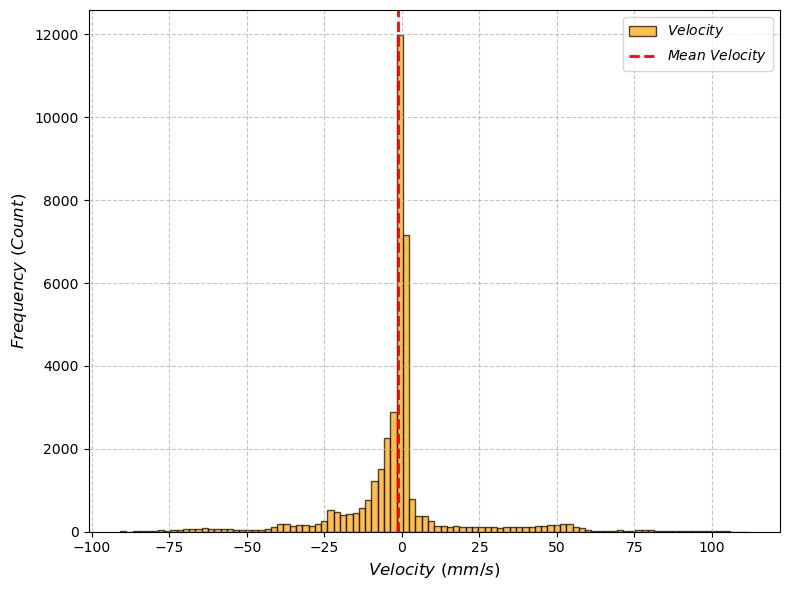

In [156]:
def plot_velocity_distribution(folder):
    all_velocities = []
    
    print("Aggregating velocity data from all files (converting to mm/s)...")
    
    for s in range(101, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(folder, filename)
            
            if not os.path.exists(file_path):
                continue
                
            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()
            
            if 't_rel(s)' not in df.columns:
                continue
                
            # Trim the last 0.5 seconds
            max_time = df['t_rel(s)'].max()
            df = df[df['t_rel(s)'] <= (max_time - 0.5)]
            
            # Extract and convert to mm/s if necessary
            if 'Velocity (mm/s)' in df.columns:
                vel_data = df['Velocity (mm/s)'].dropna().values
                all_velocities.extend(vel_data)
            # elif 'Velocity (m/s)' in df.columns:
            #     vel_data = df['Velocity (m/s)'].dropna().values * 1000.0  # Convert to mm/s
            #     all_velocities.extend(vel_data)

    velocities = np.array(all_velocities)
    
    if len(velocities) == 0:
        print("Error: No valid velocity data found.")
        return
        
    print(f"Plotting distribution for {len(velocities):,} data points...")

    # ---------------------------------------------------------
    # Plotting the Distribution
    # ---------------------------------------------------------
    fig, ax = plt.subplots(figsize=(8, 6))
    
    counts, bins, patches = ax.hist(
        velocities, 
        bins=100, 
        color='orange', 
        edgecolor='black', 
        alpha=0.7, 
        label="$ Velocity $"
    )
    
    ax.set_xlabel("$ Velocity~(mm/s) $", color='black', fontsize=12)
    ax.set_ylabel("$ Frequency~(Count) $", color='black', fontsize=12)
    
    mean_vel = np.mean(velocities)
    ax.axvline(mean_vel, color='red', linestyle='--', linewidth=2, label="$ Mean~Velocity $")
    
    ax.tick_params(axis='both', labelcolor='black', labelsize=10)
    ax.legend(loc='upper right')
    ax.grid(True, linestyle='--', alpha=0.7)
    
    plt.tight_layout()
    
    out_name = "Dataset_Velocity_Distribution_mms.png"
    plt.savefig(out_name, dpi=150, bbox_inches='tight')
    plt.show()

# Example usage:
plot_velocity_distribution(folder)

In [184]:
def group_cases_by_max_velocity(folder):
    # Initialize groups
    high_vel = []    # > 75 mm/s
    mid_vel = []     # 50 to 75 mm/s
    low_vel = []     # < 50 mm/s
    
    print("Scanning files and calculating maximum velocities...")
    
    for s in range(101, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(folder, filename)
            
            if not os.path.exists(file_path):
                continue
                
            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()
            
            if 't_rel(s)' not in df.columns:
                continue
                
            # Trim the last 0.5 seconds
            max_time = df['t_rel(s)'].max()
            df = df[df['t_rel(s)'] <= (max_time - 0.5)]
            
            # Determine max velocity in mm/s
            if 'Velocity (mm/s)' in df.columns:
                max_v = df['Velocity (mm/s)'].max()
            elif 'Velocity (m/s)' in df.columns:
                max_v = df['Velocity (m/s)'].max() * 1000.0
            else:
                continue
                
            # Ignore NaNs just in case a file has an empty column
            if pd.isna(max_v):
                continue
                
            # Categorize the file based on its maximum velocity
            if max_v > 80.0:
                high_vel.append((filename, max_v))
            elif max_v < 55.0:
                low_vel.append((filename, max_v))
            else:
                mid_vel.append((filename, max_v))

    # Print summary of the groupings
    print(f"\n--- Velocity Groupings Summary ---")
    print(f"High Velocity (> 80 mm/s): {len(high_vel)} files")
    print(f"Mid Velocity (55-80 mm/s): {len(mid_vel)} files")
    print(f"Low Velocity (< 55 mm/s): {len(low_vel)} files")
    
    # Example of how to access the lists (printing the first 5 of each for verification)
    print("\nSample High Velocity files:", [f[0] for f in high_vel[:5]])
    print("Sample Mid Velocity files:", [f[0] for f in mid_vel[:5]])
    print("Sample Low Velocity files:", [f[0] for f in low_vel[:5]])
    
    return high_vel, mid_vel, low_vel

# Example usage:
high_cases, mid_cases, low_cases = group_cases_by_max_velocity(folder)

Scanning files and calculating maximum velocities...

--- Velocity Groupings Summary ---
High Velocity (> 80 mm/s): 37 files
Mid Velocity (55-80 mm/s): 37 files
Low Velocity (< 55 mm/s): 33 files

Sample High Velocity files: ['S116P001.csv', 'S116P003.csv', 'S116P004.csv', 'S116P005.csv', 'S117P001.csv']
Sample Mid Velocity files: ['S101P001.csv', 'S101P002.csv', 'S101P003.csv', 'S101P004.csv', 'S101P005.csv']
Sample Low Velocity files: ['S104P001.csv', 'S104P002.csv', 'S104P003.csv', 'S105P002.csv', 'S105P003.csv']


In [192]:
def calculate_group_rmse(folder):
    # Storage for the aggregated firing rate data per group
    groups = {
        'High (>80 mm/s)': {'target': [], 'global': [], 'split': []},
        'Mid (55-80 mm/s)': {'target': [], 'global': [], 'split': []},
        'Low (<55 mm/s)': {'target': [], 'global': [], 'split': []}
    }
    
    print("Processing files and calculating model errors...")
    
    for s in range(101, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(folder, filename)
            
            if not os.path.exists(file_path):
                continue
                
            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()
            
            req_cols = ['t_rel(s)', 'LW Filtered (V)', 'dv/dt (V/s)', 'Type Ia Firing Rate']
            if not all(col in df.columns for col in req_cols):
                continue
                
            # Trim the last 0.5 seconds
            max_time = df['t_rel(s)'].max()
            df = df[df['t_rel(s)'] <= (max_time - 0.5)].dropna(subset=req_cols)
            
            # Determine maximum velocity (convert to mm/s if needed)
            if 'Velocity (mm/s)' in df.columns:
                max_v = df['Velocity (mm/s)'].max()
            elif 'Velocity (m/s)' in df.columns:
                max_v = df['Velocity (m/s)'].max() * 1000.0
            else:
                continue
                
            if pd.isna(max_v):
                continue
                
            # Route to correct group key
            if max_v > 80.0:
                group_key = 'High (>80 mm/s)'
            elif max_v < 55.0:
                group_key = 'Low (<55 mm/s)'
            else:
                group_key = 'Mid (55-80 mm/s)'
                
            # Extract data
            V = df['LW Filtered (V)'].values
            dvdt = df['dv/dt (V/s)'].values
            target_fr = df['Type Ia Firing Rate'].values
            
            # 1. Calculate Global Model
            global_fr = 38.118 * (np.sign(dvdt) * np.abs(dvdt)**0.546) + 77.298 * V + 72.484
            
            # 2. Calculate Split Model
            fr_inf = 49.555 * (np.sign(dvdt) * np.abs(dvdt)**0.390) + 88.644 * V + 55.313
            fr_def =  42.297 * (np.sign(dvdt) * np.abs(dvdt)**0.622) + 67.602 * V + 79.182 
            split_fr = np.where(dvdt > 0, fr_inf, fr_def)
            
            # Append to group storage
            groups[group_key]['target'].extend(target_fr)
            groups[group_key]['global'].extend(global_fr)
            groups[group_key]['split'].extend(split_fr)

    # Calculate and print the final RMSE for each group
    print("\n--- Model RMSE by Velocity Group ---")
    
    for key, data in groups.items():
        if len(data['target']) == 0:
            print(f"{key}: No data found.")
            continue
            
        target = np.array(data['target'])
        pred_g = np.array(data['global'])
        pred_s = np.array(data['split'])
        
        rmse_g = np.sqrt(np.mean((target - pred_g)**2))
        rmse_s = np.sqrt(np.mean((target - pred_s)**2))
        
        print(f"{key} (Based on {len(target):,} points):")
        print(f"  Global Model RMSE : {rmse_g:.2f} Hz")
        print(f"  Split Model RMSE  : {rmse_s:.2f} Hz\n")

# Example usage:
calculate_group_rmse(folder)

Processing files and calculating model errors...

--- Model RMSE by Velocity Group ---
High (>80 mm/s) (Based on 4,406 points):
  Global Model RMSE : 9.07 Hz
  Split Model RMSE  : 8.99 Hz

Mid (55-80 mm/s) (Based on 17,271 points):
  Global Model RMSE : 7.40 Hz
  Split Model RMSE  : 6.57 Hz

Low (<55 mm/s) (Based on 16,791 points):
  Global Model RMSE : 8.70 Hz
  Split Model RMSE  : 7.38 Hz



In [40]:
def calculate_group_rmse(folder):
    # Coefficients for Rate Model: FR = C * (dv/dt) + D
    C_rate_opt = 30.992407
    D_rate_opt = 107.270551

    # Coefficients for Laplace Transfer Function Model H_total(s)
    A_laplace, B_laplace, E_laplace, D_laplace = 4.3, 0.6, 2.0, 82.0
    tau_laplace = 0.00051
    C0_raw, C1_raw, C2_raw, C3_raw = 8.1934, 9.1884, 1.5844, 0.0783
    alpha_dyn = 1.4121  # Dynamic scale factor

    # Storage for the aggregated firing rate data per group
    groups = {
        'High (>80 mm/s)':   {'target': [], 'rate': [], 'split': [], 'global': [], 'laplace': []},
        'Mid (55-80 mm/s)':  {'target': [], 'rate': [], 'split': [], 'global': [], 'laplace': []},
        'Low (<55 mm/s)':    {'target': [], 'rate': [], 'split': [], 'global': [], 'laplace': []}
    }

    # Global storage pooled across ALL files and velocity groups
    all_target = []
    all_rate = []
    all_split = []
    all_global = []
    all_laplace = []

    print("Processing dataset files and calculating overall and velocity-grouped RMSEs...")

    for s in range(101, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(folder, filename)

            if not os.path.exists(file_path):
                continue

            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()

            req_cols = ['t_rel(s)', 'LW Filtered (V)', 'dv/dt (V/s)', 'Type Ia Firing Rate']
            if not all(col in df.columns for col in req_cols):
                continue

            # Trim the last 0.5 seconds globally
            max_time = df['t_rel(s)'].max()
            df = df[df['t_rel(s)'] <= (max_time - 0.5)].dropna(subset=req_cols).copy()

            if df.empty or len(df) < 32:
                continue

            # Determine maximum velocity
            if 'Velocity (mm/s)' in df.columns:
                max_v = df['Velocity (mm/s)'].max()
            elif 'Velocity (m/s)' in df.columns:
                max_v = df['Velocity (m/s)'].max() * 1000.0
            else:
                continue

            if pd.isna(max_v):
                continue

            # Route to correct velocity group
            if max_v > 80.0:
                group_key = 'High (>80 mm/s)'
            elif max_v < 55.0:
                group_key = 'Low (<55 mm/s)'
            else:
                group_key = 'Mid (55-80 mm/s)'

            t = df['t_rel(s)'].values
            V = df['LW Filtered (V)'].values
            dvdt = df['dv/dt (V/s)'].values
            target_fr = df['Type Ia Firing Rate'].values

            dt = t[1] - t[0] if len(t) > 1 else 0.001

            # -------------------------------------------------------------
            # 1. Rate Model
            # -------------------------------------------------------------
            rate_fr = C_rate_opt * dvdt + D_rate_opt

            # -------------------------------------------------------------
            # 2. Split Hysteresis Model
            # -------------------------------------------------------------
            fr_inf = 49.555 * (np.sign(dvdt) * np.abs(dvdt)**0.390) + 88.644 * V + 55.313
            fr_def = 42.297 * (np.sign(dvdt) * np.abs(dvdt)**0.622) + 67.602 * V + 79.182
            split_fr = np.where(dvdt > 0, fr_inf, fr_def)

            # -------------------------------------------------------------
            # 3. Global Model
            # -------------------------------------------------------------
            global_fr = 38.118 * (np.sign(dvdt) * np.abs(dvdt)**0.546) + 77.298 * V + 72.484

            # -------------------------------------------------------------
            # 4. Laplace s-Domain Model (Symmetric 150ms Edge-Padding)
            # -------------------------------------------------------------
            pad_samples = int(0.15 / dt)
            V_padded = np.pad(V, (pad_samples, pad_samples), mode='edge')
            N_padded = len(V_padded)

            V0 = np.mean(V) + 0.0055
            Kv = C1_raw + 2.0 * C2_raw * V0
            C0_eff = C0_raw - C2_raw * (V0**2)

            freqs = np.fft.fftfreq(N_padded, d=dt)
            omega = 2.0 * np.pi * freqs
            s_complex = 1j * omega
            s_safe = np.copy(s_complex)
            if s_safe[0] == 0:
                s_safe[0] = 1e-12

            den_sensor = tau_laplace * s_safe + 1.0
            num_dyn = (A_laplace * Kv * (s_safe**B_laplace) +
                       A_laplace * C3_raw * (s_safe**(B_laplace + 1.0)) +
                       E_laplace * C3_raw * s_safe)
            num_stat = E_laplace * Kv

            H_total = (alpha_dyn * num_dyn + num_stat) / den_sensor
            V_fft = np.fft.fft(V_padded)
            FR_dyn_padded = np.real(np.fft.ifft(H_total * V_fft))

            t_rel_padded = np.linspace(-0.15, (len(t) - 1) * dt + 0.15, N_padded) + 0.15
            L_offset_padded = C0_eff * (1.0 - np.exp(-t_rel_padded / tau_laplace))
            FR_laplace_padded = np.maximum(0, FR_dyn_padded + E_laplace * L_offset_padded + D_laplace)

            # Slice off symmetric edge padding
            laplace_fr = FR_laplace_padded[pad_samples:-pad_samples]

            # -------------------------------------------------------------
            # Append to Group and Pooled Global Arrays
            # -------------------------------------------------------------
            groups[group_key]['target'].extend(target_fr)
            groups[group_key]['rate'].extend(rate_fr)
            groups[group_key]['split'].extend(split_fr)
            groups[group_key]['global'].extend(global_fr)
            groups[group_key]['laplace'].extend(laplace_fr)

            all_target.extend(target_fr)
            all_rate.extend(rate_fr)
            all_split.extend(split_fr)
            all_global.extend(global_fr)
            all_laplace.extend(laplace_fr)

    # -------------------------------------------------------------
    # Output 1: Velocity Group Breakdown
    # -------------------------------------------------------------
    print("\n" + "=" * 65)
    print("                MODEL RMSE BY VELOCITY GROUP                ")
    print("=" * 65)

    for key, data in groups.items():
        if len(data['target']) == 0:
            print(f"{key}: No data found.\n")
            continue

        tgt = np.array(data['target'])
        p_rate = np.array(data['rate'])
        p_split = np.array(data['split'])
        p_glob = np.array(data['global'])
        p_lap = np.array(data['laplace'])

        rmse_r = np.sqrt(np.mean((tgt - p_rate)**2))
        rmse_s = np.sqrt(np.mean((tgt - p_split)**2))
        rmse_g = np.sqrt(np.mean((tgt - p_glob)**2))
        rmse_l = np.sqrt(np.mean((tgt - p_lap)**2))

        print(f"--- {key} ({len(tgt):,} points) ---")
        print(f"  Rate Model RMSE    : {rmse_r:.2f} Hz")
        print(f"  Split Model RMSE   : {rmse_s:.2f} Hz")
        print(f"  Global Model RMSE  : {rmse_g:.2f} Hz")
        print(f"  Laplace Model RMSE : {rmse_l:.2f} Hz\n")

    # -------------------------------------------------------------
    # Output 2: Total Overall Dataset RMSE across ALL Velocities
    # -------------------------------------------------------------
    if len(all_target) > 0:
        tot_tgt = np.array(all_target)
        tot_rate = np.array(all_rate)
        tot_split = np.array(all_split)
        tot_glob = np.array(all_global)
        tot_lap = np.array(all_laplace)

        tot_rmse_r = np.sqrt(np.mean((tot_tgt - tot_rate)**2))
        tot_rmse_s = np.sqrt(np.mean((tot_tgt - tot_split)**2))
        tot_rmse_g = np.sqrt(np.mean((tot_tgt - tot_glob)**2))
        tot_rmse_l = np.sqrt(np.mean((tot_tgt - tot_lap)**2))

        print("=" * 65)
        print("          OVERALL DATASET RMSE (POOLED ACROSS ALL FILES)     ")
        print("=" * 65)
        print(f"Total Evaluated Points : {len(tot_tgt):,}")
        print(f"Rate Model RMSE        : {tot_rmse_r:.2f} Hz")
        print(f"Split Model RMSE       : {tot_rmse_s:.2f} Hz")
        print(f"Global Model RMSE      : {tot_rmse_g:.2f} Hz")
        print(f"Laplace Model RMSE     : {tot_rmse_l:.2f} Hz")
        print("=" * 65 + "\n")

# Run calculation
calculate_group_rmse(folder)

Processing dataset files and calculating overall and velocity-grouped RMSEs...

                MODEL RMSE BY VELOCITY GROUP                
--- High (>80 mm/s) (4,406 points) ---
  Rate Model RMSE    : 20.57 Hz
  Split Model RMSE   : 8.99 Hz
  Global Model RMSE  : 9.07 Hz
  Laplace Model RMSE : 15.79 Hz

--- Mid (55-80 mm/s) (17,271 points) ---
  Rate Model RMSE    : 17.68 Hz
  Split Model RMSE   : 6.57 Hz
  Global Model RMSE  : 7.40 Hz
  Laplace Model RMSE : 9.73 Hz

--- Low (<55 mm/s) (16,791 points) ---
  Rate Model RMSE    : 16.82 Hz
  Split Model RMSE   : 7.38 Hz
  Global Model RMSE  : 8.70 Hz
  Laplace Model RMSE : 8.18 Hz

          OVERALL DATASET RMSE (POOLED ACROSS ALL FILES)     
Total Evaluated Points : 38,468
Rate Model RMSE        : 17.67 Hz
Split Model RMSE       : 7.24 Hz
Global Model RMSE      : 8.19 Hz
Laplace Model RMSE     : 10.01 Hz



In [200]:
def plot_peak_velocity_windows(input_folder):
    # 1. Setup Categorized Output Folders
    out_dirs = {
        'high': "Peaks_High_gt80",
        'mid': "Peaks_Mid_55_to_80",
        'low': "Peaks_Low_lt55"
    }
    for folder in out_dirs.values():
        os.makedirs(folder, exist_ok=True)
        
    print("Scanning files and generating peak window plots...")
    processed_count = 0

    for s in range(101, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(input_folder, filename)
            
            if not os.path.exists(file_path):
                continue
                
            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()
            
            if 't_rel(s)' not in df.columns:
                continue

            # Trim the last 0.5 seconds globally
            max_time_global = df['t_rel(s)'].max()
            df = df[df['t_rel(s)'] <= (max_time_global - 0.5)].copy()
            
            if df.empty:
                continue
                
            # Identify and standardize velocity to mm/s
            if 'Velocity (mm/s)' in df.columns:
                df['Vel_Standard'] = df['Velocity (mm/s)']
                len_col_name = 'Length filtered (mm)' if 'Length filtered (mm)' in df.columns else 'Length filtered (m)'
                len_label = "$ Displacement~(mm) $" if 'mm' in len_col_name else "$ Displacement~(m) $"
            elif 'Velocity (m/s)' in df.columns:
                df['Vel_Standard'] = df['Velocity (m/s)'] * 1000.0
                len_col_name = 'Length filtered (m)' if 'Length filtered (m)' in df.columns else 'Length filtered (mm)'
                len_label = "$ Displacement~(m) $" if 'm' in len_col_name else "$ Displacement~(mm) $"
            else:
                continue
                
            vol_col = 'LW Filtered (V)' if 'LW Filtered (V)' in df.columns else 'LW RAW (V)'
            
            # 2. Find Peak Velocity (Ignoring the last 15% of the run)
            search_limit_time = df['t_rel(s)'].max() * 0.85
            df_search_window = df[df['t_rel(s)'] <= search_limit_time]
            
            if df_search_window['Vel_Standard'].isna().all():
                continue
                
            peak_idx = df_search_window['Vel_Standard'].idxmax()
            peak_time = df.loc[peak_idx, 't_rel(s)']
            max_v = df.loc[peak_idx, 'Vel_Standard']
            
            # 3. Extract the 4-Second Window (+/- 2 seconds)
            window_mask = (df['t_rel(s)'] >= (peak_time - 0.5)) & (df['t_rel(s)'] <= (peak_time + 1.0))
            df_win = df[window_mask].copy()
            
            # --- UPDATE: Shift the time array so it starts exactly at 0 ---
            time = df_win['t_rel(s)'] - df_win['t_rel(s)'].min()
            
            # 4. Determine Target Folder
            if max_v > 80.0:
                target_folder = out_dirs['high']
            elif max_v < 55.0:
                target_folder = out_dirs['low']
            else:
                target_folder = out_dirs['mid']
                
            # 5. Calculate Models & Window-Specific Error
            nrmse_global, nrmse_split = None, None
            if vol_col in df_win.columns and 'dv/dt (V/s)' in df_win.columns:
                V = df_win[vol_col]
                dvdt = df_win['dv/dt (V/s)']
                
                df_win['FR Global'] = 38.118 * (np.sign(dvdt) * np.abs(dvdt)**0.546) + 77.298 * V + 72.484

                inf_A, inf_B, inf_C, inf_D = 49.555, 0.390, 88.644, 55.313
                def_A, def_B, def_C, def_D = 42.297, 0.622, 67.602, 79.182
                
                fr_inflation = inf_A * (np.sign(dvdt) * np.abs(dvdt)**inf_B) + inf_C * V + inf_D
                fr_deflation = def_A * (np.sign(dvdt) * np.abs(dvdt)**def_B) + def_C * V + def_D
                df_win['FR Split'] = np.where(dvdt > 0, fr_inflation, fr_deflation)

                if 'Type Ia Firing Rate' in df_win.columns:
                    target = df_win['Type Ia Firing Rate']
                    target_range = target.max() - target.min()
                    
                    if target_range > 0:
                        valid_g = target.notna() & df_win['FR Global'].notna()
                        if valid_g.any():
                            rmse_g = np.sqrt(np.mean((target[valid_g] - df_win.loc[valid_g, 'FR Global'])**2))
                            nrmse_global = (rmse_g / target_range) * 100
                            
                        valid_s = target.notna() & df_win['FR Split'].notna()
                        if valid_s.any():
                            rmse_s = np.sqrt(np.mean((target[valid_s] - df_win.loc[valid_s, 'FR Split'])**2))
                            nrmse_split = (rmse_s / target_range) * 100

            # 6. Plotting
            fig, axs = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
            
            # --- Subplot 1: Length & Voltage ---
            ax1 = axs[0]
            ax1.plot(time, df_win.get(len_col_name, []), color='blue', label="$ Length$", linewidth=2)
            ax1.set_ylabel(len_label, color='black', fontsize=12)
            ax1.tick_params(axis='both', labelcolor='black')
            ax1.grid(True, linestyle='--', alpha=0.7)
            
            ax1_twin = ax1.twinx()
            ax1_twin.plot(time, df_win.get(vol_col, []), color='green', label="$ Voltage $", alpha=0.7)
            ax1_twin.set_ylabel("$ Voltage~(V) $", color='black', fontsize=12)
            ax1_twin.tick_params(axis='both', labelcolor='black')
            
            l1, lab1 = ax1.get_legend_handles_labels()
            l2, lab2 = ax1_twin.get_legend_handles_labels()
            ax1.legend(l1 + l2, lab1 + lab2, loc="upper right")

            # --- Subplot 2: Velocity & dv/dt ---
            ax2 = axs[1]
            ax2.plot(time, df_win['Vel_Standard'], color='orange', label="$ Velocity $", linewidth=1.5)
            ax2.set_ylabel("$ Velocity~(mms^{-1}) $", color='black', fontsize=12)
            ax2.tick_params(axis='both', labelcolor='black')
            ax2.grid(True, linestyle='--', alpha=0.7)
            
            ax2_twin = ax2.twinx()
            ax2_twin.plot(time, df_win.get('dv/dt (V/s)', []), color='red', label="$ dv/dt $", alpha=0.7)
            ax2_twin.set_ylabel("$ dv/dt~(Vs6{-1}) $", color='black', fontsize=12)
            ax2_twin.tick_params(axis='both', labelcolor='black')
            
            l3, lab3 = ax2.get_legend_handles_labels()
            l4, lab4 = ax2_twin.get_legend_handles_labels()
            ax2.legend(l3 + l4, lab3 + lab4, loc="upper right")

            # --- Subplot 3: Firing Rates ---
            ax3 = axs[2]
            if 'Type Ia Firing Rate' in df_win.columns:
                ax3.plot(time, df_win['Type Ia Firing Rate'], color='purple', label="$ Target~FR $", linewidth=2.5)
                
            if 'FR Global' in df_win.columns:
                g_label = f"$ Global~Model~(NRMSE:~{nrmse_global:.1f}\\%) $" if nrmse_global is not None else "$ Global~Model $"
                ax3.plot(time, df_win['FR Global'], color='cyan', linestyle=':', label=g_label, linewidth=1.5)
                
            if 'FR Split' in df_win.columns:
                s_label = f"$ Split~Model~(NRMSE:~{nrmse_split:.1f}\\%) $" if nrmse_split is not None else "$ Split~Model $"
                ax3.plot(time, df_win['FR Split'], color='magenta', linestyle='--', label=s_label, linewidth=1.5)
                
            ax3.set_ylabel("$ Firing~Rate~(s^{-1}) $", color='black', fontsize=12)
            ax3.set_xlabel("$ Time~(s) $", color='black', fontsize=12)
            ax3.tick_params(axis='both', labelcolor='black')
            ax3.legend(loc="upper right")
            ax3.grid(True, linestyle='--', alpha=0.7)

            plt.tight_layout()
            
            # Save Output
            out_name = filename.replace('.csv', f'_PeakWin_{max_v:.1f}mms.png')
            out_path = os.path.join(target_folder, out_name)
            plt.savefig(out_path, dpi=150, bbox_inches='tight')
            plt.close(fig)
            
            processed_count += 1
            print(f"Saved: {out_path}")
            
    print(f"\nProcessing complete. Generated {processed_count} peak window plots.")

plot_peak_velocity_windows(folder)

Scanning files and generating peak window plots...
Saved: Peaks_Mid_55_to_80\S101P001_PeakWin_57.7mms.png
Saved: Peaks_Mid_55_to_80\S101P002_PeakWin_58.4mms.png
Saved: Peaks_Mid_55_to_80\S101P003_PeakWin_61.3mms.png
Saved: Peaks_Mid_55_to_80\S101P004_PeakWin_59.2mms.png
Saved: Peaks_Mid_55_to_80\S101P005_PeakWin_59.3mms.png
Saved: Peaks_Mid_55_to_80\S102P001_PeakWin_61.6mms.png
Saved: Peaks_Mid_55_to_80\S102P003_PeakWin_62.5mms.png
Saved: Peaks_Mid_55_to_80\S102P005_PeakWin_59.0mms.png
Saved: Peaks_Mid_55_to_80\S103P001_PeakWin_58.4mms.png
Saved: Peaks_Mid_55_to_80\S103P002_PeakWin_60.4mms.png
Saved: Peaks_Mid_55_to_80\S103P003_PeakWin_59.3mms.png
Saved: Peaks_Mid_55_to_80\S103P004_PeakWin_59.2mms.png
Saved: Peaks_Mid_55_to_80\S103P005_PeakWin_57.3mms.png
Saved: Peaks_Low_lt55\S104P001_PeakWin_49.3mms.png
Saved: Peaks_Low_lt55\S104P002_PeakWin_51.8mms.png
Saved: Peaks_Low_lt55\S104P003_PeakWin_54.2mms.png
Saved: Peaks_Mid_55_to_80\S104P005_PeakWin_68.5mms.png
Saved: Peaks_Low_lt55\S105

### Figure for publication

In [30]:
def generate_publication_figure(input_folder):
    # 1. Configuration for specific files and their plotting windows (pre-peak and post-peak in seconds)
    plot_config = {
        "S117P001.csv": {"pre_peak": 0.35, "post_peak": 0.4}, #fast
        "S121P003.csv": {"pre_peak": 0.3, "post_peak": 1.0}, #medium
        "S107P001.csv": {"pre_peak": 0.4, "post_peak": 1.0}  #slow
    }
    
    # 3x3 Grid, sharing X across columns and Y across rows
    fig, axs = plt.subplots(3, 3, figsize=(14, 10), sharex='col', sharey='row')
    
    for col_idx, (filename, window) in enumerate(plot_config.items()):
        file_path = os.path.join(input_folder, filename)
        
        if not os.path.exists(file_path):
            print(f"Warning: {filename} not found.")
            continue
            
        df = pd.read_csv(file_path)
        df.columns = df.columns.str.strip()
        
        # Trim the last 0.5 seconds globally
        max_time_global = df['t_rel(s)'].max()
        df = df[df['t_rel(s)'] <= (max_time_global - 0.5)].copy()
        
        # Standardize Velocity and Length
        if 'Velocity (mm/s)' in df.columns:
            df['Vel_Standard'] = df['Velocity (mm/s)']
            len_col = 'Length filtered (mm)' if 'Length filtered (mm)' in df.columns else 'Length filtered (m)'
            len_label = "$ Displacement~(mm) $" if 'mm' in len_col else "$ Displacement~(m) $"
        elif 'Velocity (m/s)' in df.columns:
            df['Vel_Standard'] = df['Velocity (m/s)'] * 1000.0
            len_col = 'Length filtered (m)' if 'Length filtered (m)' in df.columns else 'Length filtered (mm)'
            len_label = "$ Displacement~(m) $" if 'm' in len_col else "$ Displacement~(mm) $"
            
        vol_col = 'LW Filtered (V)' if 'LW Filtered (V)' in df.columns else 'LW RAW (V)'
        
        # Find Peak Velocity (Ignoring last 15%)
        search_limit = df['t_rel(s)'].max() * 0.85
        df_search = df[df['t_rel(s)'] <= search_limit]
        peak_idx = df_search['Vel_Standard'].idxmax()
        peak_time = df.loc[peak_idx, 't_rel(s)']
        
        # Extract Custom Window for this specific file
        win_mask = (df['t_rel(s)'] >= (peak_time - window['pre_peak'])) & (df['t_rel(s)'] <= (peak_time + window['post_peak']))
        df_win = df[win_mask].copy()
        
        # Shift time to start exactly at 0 for the extracted window
        time = df_win['t_rel(s)'] - df_win['t_rel(s)'].min()
        
        # Calculate Models with updated coefficients
        V = df_win[vol_col]
        dvdt = df_win['dv/dt (V/s)']
        target = df_win['Type Ia Firing Rate']
        
        df_win['FR Global'] = 38.118 * (np.sign(dvdt) * np.abs(dvdt)**0.546) + 77.298 * V + 72.484
        
        inf_A, inf_B, inf_C, inf_D = 49.555, 0.390, 88.644, 55.313
        def_A, def_B, def_C, def_D = 42.297, 0.622, 67.602, 79.182
        
        fr_inf = inf_A * (np.sign(dvdt) * np.abs(dvdt)**inf_B) + inf_C * V + inf_D
        fr_def = def_A * (np.sign(dvdt) * np.abs(dvdt)**def_B) + def_C * V + def_D
        df_win['FR Split'] = np.where(dvdt > 0, fr_inf, fr_def)
        
        # Calculate Standard RMSE
        rmse_global = np.sqrt(np.mean((target - df_win['FR Global'])**2))
        rmse_split = np.sqrt(np.mean((target - df_win['FR Split'])**2))
        
        # ==========================================
        # Row 1: Length Profiles
        # ==========================================
        ax1 = axs[0, col_idx]
        ax1.plot(time, df_win[len_col], color='blue', linewidth=2, label="$ Length $")
        axs[0,0].set_title("$ Fast~(110~mm~s^{-1} )$", fontsize=16) 
        axs[0,1].set_title("$ Medium~(80~mm~s^{-1} )$", fontsize=16) 
        axs[0,2].set_title("$ Slow~(50~mm~s^{-1} )$", fontsize=16) 

        ax1.grid(True, linestyle='--', alpha=0.7)
        if col_idx == 0:
            ax1.set_ylabel(len_label, fontsize=16)
        ax1.tick_params(axis='both', labelsize=16)
        ax1.legend(fontsize = 16, loc = "lower center")
            
       # ==========================================
        # Row 2: Target vs Global Model
        # ==========================================
        ax2 = axs[1, col_idx]
        ax2.plot(time, target, color='purple', linewidth=2.5)
        g_label = f"$RMSE:{rmse_global:.1f} $"
        ax2.plot(time, df_win['FR Global'], color='g', linestyle=':', linewidth=3, label=g_label)
        ax2.grid(True, linestyle='--', alpha=0.7)
        ax2.legend(loc="upper right", fontsize=14)
        ax2.set_ylim(0, 200)
        ax2.set_yticks([0, 100, 200])

        # Capture the main legend
        main_leg2 = ax2.legend(loc="upper right", fontsize=14)
        
        if col_idx == 0:
            ax2.set_ylabel("$ Firing~Rate~(s^{-1}) $", fontsize=16)
            # Add Row Title to the far left
            ax2.annotate("$ Global~model $", xy=(0, 0.5), xycoords='axes fraction', 
                         xytext=(75, -80), textcoords='offset points', 
                         rotation=0, va='center', ha='center', fontsize=16)

        if col_idx == 1:
            custom_line = [Line2D([0], [0], color='purple', lw=2.5)]
            # markerfirst=False puts the text before the line segment
            prochazka_leg2 = ax2.legend(custom_line, ['$ Prochazka $'], loc='lower left', 
                                        frameon=False, fontsize=14, markerfirst=True)
            # Matplotlib drops the first legend when a second is called, so we add it back manually
            ax2.add_artist(main_leg2)
            
        ax2.tick_params(axis='both', labelsize=16)
            
        # ==========================================
        # Row 3: Target vs Split Model
        # ==========================================
        ax3 = axs[2, col_idx]
        ax3.plot(time, target, color='purple', linewidth=2.5)
        s_label = f"$RMSE:{rmse_split:.1f}$"
        ax3.plot(time, df_win['FR Split'], color='magenta', linestyle='--', linewidth=2, label=s_label)
        ax3.grid(True, linestyle='--', alpha=0.7)
        # Capture the main legend
        main_leg3 = ax3.legend(loc="upper right", fontsize=14)
        ax3.legend(loc="upper right", fontsize=14)
        ax3.set_xlabel("$ Time~(s) $", fontsize=16)
        ax3.set_ylim(0, 200)
        ax3.set_yticks([0, 100, 200])
        
        if col_idx == 0:
            ax3.set_ylabel("$ Firing~Rate~(s^{-1}) $", fontsize=16)
            # Add Row Title to the far left
            ax3.annotate("$ Split~model $", xy=(0, 0.5), xycoords='axes fraction', 
                         xytext=(70, -80), textcoords='offset points', 
                         rotation=0, va='center', ha='center', fontsize=16)

        if col_idx == 1:
            prochazka_leg3 = ax3.legend(custom_line, ['$ Prochazka $'], loc='lower left', 
                                        frameon=False, fontsize=14, markerfirst=True)
            ax3.add_artist(main_leg3)
            
        ax3.tick_params(axis='both', labelsize=16)

    # Adjust layout to remove excessive whitespace and save at high DPI for publication
    plt.tight_layout()
    out_name = "Publication_3x3_Figure.png"
    # plt.plot();
    plt.savefig(out_name, dpi=300, bbox_inches='tight')
    print(f"Saved publication figure: {out_name}")
    plt.close(fig)


generate_publication_figure(folder)

Saved publication figure: Publication_3x3_Figure.png


In [38]:
def generate_publication_5x3_figure(input_folder):
  # 1. Configuration for specific files and their plotting windows (pre-peak and post-peak in seconds)
  plot_config = {
      "S117P001.csv": {"pre_peak": 0.35, "post_peak": 0.4},  # fast
      "S121P003.csv": {"pre_peak": 0.3, "post_peak": 1.0},  # medium
      "S107P001.csv": {"pre_peak": 0.4, "post_peak": 1.0},  # slow
  }

  # Coefficients for Model 2 Rate (from peak-window linear optimization)
  C_rate_opt = 30.992407
  D_rate_opt = 107.270551

  # Coefficients for Laplace Transfer Function Model H_total(s)
  A_laplace, B_laplace, E_laplace, D_laplace = 4.3, 0.6, 2.0, 82.0
  tau_laplace = 0.00051
  C0_raw, C1_raw, C2_raw, C3_raw = 8.1934, 9.1884, 1.5844, 0.0783
  alpha_dyn = 1.4121  # Dynamic scale factor

  # 5x3 Grid, sharing X across columns and Y across rows
  fig, axs = plt.subplots(5, 3, figsize=(14, 15), sharex="col", sharey="row")

  custom_line = [Line2D([0], [0], color="purple", lw=2.5)]

  for col_idx, (filename, window) in enumerate(plot_config.items()):
    file_path = os.path.join(input_folder, filename)

    if not os.path.exists(file_path):
      print(f"Warning: {filename} not found.")
      continue

    df = pd.read_csv(file_path)
    df.columns = df.columns.str.strip()

    # Trim the last 0.5 seconds globally
    max_time_global = df["t_rel(s)"].max()
    df = df[df["t_rel(s)"] <= (max_time_global - 0.5)].copy()

    # Standardize Velocity and Length
    if "Velocity (mm/s)" in df.columns:
      df["Vel_Standard"] = df["Velocity (mm/s)"]
      len_col = (
          "Length filtered (mm)"
          if "Length filtered (mm)" in df.columns
          else "Length filtered (m)"
      )
      len_label = (
          "$ Displacement~(mm) $" if "mm" in len_col else "$ Displacement~(m) $"
      )
    elif "Velocity (m/s)" in df.columns:
      df["Vel_Standard"] = df["Velocity (m/s)"] * 1000.0
      len_col = (
          "Length filtered (m)"
          if "Length filtered (m)" in df.columns
          else "Length filtered (mm)"
      )
      len_label = (
          "$ Displacement~(m) $" if "m" in len_col else "$ Displacement~(mm) $"
      )

    vol_col = (
        "LW Filtered (V)" if "LW Filtered (V)" in df.columns else "LW RAW (V)"
    )

    # Find Peak Velocity (Ignoring last 15%)
    search_limit = df["t_rel(s)"].max() * 0.85
    df_search = df[df["t_rel(s)"] <= search_limit]
    peak_idx = df_search["Vel_Standard"].idxmax()
    peak_time = df.loc[peak_idx, "t_rel(s)"]

    # -------------------------------------------------------------
    # 2. Extract WIDE Window (+0.15s buffer on both ends for FFT)
    # -------------------------------------------------------------
    buf = 0.15
    win_mask_wide = (
        df["t_rel(s)"] >= (peak_time - window["pre_peak"] - buf)
    ) & (df["t_rel(s)"] <= (peak_time + window["post_peak"] + buf))
    df_wide = df[win_mask_wide].copy()

    t_wide = df_wide["t_rel(s)"].values
    V_wide = df_wide[vol_col].values
    dvdt_wide = df_wide["dv/dt (V/s)"].values
    target_wide = df_wide["Type Ia Firing Rate"].values

    # Evaluate Laplace model on full buffered window
    N_wide = len(t_wide)
    dt = t_wide[1] - t_wide[0] if N_wide > 1 else 0.001
    V0 = np.mean(V_wide) + 0.0055
    Kv = C1_raw + 2.0 * C2_raw * V0
    C0_eff = C0_raw - C2_raw * (V0**2)

    freqs = np.fft.fftfreq(N_wide, d=dt)
    omega = 2.0 * np.pi * freqs
    s_complex = 1j * omega
    s_safe = np.copy(s_complex)
    if s_safe[0] == 0:
      s_safe[0] = 1e-12

    den_sensor = tau_laplace * s_safe + 1.0
    num_dyn = (
        A_laplace * Kv * (s_safe**B_laplace)
        + A_laplace * C3_raw * (s_safe ** (B_laplace + 1.0))
        + E_laplace * C3_raw * s_safe
    )
    num_stat = E_laplace * Kv

    H_total = (alpha_dyn * num_dyn + num_stat) / den_sensor
    V_fft = np.fft.fft(V_wide)
    FR_dyn_wide = np.real(np.fft.ifft(H_total * V_fft))

    t_rel_wide = t_wide - t_wide[0]
    L_offset_wide = C0_eff * (1.0 - np.exp(-t_rel_wide / tau_laplace))
    FR_laplace_wide = np.maximum(
        0, FR_dyn_wide + E_laplace * L_offset_wide + D_laplace
    )

    # -------------------------------------------------------------
    # 3. Trim to Display Window (Discarding outer 0.15s buffers)
    # -------------------------------------------------------------
    disp_mask = (t_wide >= (peak_time - window["pre_peak"])) & (
        t_wide <= (peak_time + window["post_peak"])
    )

    time = t_wide[disp_mask] - t_wide[disp_mask].min()  # Time starts at 0.0s
    V = V_wide[disp_mask]
    dvdt = dvdt_wide[disp_mask]
    target = target_wide[disp_mask]

    # Models
    FR_rate_model = C_rate_opt * dvdt + D_rate_opt

    inf_A, inf_B, inf_C, inf_D = 49.555, 0.390, 88.644, 55.313
    def_A, def_B, def_C, def_D = 42.297, 0.622, 67.602, 79.182

    fr_inf = inf_A * (np.sign(dvdt) * np.abs(dvdt) ** inf_B) + inf_C * V + inf_D
    fr_def = def_A * (np.sign(dvdt) * np.abs(dvdt) ** def_B) + def_C * V + def_D
    FR_split = np.where(dvdt > 0, fr_inf, fr_def)

    FR_global = (
        38.118 * (np.sign(dvdt) * np.abs(dvdt) ** 0.546) + 77.298 * V + 72.484
    )
    FR_laplace = FR_laplace_wide[disp_mask]

    # -------------------------------------------------------------
    # 4. Calculate NRMSE (%) over clean display window
    # -------------------------------------------------------------
    target_range = np.max(target) - np.min(target)
    if target_range > 0:
      nrmse_rate = (
          np.sqrt(np.mean((target - FR_rate_model) ** 2)) / target_range
      ) * 100.0
      nrmse_split = (
          np.sqrt(np.mean((target - FR_split) ** 2)) / target_range
      ) * 100.0
      nrmse_global = (
          np.sqrt(np.mean((target - FR_global) ** 2)) / target_range
      ) * 100.0
      nrmse_laplace = (
          np.sqrt(np.mean((target - FR_laplace) ** 2)) / target_range
      ) * 100.0
    else:
      nrmse_rate, nrmse_split, nrmse_global, nrmse_laplace = 0, 0, 0, 0

    # ==========================================
    # Row 1: Length Profiles
    # ==========================================
    ax1 = axs[0, col_idx]
    ax1.plot(
        time,
        df_wide.loc[disp_mask, len_col],
        color="blue",
        linewidth=2,
        label="$ Length $",
    )
    axs[0, 0].set_title("$ Fast~(110~mm~s^{-1} )$", fontsize=15)
    axs[0, 1].set_title("$ Medium~(80~mm~s^{-1} )$", fontsize=15)
    axs[0, 2].set_title("$ Slow~(50~mm~s^{-1} )$", fontsize=15)

    ax1.grid(True, linestyle="--", alpha=0.7)
    if col_idx == 0:
      ax1.set_ylabel(len_label, fontsize=14)
    ax1.tick_params(axis="both", labelsize=13)
    ax1.legend(fontsize=13, loc="lower center")

    # ==========================================
    # Row 2: Target vs Simple Rate Model
    # ==========================================
    ax2 = axs[1, col_idx]
    ax2.plot(time, target, color="purple", linewidth=2.5)
    rate_label = f"$NRMSE:{nrmse_rate:.1f}\\%$"
    ax2.plot(
        time,
        FR_rate_model,
        color="darkcyan",
        linestyle="--",
        linewidth=2,
        label=rate_label,
    )
    ax2.grid(True, linestyle="--", alpha=0.7)
    ax2.set_ylim(0, 200)
    ax2.set_yticks([0, 100, 200])

    main_leg2 = ax2.legend(loc="upper right", fontsize=12)
    if col_idx == 0:
      ax2.set_ylabel("$ Firing~Rate~(s^{-1}) $", fontsize=14)
      ax2.annotate(
          "$ Simple~model $",
          xy=(0, 0.5),
          xycoords="axes fraction",
          xytext=(70, -80),
          textcoords="offset points",
          rotation=0,
          va="center",
          ha="center",
          fontsize=14,
      )

    if col_idx == 1:
      prochazka_leg2 = ax2.legend(
          custom_line,
          ["$ Prochazka $"],
          loc="lower left",
          frameon=False,
          fontsize=12,
          markerfirst=True,
      )
      ax2.add_artist(main_leg2)
    ax2.tick_params(axis="both", labelsize=13)

    # ==========================================
    # Row 3: Target vs Split Model
    # ==========================================
    ax3 = axs[2, col_idx]
    ax3.plot(time, target, color="purple", linewidth=2.5)
    s_label = f"$NRMSE:{nrmse_split:.1f}\\%$"
    ax3.plot(
        time,
        FR_split,
        color="magenta",
        linestyle="--",
        linewidth=2,
        label=s_label,
    )
    ax3.grid(True, linestyle="--", alpha=0.7)
    ax3.set_ylim(0, 200)
    ax3.set_yticks([0, 100, 200])

    main_leg3 = ax3.legend(loc="upper right", fontsize=12)
    if col_idx == 0:
      ax3.set_ylabel("$ Firing~Rate~(s^{-1}) $", fontsize=14)
      ax3.annotate(
          "$ Split~model $",
          xy=(0, 0.5),
          xycoords="axes fraction",
          xytext=(70, -80),
          textcoords="offset points",
          rotation=0,
          va="center",
          ha="center",
          fontsize=14,
      )

    if col_idx == 1:
      prochazka_leg3 = ax3.legend(
          custom_line,
          ["$ Prochazka $"],
          loc="lower left",
          frameon=False,
          fontsize=12,
          markerfirst=True,
      )
      ax3.add_artist(main_leg3)
    ax3.tick_params(axis="both", labelsize=13)

    # ==========================================
    # Row 4: Target vs Global Model
    # ==========================================
    ax4 = axs[3, col_idx]
    ax4.plot(time, target, color="purple", linewidth=2.5)
    g_label = f"$NRMSE:{nrmse_global:.1f}\\%$"
    ax4.plot(
        time,
        FR_global,
        color="g",
        linestyle=":",
        linewidth=2.5,
        label=g_label,
    )
    ax4.grid(True, linestyle="--", alpha=0.7)
    ax4.set_ylim(0, 200)
    ax4.set_yticks([0, 100, 200])

    main_leg4 = ax4.legend(loc="upper right", fontsize=12)
    if col_idx == 0:
      ax4.set_ylabel("$ Firing~Rate~(s^{-1}) $", fontsize=14)
      ax4.annotate(
          "$ Global~model $",
          xy=(0, 0.5),
          xycoords="axes fraction",
          xytext=(75, -80),
          textcoords="offset points",
          rotation=0,
          va="center",
          ha="center",
          fontsize=14,
      )

    if col_idx == 1:
      prochazka_leg4 = ax4.legend(
          custom_line,
          ["$ Prochazka $"],
          loc="lower left",
          frameon=False,
          fontsize=12,
          markerfirst=True,
      )
      ax4.add_artist(main_leg4)
    ax4.tick_params(axis="both", labelsize=13)

    # ==========================================
    # Row 5: Target vs Laplace s-Domain Model
    # ==========================================
    ax5 = axs[4, col_idx]
    ax5.plot(time, target, color="purple", linewidth=2.5)
    lap_label = f"$NRMSE:{nrmse_laplace:.1f}\\%$"
    ax5.plot(
        time,
        FR_laplace,
        color="darkorange",
        linestyle="-.",
        linewidth=2,
        label=lap_label,
    )
    ax5.grid(True, linestyle="--", alpha=0.7)
    ax5.set_ylim(0, 200)
    ax5.set_yticks([0, 100, 200])
    ax5.set_xlabel("$ Time~(s) $", fontsize=14)

    main_leg5 = ax5.legend(loc="upper right", fontsize=12)
    if col_idx == 0:
      ax5.set_ylabel("$ Firing~Rate~(s^{-1}) $", fontsize=14)
      ax5.annotate(
          "$ Laplace~model $",
          xy=(0, 0.5),
          xycoords="axes fraction",
          xytext=(75, -80),
          textcoords="offset points",
          rotation=0,
          va="center",
          ha="center",
          fontsize=14,
      )

    if col_idx == 1:
      prochazka_leg5 = ax5.legend(
          custom_line,
          ["$ Prochazka $"],
          loc="lower left",
          frameon=False,
          fontsize=12,
          markerfirst=True,
      )
      ax5.add_artist(main_leg5)
    ax5.tick_params(axis="both", labelsize=13)

  plt.tight_layout()
  out_name = "Publication_5x3_NRMSE.png"
  plt.savefig(out_name, dpi=300, bbox_inches="tight")
  print(f"Saved publication figure with NRMSE legend labels: {out_name}")
  plt.close(fig)

generate_publication_5x3_figure(folder)

Saved publication figure with NRMSE legend labels: Publication_5x3_NRMSE.png


In [34]:
def generate_publication_5x3_figure(input_folder):
    # 1. Configuration for specific files and their plotting windows (pre-peak and post-peak in seconds)
    plot_config = {
        "S117P001.csv": {"pre_peak": 0.35, "post_peak": 0.4},  # fast
        "S121P003.csv": {"pre_peak": 0.3,  "post_peak": 1.0},  # medium
        "S107P001.csv": {"pre_peak": 0.4,  "post_peak": 1.0}   # slow
    }
    
    # Coefficients for Model 2 Rate (from peak-window linear optimization)
    C_rate_opt = 30.992407
    D_rate_opt = 107.270551

    # Coefficients for Laplace Transfer Function Model H_total(s)
    A_laplace, B_laplace, E_laplace, D_laplace = 4.3, 0.6, 2.0, 82.0
    tau_laplace = 0.00105
    C0_raw, C1_raw, C2_raw, C3_raw = 6.9481, 12.0908, -0.0575, -0.0109
    alpha_dyn = 1.2488  # Dynamic scale factor

    # 5x3 Grid, sharing X across columns and Y across rows
    fig, axs = plt.subplots(5, 3, figsize=(14, 15), sharex='col', sharey='row')
    
    custom_line = [Line2D([0], [0], color='purple', lw=2.5)]

    for col_idx, (filename, window) in enumerate(plot_config.items()):
        file_path = os.path.join(input_folder, filename)
        
        if not os.path.exists(file_path):
            print(f"Warning: {filename} not found.")
            continue
            
        df = pd.read_csv(file_path)
        df.columns = df.columns.str.strip()
        
        # Trim the last 0.5 seconds globally
        max_time_global = df['t_rel(s)'].max()
        df = df[df['t_rel(s)'] <= (max_time_global - 0.5)].copy()
        
        # Standardize Velocity and Length
        if 'Velocity (mm/s)' in df.columns:
            df['Vel_Standard'] = df['Velocity (mm/s)']
            len_col = 'Length filtered (mm)' if 'Length filtered (mm)' in df.columns else 'Length filtered (m)'
            len_label = "$ Displacement~(mm) $" if 'mm' in len_col else "$ Displacement~(m) $"
        elif 'Velocity (m/s)' in df.columns:
            df['Vel_Standard'] = df['Velocity (m/s)'] * 1000.0
            len_col = 'Length filtered (m)' if 'Length filtered (m)' in df.columns else 'Length filtered (mm)'
            len_label = "$ Displacement~(m) $" if 'm' in len_col else "$ Displacement~(mm) $"
            
        vol_col = 'LW Filtered (V)' if 'LW Filtered (V)' in df.columns else 'LW RAW (V)'
        
        # Find Peak Velocity (Ignoring last 15%)
        search_limit = df['t_rel(s)'].max() * 0.85
        df_search = df[df['t_rel(s)'] <= search_limit]
        peak_idx = df_search['Vel_Standard'].idxmax()
        peak_time = df.loc[peak_idx, 't_rel(s)']
        
        # Extract Custom Window for this specific file
        win_mask = (df['t_rel(s)'] >= (peak_time - window['pre_peak'])) & (df['t_rel(s)'] <= (peak_time + window['post_peak']))
        df_win = df[win_mask].copy()
        
        # Shift time to start exactly at 0 for the extracted window
        time = df_win['t_rel(s)'] - df_win['t_rel(s)'].min()
        
        # Signals
        V = df_win[vol_col].values
        dvdt = df_win['dv/dt (V/s)'].values
        target = df_win['Type Ia Firing Rate'].values
        
        # --- 1. Global & Split Models ---
        df_win['FR Global'] = 38.118 * (np.sign(dvdt) * np.abs(dvdt)**0.546) + 77.298 * V + 72.484
        
        inf_A, inf_B, inf_C, inf_D = 49.555, 0.390, 88.644, 55.313
        def_A, def_B, def_C, def_D = 42.297, 0.622, 67.602, 79.182
        
        fr_inf = inf_A * (np.sign(dvdt) * np.abs(dvdt)**inf_B) + inf_C * V + inf_D
        fr_def = def_A * (np.sign(dvdt) * np.abs(dvdt)**def_B) + def_C * V + def_D
        df_win['FR Split'] = np.where(dvdt > 0, fr_inf, fr_def)
        
        # --- 2. Laplace Model H_total(s) via FFT with Edge Padding ---
        dt = time.iloc[1] - time.iloc[0] if len(time) > 1 else 0.001
        
        # Pad voltage array with 100ms constant reflection to absorb startup transients
        pad_samples = int(0.10 / dt)
        V_padded = np.pad(V, (pad_samples, 0), mode='edge')
        time_padded = np.concatenate([np.linspace(-0.10, -dt, pad_samples), time.values])
        
        N_padded = len(V_padded)
        V0 = np.mean(V) - 0.0001
        Kv = C1_raw + 2.0 * C2_raw * V0
        C0_eff = C0_raw - C2_raw * (V0**2)

        freqs = np.fft.fftfreq(N_padded, d=dt)
        omega = 2.0 * np.pi * freqs
        s_complex = 1j * omega
        s_safe = np.copy(s_complex)
        if s_safe[0] == 0:
            s_safe[0] = 1e-12

        den_sensor = tau_laplace * s_safe + 1.0
        num_dyn = (A_laplace * Kv * (s_safe**B_laplace) + 
                   A_laplace * C3_raw * (s_safe**(B_laplace + 1.0)) + 
                   E_laplace * C3_raw * s_safe)
        num_stat = E_laplace * Kv

        H_total = (alpha_dyn * num_dyn + num_stat) / den_sensor
        V_fft = np.fft.fft(V_padded)
        FR_dyn_padded = np.real(np.fft.ifft(H_total * V_fft))
        
        # Static offset step response over padded array
        L_offset_padded = C0_eff * (1.0 - np.exp(-(time_padded - time_padded[0]) / tau_laplace))
        FR_laplace_padded = np.maximum(0, FR_dyn_padded + E_laplace * L_offset_padded + D_laplace)
        
        # Slice back to original window length (removing the initial 100ms pad)
        FR_laplace = FR_laplace_padded[pad_samples:]

        # --- 3. Model 2 Rate Linear Model ---
        FR_rate_model = C_rate_opt * dvdt + D_rate_opt

        # --- 4. Calculate RMSEs (masking out initial 50ms to ignore transient remnants) ---
        warmup_mask = time.values >= 0.05
        
        rmse_global = np.sqrt(np.mean((target[warmup_mask] - df_win['FR Global'].values[warmup_mask])**2))
        rmse_split = np.sqrt(np.mean((target[warmup_mask] - df_win['FR Split'].values[warmup_mask])**2))
        rmse_laplace = np.sqrt(np.mean((target[warmup_mask] - FR_laplace[warmup_mask])**2))
        rmse_rate = np.sqrt(np.mean((target[warmup_mask] - FR_rate_model[warmup_mask])**2))

        # ==========================================
        # Row 1: Length Profiles
        # ==========================================
        ax1 = axs[0, col_idx]
        ax1.plot(time, df_win[len_col], color='blue', linewidth=2, label="$ Length $")
        axs[0,0].set_title("$ Fast~(110~mm~s^{-1} )$", fontsize=15) 
        axs[0,1].set_title("$ Medium~(80~mm~s^{-1} )$", fontsize=15) 
        axs[0,2].set_title("$ Slow~(50~mm~s^{-1} )$", fontsize=15) 

        ax1.grid(True, linestyle='--', alpha=0.7)
        if col_idx == 0:
            ax1.set_ylabel(len_label, fontsize=14)
        ax1.tick_params(axis='both', labelsize=13)
        ax1.legend(fontsize=13, loc="lower center")

        # ==========================================
        # Row 2: Target vs Global Model
        # ==========================================
        ax2 = axs[1, col_idx]
        ax2.plot(time, target, color='purple', linewidth=2.5)
        g_label = f"$RMSE:{rmse_global:.1f}$"
        ax2.plot(time, df_win['FR Global'], color='g', linestyle=':', linewidth=2.5, label=g_label)
        ax2.grid(True, linestyle='--', alpha=0.7)
        ax2.set_ylim(0, 200)
        ax2.set_yticks([0, 100, 200])

        main_leg2 = ax2.legend(loc="upper right", fontsize=12)
        if col_idx == 0:
            ax2.set_ylabel("$ Firing~Rate~(s^{-1}) $", fontsize=14)
            ax2.annotate("$ Global~model $", xy=(0, 0.5), xycoords='axes fraction', 
                         xytext=(75, -80), textcoords='offset points', rotation=0, va='center', ha='center', fontsize=14)

        if col_idx == 1:
            prochazka_leg2 = ax2.legend(custom_line, ['$ Prochazka $'], loc='lower left', frameon=False, fontsize=12, markerfirst=True)
            ax2.add_artist(main_leg2)
        ax2.tick_params(axis='both', labelsize=13)

        # ==========================================
        # Row 3: Target vs Split Model
        # ==========================================
        ax3 = axs[2, col_idx]
        ax3.plot(time, target, color='purple', linewidth=2.5)
        s_label = f"$RMSE:{rmse_split:.1f}$"
        ax3.plot(time, df_win['FR Split'], color='magenta', linestyle='--', linewidth=2, label=s_label)
        ax3.grid(True, linestyle='--', alpha=0.7)
        ax3.set_ylim(0, 200)
        ax3.set_yticks([0, 100, 200])

        main_leg3 = ax3.legend(loc="upper right", fontsize=12)
        if col_idx == 0:
            ax3.set_ylabel("$ Firing~Rate~(s^{-1}) $", fontsize=14)
            ax3.annotate("$ Split~model $", xy=(0, 0.5), xycoords='axes fraction', 
                         xytext=(70, -80), textcoords='offset points', rotation=0, va='center', ha='center', fontsize=14)

        if col_idx == 1:
            prochazka_leg3 = ax3.legend(custom_line, ['$ Prochazka $'], loc='lower left', frameon=False, fontsize=12, markerfirst=True)
            ax3.add_artist(main_leg3)
        ax3.tick_params(axis='both', labelsize=13)

        # ==========================================
        # Row 4: Target vs Laplace s-Domain Model
        # ==========================================
        ax4 = axs[3, col_idx]
        ax4.plot(time, target, color='purple', linewidth=2.5)
        lap_label = f"$RMSE:{rmse_laplace:.1f}$"
        ax4.plot(time, FR_laplace, color='darkorange', linestyle='-.', linewidth=2, label=lap_label)
        ax4.grid(True, linestyle='--', alpha=0.7)
        ax4.set_ylim(0, 200)
        ax4.set_yticks([0, 100, 200])

        main_leg4 = ax4.legend(loc="upper right", fontsize=12)
        if col_idx == 0:
            ax4.set_ylabel("$ Firing~Rate~(s^{-1}) $", fontsize=14)
            ax4.annotate("$ Laplace~model $", xy=(0, 0.5), xycoords='axes fraction', 
                         xytext=(75, -80), textcoords='offset points', rotation=0, va='center', ha='center', fontsize=14)

        if col_idx == 1:
            prochazka_leg4 = ax4.legend(custom_line, ['$ Prochazka $'], loc='lower left', frameon=False, fontsize=12, markerfirst=True)
            ax4.add_artist(main_leg4)
        ax4.tick_params(axis='both', labelsize=13)

        # ==========================================
        # Row 5: Target vs Model 2 Rate
        # ==========================================
        ax5 = axs[4, col_idx]
        ax5.plot(time, target, color='purple', linewidth=2.5)
        rate_label = f"$RMSE:{rmse_rate:.1f}$"
        ax5.plot(time, FR_rate_model, color='darkcyan', linestyle='--', linewidth=2, label=rate_label)
        ax5.grid(True, linestyle='--', alpha=0.7)
        ax5.set_ylim(0, 200)
        ax5.set_yticks([0, 100, 200])
        ax5.set_xlabel("$ Time~(s) $", fontsize=14)

        main_leg5 = ax5.legend(loc="upper right", fontsize=12)
        if col_idx == 0:
            ax5.set_ylabel("$ Firing~Rate~(s^{-1}) $", fontsize=14)
            ax5.annotate("$ Simple~model $", xy=(0, 0.5), xycoords='axes fraction', 
                         xytext=(70, -80), textcoords='offset points', rotation=0, va='center', ha='center', fontsize=14)

        if col_idx == 1:
            prochazka_leg5 = ax5.legend(custom_line, ['$ Prochazka $'], loc='lower left', frameon=False, fontsize=12, markerfirst=True)
            ax5.add_artist(main_leg5)
        ax5.tick_params(axis='both', labelsize=13)

    plt.tight_layout()
    out_name = "Publication_5x3_Figure3_v2.png"
    plt.savefig(out_name, dpi=300, bbox_inches='tight')
    print(f"Saved publication 5x3 figure: {out_name}")
    plt.close(fig)

# Run figure generator
generate_publication_5x3_figure(folder)

Saved publication 5x3 figure: Publication_5x3_Figure3_v2.png


### Fitting Voltage to Length

In [188]:
def compare_linear_vs_ode_models(input_folder):
    X_ode_list = []
    X_lin_list = []
    Y_list = []
    
    print("Extracting data (excluding initial 15% per run)...")
    
    for s in range(101, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(input_folder, filename)
            
            if not os.path.exists(file_path):
                continue
                
            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()
            
            if 't_rel(s)' not in df.columns:
                continue

            vol_col = 'LW Filtered (V)' if 'LW Filtered (V)' in df.columns else 'LW RAW (V)'
            len_col = 'Length filtered (mm)' if 'Length filtered (mm)' in df.columns else 'Length filtered (m)'
            
            if vol_col not in df.columns or len_col not in df.columns:
                continue
                
            # Global trim: Remove last 0.5s
            max_t = df['t_rel(s)'].max()
            df = df[df['t_rel(s)'] <= (max_t - 0.5)].copy()
            
            # Ignore the FIRST 15% of data points per run
            min_t = df['t_rel(s)'].min()
            start_threshold = min_t + 0.15 * (max_t - min_t)
            df = df[df['t_rel(s)'] >= start_threshold].copy()
            
            if len(df) < 10:
                continue
                
            if 'm' in len_col and 'mm' not in len_col:
                L = df[len_col].values * 1000.0
            else:
                L = df[len_col].values
                
            V = df[vol_col].values
            t = df['t_rel(s)'].values
            
            # Compute derivatives for ODE model
            dLdt = np.gradient(L, t)
            dVdt = np.gradient(V, t)
            
            for i in range(len(L)):
                # Static Model: L = b0 + b1*V
                X_lin_list.append([1.0, V[i]])
                
                # Dynamic ODE Model: L = c0 + c1*V + c2*V^2 + c3*(dV/dt) - tau*(dL/dt)
                X_ode_list.append([1.0, V[i], V[i]**2, dVdt[i], -dLdt[i]])
                
                Y_list.append(L[i])
                
    X_lin = np.array(X_lin_list)
    X_ode = np.array(X_ode_list)
    Y = np.array(Y_list)
    
    if len(Y) == 0:
        print("Error: No valid data extracted.")
        return
        
    # --- 1. Fit Static Linear Model ---
    coeffs_lin, _, _, _ = np.linalg.lstsq(X_lin, Y, rcond=None)
    Y_pred_lin = X_lin @ coeffs_lin
    
    ss_tot = np.sum((Y - np.mean(Y))**2)
    rmse_lin = np.sqrt(np.mean((Y - Y_pred_lin)**2))
    r2_lin = 1.0 - (np.sum((Y - Y_pred_lin)**2) / ss_tot)
    
    # --- 2. Fit Dynamic ODE Model ---
    coeffs_ode, _, _, _ = np.linalg.lstsq(X_ode, Y, rcond=None)
    Y_pred_ode = X_ode @ coeffs_ode
    
    rmse_ode = np.sqrt(np.mean((Y - Y_pred_ode)**2))
    r2_ode = 1.0 - (np.sum((Y - Y_pred_ode)**2) / ss_tot)
    
    # Print Comparison Summary
    print("\n" + "="*55)
    print("      MODEL COMPARISON: STATIC LINEAR VS DYNAMIC ODE      ")
    print("="*55)
    print(f"{'Metric':<20} | {'Static Linear':<14} | {'Dynamic ODE':<14}")
    print("-" * 55)
    print(f"{'R-squared (R^2)':<20} | {r2_lin:<14.5f} | {r2_ode:<14.5f}")
    print(f"{'RMSE (mm)':<20} | {rmse_lin:<14.4f} | {rmse_ode:<14.4f}")
    print(f"{'R^2 Improvement':<20} | {'-':<14} | +{(r2_ode - r2_lin):.5f}")
    print("="*55)
    
    c0, c1, c2, c3, tau = coeffs_ode
    print("\nFitted Equations ($ ~ $ format):")
    print(f"Static Linear:  $ L(t) = {coeffs_lin[1]:.4f}~V(t) + {coeffs_lin[0]:.4f} $")
    print(f"Dynamic ODE:    $ {tau:.4f}~\\frac{{dL}}{{dt}} + L(t) = {c0:.3f} + {c1:.3f}~V(t) + {c2:.3f}~V(t)^2 + {c3:.3f}~\\frac{{dV}}{{dt}} $")

# Example usage:
compare_linear_vs_ode_models(folder)

Extracting data (excluding initial 15% per run)...

      MODEL COMPARISON: STATIC LINEAR VS DYNAMIC ODE      
Metric               | Static Linear  | Dynamic ODE   
-------------------------------------------------------
R-squared (R^2)      | 0.90991        | 0.91840       
RMSE (mm)            | 2.1846         | 2.0792        
R^2 Improvement      | -              | +0.00848

Fitted Equations ($ ~ $ format):
Static Linear:  $ L(t) = 31.9383~V(t) + -2.4753 $
Dynamic ODE:    $ 0.0086~\frac{dL}{dt} + L(t) = 2.245 + 7.065~V(t) + 25.962~V(t)^2 + -0.031~\frac{dV}{dt} $


Aggregating scatter plot data...


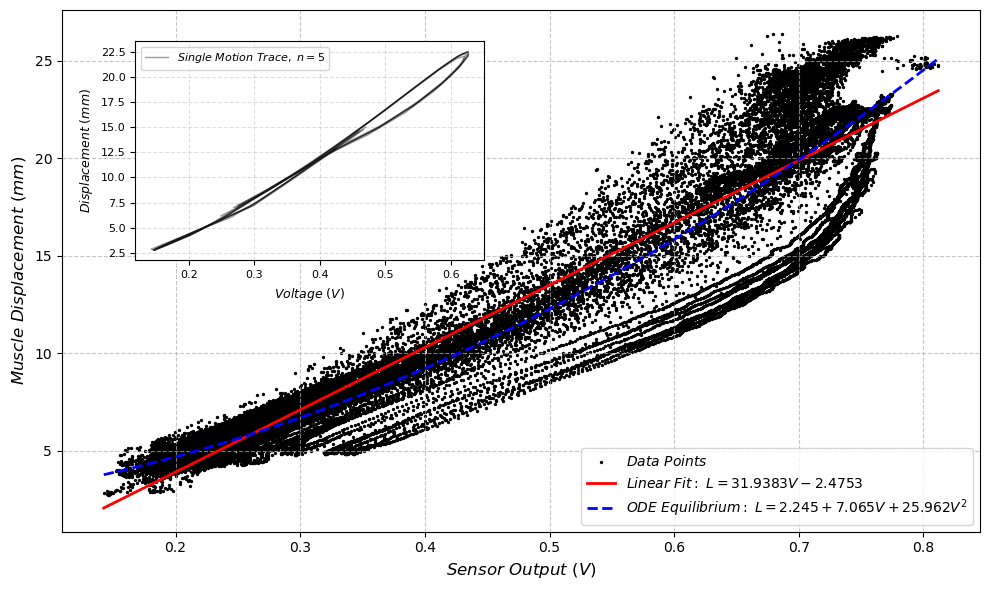

Saved figure: Length_vs_Voltage_Scatter_With_Inset_And_ODE.png


In [198]:
def plot_scatter_with_trace_inset_and_ode(
    folder=".",
    linear_params=(31.9383, -2.4753),                 # (m, b)
    ode_params=(2.245, 7.065, 25.962, -0.031, 0.0086)  # (c0, c1, c2, c3, tau)
):
    all_lengths = []
    all_voltages = []

    print("Aggregating scatter plot data...")

    for s in range(101, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(folder, filename)
            
            if not os.path.exists(file_path):
                continue
                
            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()
            
            if 'Length filtered (mm)' in df.columns and 'LW Filtered (V)' in df.columns:
                temp_df = pd.DataFrame()
                temp_df['Length'] = pd.to_numeric(df['Length filtered (mm)'], errors='coerce')
                temp_df['Voltage'] = pd.to_numeric(df['LW Filtered (V)'], errors='coerce')
                temp_df = temp_df.dropna()
                
                all_lengths.extend(temp_df['Length'].values)
                all_voltages.extend(temp_df['Voltage'].values)

    lengths = np.array(all_lengths)
    voltages = np.array(all_voltages)

    if len(lengths) == 0:
        print("Error: No valid scatter data found.")
        return

    x_data = voltages
    y_data = lengths
        
    fig, ax_main = plt.subplots(figsize=(10, 6))
        
    # 1. Plot raw scatter data
    ax_main.scatter(x_data, y_data, color='k', alpha=1, label='$ Data~Points $', s=2) 
    
    # 2. Plot optimized linear fit line
    m_opt, b_opt = linear_params
    v_range = np.linspace(np.min(x_data), np.max(x_data), 200)
    l_linear_fit = m_opt * v_range + b_opt
    ax_main.plot(v_range, l_linear_fit, color='red', linewidth=2, 
                  label=f'$ Linear~Fit:~L = {m_opt:.4f}V {b_opt:+.4f} $')
        
    # 3. Plot optimized ODE static equilibrium backbone
    c0, c1, c2, c3, tau = ode_params
    l_ode_static = c0 + c1 * v_range + c2 * (v_range**2)
    ax_main.plot(v_range, l_ode_static, color='blue', linestyle='--', linewidth=2, 
                  label=f'$ ODE~Equilibrium:~L = {c0:.3f} + {c1:.3f}V + {c2:.3f}V^2 $')

    ax_main.set_xlabel("$ Sensor~Output~(V) $", fontsize=12)
    ax_main.set_ylabel("$ Muscle~Displacement~(mm) $", fontsize=12)
    ax_main.grid(True, linestyle='--', alpha=0.7)
    ax_main.legend(loc='lower right', fontsize=10)
    
    # =========================================================
    # Top-Left Inset: Windowed Displacement vs Voltage Traces
    # =========================================================
    ax_inset = ax_main.inset_axes([0.08, 0.52, 0.38, 0.42])
    
    processed_count = 0
    for s in range(127, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(folder, filename)
            
            if not os.path.exists(file_path):
                continue
                
            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()
            
            if 't_rel(s)' not in df.columns:
                continue

            max_time_global = df['t_rel(s)'].max()
            df = df[df['t_rel(s)'] <= (max_time_global - 0.5)].copy()
            
            if df.empty:
                continue
                
            if 'Velocity (mm/s)' in df.columns:
                df['Vel_Standard'] = df['Velocity (mm/s)']
                len_col = 'Length filtered (mm)' if 'Length filtered (mm)' in df.columns else 'Length filtered (m)'
            elif 'Velocity (m/s)' in df.columns:
                df['Vel_Standard'] = df['Velocity (m/s)'] * 1000.0
                len_col = 'Length filtered (m)' if 'Length filtered (m)' in df.columns else 'Length filtered (mm)'
            else:
                continue
                
            vol_col = 'LW Filtered (V)' if 'LW Filtered (V)' in df.columns else 'LW RAW (V)'
            
            search_limit_time = df['t_rel(s)'].max() * 0.85
            df_search_window = df[df['t_rel(s)'] <= search_limit_time]
            
            if df_search_window['Vel_Standard'].isna().all():
                continue
                
            peak_idx = df_search_window['Vel_Standard'].idxmax()
            peak_time = df.loc[peak_idx, 't_rel(s)']
            
            win_mask = (df['t_rel(s)'] >= (peak_time - 0.45)) & (df['t_rel(s)'] <= (peak_time + 0.65))
            df_win = df[win_mask].copy()
            
            displacement = df_win[len_col] if 'mm' in len_col else df_win[len_col] * 1000.0
            voltage = df_win[vol_col]
            
            ax_inset.plot(voltage, displacement, color='k', alpha=0.4, linewidth=1.0)
            processed_count += 1

    ax_inset.set_xlabel("$ Voltage~(V) $", color='black', fontsize=9)
    ax_inset.set_ylabel("$ Displacement~(mm) $", color='black', fontsize=9)
    ax_inset.tick_params(axis='both', labelcolor='black', labelsize=8)
    ax_inset.grid(True, linestyle='--', alpha=0.4)

    # Inset proxy legend
    trace_legend_handle = [Line2D([0], [0], color='k', alpha=0.4, linewidth=1.0)]
    ax_inset.legend(trace_legend_handle, ['$ Single~Motion~Trace,~n=5 $'], loc='upper left', fontsize=8, framealpha=0.8)

    plt.tight_layout()
    out_name = "Length_vs_Voltage_Scatter_With_Inset_And_ODE.png"
    plt.savefig(out_name, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Saved figure: {out_name}")

# Example call using your default optimized parameters:
plot_scatter_with_trace_inset_and_ode(folder)

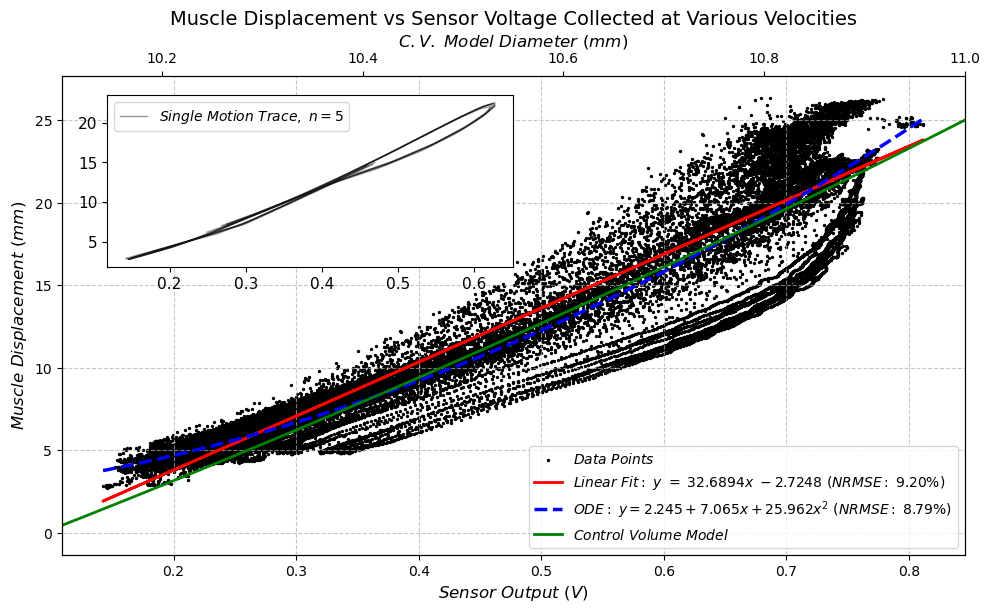

In [34]:
def plot_scatter_fixed_ref_diameter(
    folder, 
    ode_params=(2.245, 7.065, 25.962, -0.031, 0.0086)  # (c0, c1, c2, c3, tau)
):
    all_lengths = []
    all_voltages = []

    for s in range(101, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(folder, filename)
            
            if not os.path.exists(file_path):
                continue
                
            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()
            
            if 'Length filtered (mm)' in df.columns and 'LW Filtered (V)' in df.columns:
                temp_df = pd.DataFrame()
                temp_df['Length'] = pd.to_numeric(df['Length filtered (mm)'], errors='coerce')
                temp_df['Voltage'] = pd.to_numeric(df['LW Filtered (V)'], errors='coerce')
                
                temp_df = temp_df.dropna()
                
                all_lengths.extend(temp_df['Length'].values)
                all_voltages.extend(temp_df['Voltage'].values)

    lengths = np.array(all_lengths)
    voltages = np.array(all_voltages)

    if len(lengths) == 0:
        print("Error: No valid data found to plot.")
        return

    x_data = voltages
    y_data = lengths
        
    fig, ax_main = plt.subplots(figsize=(10, 6))
        
    # Main Scatter Plot and Linear Fit
    m, b = np.polyfit(x_data, y_data, 1)
    fit_line = m * x_data + b
    
    # Calculate Linear NRMSE (%)
    rmse_lin = np.sqrt(np.mean((y_data - fit_line)**2))
    nrmse_lin = (rmse_lin / (np.max(y_data) - np.min(y_data))) * 100.0
    
    ax_main.scatter(x_data, y_data, color='k', alpha=1, label='$ Data~Points $', s=2) 
    ax_main.plot(x_data, fit_line, color='red', linewidth=2, 
                  label=f'$ Linear~Fit:~y~=~{m:.4f}x~{b:.4f}~(NRMSE:~{nrmse_lin:.2f}\\%) $')
    
    # =========================================================
    # Dynamic ODE Equilibrium Overlay
    # =========================================================
    if ode_params is not None:
        c0, c1, c2, c3, tau = ode_params
        v_seq = np.linspace(np.min(x_data), np.max(x_data), 200)
        l_ode_static = c0 + c1 * v_seq + c2 * (v_seq**2)
        
        # Calculate ODE Static Backbone NRMSE (%)
        l_ode_pred = c0 + c1 * x_data + c2 * (x_data**2)
        rmse_ode = np.sqrt(np.mean((y_data - l_ode_pred)**2))
        nrmse_ode = (rmse_ode / (np.max(y_data) - np.min(y_data))) * 100.0
        
        ax_main.plot(v_seq, l_ode_static, color='blue', linestyle='--', linewidth=2.5, 
                      label=f'$ ODE:~y = {c0:.3f} + {c1:.3f}x + {c2:.3f}x^2~(NRMSE:~{nrmse_ode:.2f}\\%) $')

    ax_main.set_xlabel("$ Sensor~Output~(V) $", fontsize=12)
    ax_main.set_ylabel("$ Muscle~Displacement~(mm) $", fontsize=12)
    ax_main.grid(True, linestyle='--', alpha=0.7)

    # =========================================================
    # Extension Cylinder (D = 10mm fixed at L = 160mm / x = 25mm)
    # =========================================================
    L_ref = 155.0  # Length at 25mm displacement
    D_ref = 10.0   # Diameter at 25mm displacement
    V0 = 0.25 * np.pi * (D_ref**2) * L_ref

    disp_range = np.linspace(0, 25, 200)
    diam_range = np.sqrt((4.0 * V0) / (np.pi * (130.0 + disp_range)))

    # Secondary X-Axis tied to top
    ax_top = ax_main.twiny()
    ax_top.plot(21 - diam_range, disp_range, color='green', linestyle='-', linewidth=2, 
                label='$ Control~Volume~Model $')

    ax_top.set_xlabel("$ C.V.~Model~Diameter~(mm) $", fontsize=12)
    ax_top.tick_params(axis='x')
    ax_top.grid(False)
    ax_top.set_xlim(10.1, 11)

    # Combined Legend
    lines_main, labels_main = ax_main.get_legend_handles_labels()
    lines_top, labels_top = ax_top.get_legend_handles_labels()
    ax_main.legend(lines_main + lines_top, labels_main + labels_top, loc='lower right', fontsize=10)
    # ax_main.legend(lines_main, labels_main, loc='lower right', fontsize=10)

    # =========================================================
    # Top-Left Inset: Windowed Displacement vs Voltage Traces
    # =========================================================
    ax_inset = ax_main.inset_axes([0.05, 0.60, 0.45, 0.36])
    processed_count = 0
    
    for s in range(127, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(folder, filename)
            
            if not os.path.exists(file_path):
                continue
                
            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()
            
            if 't_rel(s)' not in df.columns:
                continue

            max_time_global = df['t_rel(s)'].max()
            df = df[df['t_rel(s)'] <= (max_time_global - 0.5)].copy()
            
            if df.empty:
                continue
                
            if 'Velocity (mm/s)' in df.columns:
                df['Vel_Standard'] = df['Velocity (mm/s)']
                len_col = 'Length filtered (mm)' if 'Length filtered (mm)' in df.columns else 'Length filtered (m)'
            elif 'Velocity (m/s)' in df.columns:
                df['Vel_Standard'] = df['Velocity (m/s)'] * 1000.0
                len_col = 'Length filtered (m)' if 'Length filtered (m)' in df.columns else 'Length filtered (mm)'
            else:
                continue
                
            vol_col = 'LW Filtered (V)' if 'LW Filtered (V)' in df.columns else 'LW RAW (V)'
            
            search_limit_time = df['t_rel(s)'].max() * 0.85
            df_search_window = df[df['t_rel(s)'] <= search_limit_time]
            
            if df_search_window['Vel_Standard'].isna().all():
                continue
                
            peak_idx = df_search_window['Vel_Standard'].idxmax()
            peak_time = df.loc[peak_idx, 't_rel(s)']
            
            win_mask = (df['t_rel(s)'] >= (peak_time - 0.45)) & (df['t_rel(s)'] <= (peak_time + 0.65))
            df_win = df[win_mask].copy()
            
            displacement = df_win[len_col] if 'mm' in len_col else df_win[len_col] * 1000.0
            voltage = df_win[vol_col]
            
            ax_inset.plot(voltage, displacement, color='k', alpha=0.4, linewidth=1.0)
            processed_count += 1

    ax_inset.tick_params(axis='both', labelcolor='black', labelsize=11)
    ax_inset.grid(True, linestyle='--', alpha=0)
    
    trace_legend_handle = [Line2D([0], [0], color='k', alpha=0.4, linewidth=1.0)]
    ax_inset.legend(
        trace_legend_handle, 
        ['$ Single~Motion~Trace,~n=5 $'], 
        loc='upper left', 
        fontsize=10, 
        frameon=True, 
        framealpha=0.8
    )

    plt.tight_layout()
    plt.title("Muscle Displacement vs Sensor Voltage Collected at Various Velocities", fontsize =14)
    plt.savefig("Length_vs_Voltage_Extension2.svg", dpi=300, bbox_inches='tight')
    plt.show()

# Example usage:
plot_scatter_fixed_ref_diameter(folder)

In [10]:
def fit_atan_ode_model(input_folder):
    L_all, V_all, dLdt_all, dVdt_all = [], [], [], []
    
    print("Extracting calibration data (excluding initial 15% per run)...")
    for s in range(101, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(input_folder, filename)
            
            if not os.path.exists(file_path):
                continue
                
            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()
            
            if 't_rel(s)' not in df.columns:
                continue

            vol_col = 'LW Filtered (V)' if 'LW Filtered (V)' in df.columns else 'LW RAW (V)'
            len_col = 'Length filtered (mm)' if 'Length filtered (mm)' in df.columns else 'Length filtered (m)'
            
            if vol_col not in df.columns or len_col not in df.columns:
                continue
                
            # Trim last 0.5s globally
            max_t = df['t_rel(s)'].max()
            df = df[df['t_rel(s)'] <= (max_t - 0.5)].copy()
            
            # Ignore FIRST 15% of data per run
            min_t = df['t_rel(s)'].min()
            start_threshold = min_t + 0.15 * (max_t - min_t)
            df = df[df['t_rel(s)'] >= start_threshold].copy()
            
            if len(df) < 10:
                continue
                
            L = df[len_col].values if 'mm' in len_col else df[len_col].values * 1000.0
            V = df[vol_col].values
            t = df['t_rel(s)'].values
            
            dLdt = np.gradient(L, t)
            dVdt = np.gradient(V, t)
            
            L_all.extend(L)
            V_all.extend(V)
            dLdt_all.extend(dLdt)
            dVdt_all.extend(dVdt)
            
    L_data = np.array(L_all)
    V_data = np.array(V_all)
    dLdt_data = np.array(dLdt_all)
    dVdt_data = np.array(dVdt_all)
    
    # Define Arctan ODE Function: L = c0 + c1*arctan((V - V0)/sigma) + c2*(dV/dt) - tau*(dL/dt)
    def atan_ode_func(X, c0, c1, V0, sigma, c2, tau):
        V_val, dVdt_val, dLdt_val = X
        return c0 + c1 * np.arctan((V_val - V0) / sigma) + c2 * dVdt_val - tau * dLdt_val

    # Initial parameter guesses: [c0, c1, V0, sigma, c2, tau]
    p0 = [np.mean(L_data), (np.max(L_data) - np.min(L_data)) / np.pi, np.mean(V_data), 1.0, 0.0, 0.01]
    
    # Fit model via Non-Linear Least Squares
    X_inputs = (V_data, dVdt_data, dLdt_data)
    popt, pcov = curve_fit(atan_ode_func, X_inputs, L_data, p0=p0, maxfev=10000)
    
    c0, c1, V0, sigma, c2, tau = popt
    
    # Evaluate Predictions & NRMSE (%)
    L_pred = atan_ode_func(X_inputs, *popt)
    rmse = np.sqrt(np.mean((L_data - L_pred)**2))
    nrmse_pct = (rmse / (np.max(L_data) - np.min(L_data))) * 100.0
    
    print("\n" + "="*55)
    print("          FITTED ARCTAN DYNAMIC ODE MODEL          ")
    print("="*55)
    print(f"c0 (Baseline Offset):   {c0:.4f}")
    print(f"c1 (Arctan Scale):     {c1:.4f}")
    print(f"V0 (Inflection V):     {V0:.4f} V")
    print(f"sigma (Width):          {sigma:.4f}")
    print(f"c2 (Rate Gain dV/dt):  {c2:.4f}")
    print(f"tau (Time Constant):   {tau:.5f} s")
    print(f"Model NRMSE:           {nrmse_pct:.2f}% (RMSE: {rmse:.4f} mm)")
    print("="*55)
    
    latex_str = (
        f"$ {tau:.4f}~\\frac{{dL}}{{dt}} + L(t) = "
        f"{c0:.3f} + {c1:.3f}~\\arctan\\left(\\frac{{V(t) - {V0:.3f}}}{{{sigma:.3f}}}\\right) + {c2:.3f}~\\frac{{dV}}{{dt}} $"
    )
    print("\nLaTeX String:")
    print(latex_str)
    
    return popt, latex_str

# Run fitting:
popt_atan, latex_atan = fit_atan_ode_model(folder)

Extracting calibration data (excluding initial 15% per run)...

          FITTED ARCTAN DYNAMIC ODE MODEL          
c0 (Baseline Offset):   19.5596
c1 (Arctan Scale):     17.0341
V0 (Inflection V):     0.6892 V
sigma (Width):          0.4121
c2 (Rate Gain dV/dt):  -0.0235
tau (Time Constant):   0.00882 s
Model NRMSE:           8.79% (RMSE: 2.0779 mm)

LaTeX String:
$ 0.0088~\frac{dL}{dt} + L(t) = 19.560 + 17.034~\arctan\left(\frac{V(t) - 0.689}{0.412}\right) + -0.024~\frac{dV}{dt} $


Aggregating scatter plot data...


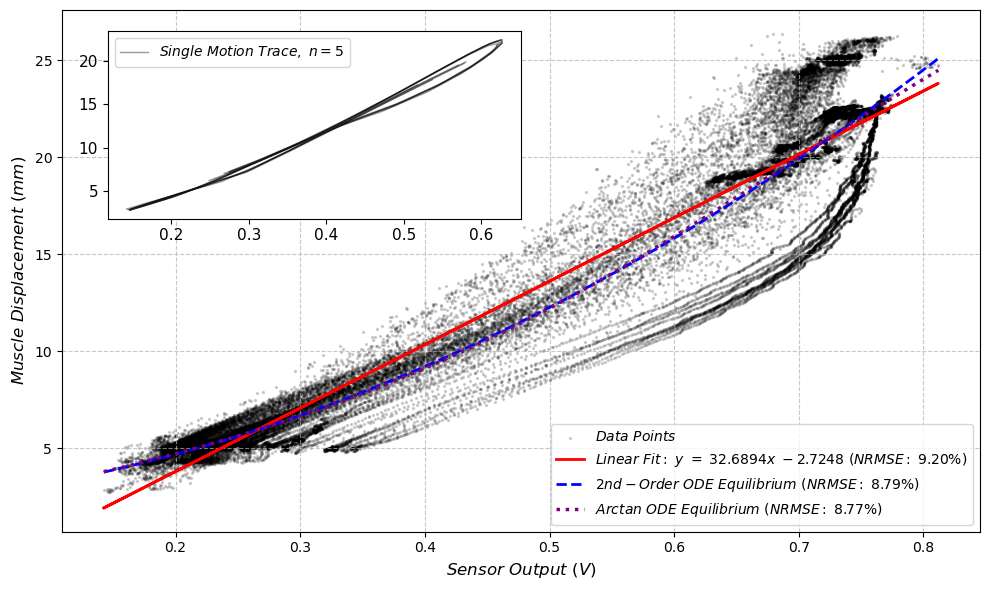

In [22]:
def plot_scatter_model_comparison(
    folder, 
    poly_ode_params=(2.245, 7.065, 25.962, -0.031, 0.0086),                     # (c0, c1, c2, c3, tau)
    atan_ode_params=(19.5596, 17.0341, 0.6892, 0.4121, -0.0235, 0.00882)         # (c0, c1, V0, sigma, c2, tau)
):
    all_lengths = []
    all_voltages = []

    print("Aggregating scatter plot data...")
    for s in range(101, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(folder, filename)
            
            if not os.path.exists(file_path):
                continue
                
            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()
            
            if 'Length filtered (mm)' in df.columns and 'LW Filtered (V)' in df.columns:
                temp_df = pd.DataFrame()
                temp_df['Length'] = pd.to_numeric(df['Length filtered (mm)'], errors='coerce')
                temp_df['Voltage'] = pd.to_numeric(df['LW Filtered (V)'], errors='coerce')
                
                temp_df = temp_df.dropna()
                
                all_lengths.extend(temp_df['Length'].values)
                all_voltages.extend(temp_df['Voltage'].values)

    lengths = np.array(all_lengths)
    voltages = np.array(all_voltages)

    if len(lengths) == 0:
        print("Error: No valid data found to plot.")
        return

    x_data = voltages
    y_data = lengths
    y_range = np.max(y_data) - np.min(y_data)
        
    fig, ax_main = plt.subplots(figsize=(10, 6))
        
    # 1. Raw Data Scatter
    ax_main.scatter(x_data, y_data, color='k', alpha=0.15, label='$ Data~Points $', s=2) 
    
    # 2. Static Linear Fit
    m, b = np.polyfit(x_data, y_data, 1)
    fit_line = m * x_data + b
    rmse_lin = np.sqrt(np.mean((y_data - fit_line)**2))
    nrmse_lin = (rmse_lin / y_range) * 100.0
    
    ax_main.plot(x_data, fit_line, color='red', linewidth=2, 
                  label=f'$ Linear~Fit:~y~=~{m:.4f}x~{b:+.4f}~(NRMSE:~{nrmse_lin:.2f}\\%) $')
    
    v_seq = np.linspace(np.min(x_data), np.max(x_data), 200)

    # 3. 2nd-Order Polynomial ODE Static Backbone (c0 + c1*V + c2*V^2)
    if poly_ode_params is not None:
        p_c0, p_c1, p_c2, p_c3, p_tau = poly_ode_params
        l_poly_seq = p_c0 + p_c1 * v_seq + p_c2 * (v_seq**2)
        
        l_poly_pred = p_c0 + p_c1 * x_data + p_c2 * (x_data**2)
        rmse_poly = np.sqrt(np.mean((y_data - l_poly_pred)**2))
        nrmse_poly = (rmse_poly / y_range) * 100.0
        
        ax_main.plot(v_seq, l_poly_seq, color='blue', linestyle='--', linewidth=2, 
                      label=f'$ 2nd-Order~ODE~Equilibrium~(NRMSE:~{nrmse_poly:.2f}\\%) $')

    # 4. Arctan ODE Static Backbone (c0 + c1*arctan((V - V0)/sigma))
    if atan_ode_params is not None:
        a_c0, a_c1, a_V0, a_sigma, a_c2, a_tau = atan_ode_params
        l_atan_seq = a_c0 + a_c1 * np.arctan((v_seq - a_V0) / a_sigma)
        
        l_atan_pred = a_c0 + a_c1 * np.arctan((x_data - a_V0) / a_sigma)
        rmse_atan = np.sqrt(np.mean((y_data - l_atan_pred)**2))
        nrmse_atan = (rmse_atan / y_range) * 100.0
        
        ax_main.plot(v_seq, l_atan_seq, color='purple', linestyle=':', linewidth=2.5, 
                      label=f'$ Arctan~ODE~Equilibrium~(NRMSE:~{nrmse_atan:.2f}\\%) $')

    ax_main.set_xlabel("$ Sensor~Output~(V) $", fontsize=12)
    ax_main.set_ylabel("$ Muscle~Displacement~(mm) $", fontsize=12)
    ax_main.grid(True, linestyle='--', alpha=0.7)
    ax_main.legend(loc='lower right', fontsize=10)

    # =========================================================
    # Top-Left Inset: Windowed Displacement vs Voltage Traces
    # =========================================================
    ax_inset = ax_main.inset_axes([0.05, 0.60, 0.45, 0.36])
    processed_count = 0
    
    for s in range(127, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(folder, filename)
            
            if not os.path.exists(file_path):
                continue
                
            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()
            
            if 't_rel(s)' not in df.columns:
                continue

            max_time_global = df['t_rel(s)'].max()
            df = df[df['t_rel(s)'] <= (max_time_global - 0.5)].copy()
            
            if df.empty:
                continue
                
            if 'Velocity (mm/s)' in df.columns:
                df['Vel_Standard'] = df['Velocity (mm/s)']
                len_col = 'Length filtered (mm)' if 'Length filtered (mm)' in df.columns else 'Length filtered (m)'
            elif 'Velocity (m/s)' in df.columns:
                df['Vel_Standard'] = df['Velocity (m/s)'] * 1000.0
                len_col = 'Length filtered (m)' if 'Length filtered (m)' in df.columns else 'Length filtered (mm)'
            else:
                continue
                
            vol_col = 'LW Filtered (V)' if 'LW Filtered (V)' in df.columns else 'LW RAW (V)'
            
            search_limit_time = df['t_rel(s)'].max() * 0.85
            df_search_window = df[df['t_rel(s)'] <= search_limit_time]
            
            if df_search_window['Vel_Standard'].isna().all():
                continue
                
            peak_idx = df_search_window['Vel_Standard'].idxmax()
            peak_time = df.loc[peak_idx, 't_rel(s)']
            
            win_mask = (df['t_rel(s)'] >= (peak_time - 0.5)) & (df['t_rel(s)'] <= (peak_time + 1.0))
            df_win = df[win_mask].copy()
            
            displacement = df_win[len_col] if 'mm' in len_col else df_win[len_col] * 1000.0
            voltage = df_win[vol_col]
            
            ax_inset.plot(voltage, displacement, color='k', alpha=0.4, linewidth=1.0)
            processed_count += 1

    ax_inset.tick_params(axis='both', labelcolor='black', labelsize=11)
    ax_inset.grid(True, linestyle='--', alpha=0)
    
    trace_legend_handle = [Line2D([0], [0], color='k', alpha=0.4, linewidth=1.0)]
    ax_inset.legend(
        trace_legend_handle, 
        ['$ Single~Motion~Trace,~n=5 $'], 
        loc='upper left', 
        fontsize=10, 
        frameon=True, 
        framealpha=0.8
    )

    plt.tight_layout()
    plt.savefig("Length_vs_Voltage_Model_Comparison.png", dpi=300, bbox_inches='tight')
    plt.show()

# Example usage:
plot_scatter_model_comparison(folder)

--- 1. SYMBOLIC LAPLACE TRANSFORM DERIVATION ---
Symbolic Sensor Transfer Function H_sensor(s) = L(s) / V(s):
V(s)⋅c₁ + V(s)⋅c₃⋅s - c₃⋅V(0) + τ⋅L(0)
──────────────────────────────────────
            V(s)⋅(s⋅τ + 1)            

Symbolic Linearized Spindle Transfer Function H_spindle(s) = FR(s) / L(s):
        B - 1    
A⋅B⋅s⋅v₀      + C

Cascaded Sensor-to-Afferent Transfer Function H_total(s) = FR(s) / V(s):
⎛        B - 1    ⎞                                         
⎝A⋅B⋅s⋅v₀      + C⎠⋅(V(s)⋅c₁ + V(s)⋅c₃⋅s - c₃⋅V(0) + τ⋅L(0))
────────────────────────────────────────────────────────────
                       V(s)⋅(s⋅τ + 1)                       

--- 2. NUMERICAL TRANSFER FUNCTION EVALUATION ---
Numeric Cascaded Transfer Function H_total(s):
(3.52363054818465⋅s + 77.298)⋅(-0.031⋅V(s)⋅s + 7.065⋅V(s) + 0.0086⋅L(0) + 0.031⋅V(0))
─────────────────────────────────────────────────────────────────────────────────────
                                 V(s)⋅(0.0086⋅s + 1)                     

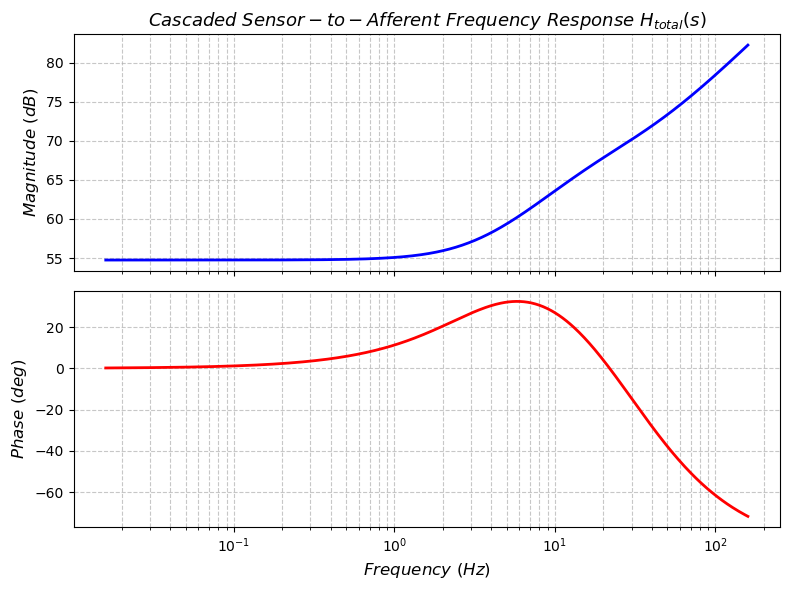

Bode plot generated and saved as 'Sensor_to_Afferent_Bode_Plot.png'.


In [26]:
import sympy as sp
import scipy.signal as signal
# ==============================================================================
# 1. SYMBOLIC LAPLACE TRANSFORM WITH SYMPY
# ==============================================================================
print("--- 1. SYMBOLIC LAPLACE TRANSFORM DERIVATION ---")

# Define symbolic variables
s, t = sp.symbols('s t', positive=True)
tau = sp.Symbol('tau', positive=True)
c0, c1, c2, c3 = sp.symbols('c0 c1 c2 c3')
A, B, C, D, v0 = sp.symbols('A B C D v0', positive=True)

# Time-domain functions and their Laplace transforms
V = sp.Function('V')(t)
L = sp.Function('L')(t)
V_s = sp.Symbol('V(s)')
L_s = sp.Symbol('L(s)')

# Define the Linearized Calibration ODE:
# tau * dL/dt + L(t) = c0 + c1*V(t) + c3*dV/dt
# (Assuming zero initial conditions L(0) = 0, V(0) = 0 for transfer function)
ode_lhs = tau * sp.diff(L, t) + L
ode_rhs = c1 * V + c3 * sp.diff(V, t)

# Perform Laplace Transform on both sides
laplace_lhs = sp.laplace_transform(ode_lhs, t, s, noconds=True)
laplace_rhs = sp.laplace_transform(ode_rhs, t, s, noconds=True)

# Substitute functional forms with algebraic s-domain symbols:
# L(s) for Laplace(L(t)) and V(s) for Laplace(V(t))
laplace_lhs_sub = laplace_lhs.subs(sp.LaplaceTransform(L, t, s), L_s)
laplace_rhs_sub = laplace_rhs.subs(sp.LaplaceTransform(V, t, s), V_s)

# Solve for Sensor Transfer Function H_sensor(s) = L(s) / V(s)
H_sensor_sym = sp.solve(sp.Eq(laplace_lhs_sub, laplace_rhs_sub), L_s)[0] / V_s
H_sensor_sym = sp.simplify(H_sensor_sym)

print("Symbolic Sensor Transfer Function H_sensor(s) = L(s) / V(s):")
sp.pprint(H_sensor_sym)

# Define Linearized Prochazka Spindle Transfer Function H_spindle(s) = FR(s) / L(s)
# Linearized velocity gain K_v = A * B * (v0 ** (B - 1))
K_v = A * B * (v0 ** (B - 1))
H_spindle_sym = C + K_v * s

print("\nSymbolic Linearized Spindle Transfer Function H_spindle(s) = FR(s) / L(s):")
sp.pprint(H_spindle_sym)

# Cascade both transfer functions: H_total(s) = H_sensor(s) * H_spindle(s)
H_total_sym = sp.simplify(H_sensor_sym * H_spindle_sym)

print("\nCascaded Sensor-to-Afferent Transfer Function H_total(s) = FR(s) / V(s):")
sp.pprint(H_total_sym)


# ==============================================================================
# 2. NUMERICAL EVALUATION WITH FITTED PARAMETERS
# ==============================================================================
print("\n--- 2. NUMERICAL TRANSFER FUNCTION EVALUATION ---")

# Fitted ODE Coefficients:
# 0.0086 * dL/dt + L(t) = 2.245 + 7.065*V + 25.962*V^2 - 0.031*dV/dt
tau_val = 0.0086
c1_val  = 7.065
c3_val  = -0.031

# Global Prochazka Spindle Parameters:
# FR = 38.118 * |v|^0.546 + 77.298 * L + 72.484
A_val = 38.118
B_val = 0.546
C_val = 77.298
v0_val = 50.0  # Operating peak stretch velocity = 50 mm/s

# Compute linearized velocity gain K_v
Kv_val = A_val * B_val * (v0_val ** (B_val - 1.0))

# Substitute values into SymPy expressions
num_subs = {
    tau: tau_val,
    c1: c1_val,
    c3: c3_val,
    C: C_val,
    K_v: Kv_val
}

H_total_num = H_total_sym.subs(num_subs)
print("Numeric Cascaded Transfer Function H_total(s):")
sp.pprint(H_total_num)


# ==============================================================================
# 3. SCIPY BODE PLOT (FREQUENCY RESPONSE ANALYSIS)
# ==============================================================================
# Construct SciPy LTI system for H_total(s):
# H_total(s) = (b2 * s^2 + b1 * s + b0) / (a1 * s + a0)
num_coeffs = [c3_val * Kv_val, (c1_val * Kv_val + c3_val * C_val), c1_val * C_val]
den_coeffs = [tau_val, 1.0]

system = signal.TransferFunction(num_coeffs, den_coeffs)

# Generate Bode Plot Data across stretch frequencies (0.1 Hz to 100 Hz)
w = np.logspace(-1, 3, 500)  # rad/s
w_hz = w / (2.0 * np.pi)
w, mag, phase = signal.bode(system, w)

fig, (ax_mag, ax_phase) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

# Magnitude Response
ax_mag.semilogx(w_hz, mag, color='blue', linewidth=2)
ax_mag.set_ylabel("$ Magnitude~(dB) $", fontsize=12)
ax_mag.set_title("$ Cascaded~Sensor-to-Afferent~Frequency~Response~H_{total}(s) $", fontsize=13)
ax_mag.grid(True, which="both", linestyle="--", alpha=0.7)

# Phase Response
ax_phase.semilogx(w_hz, phase, color='red', linewidth=2)
ax_phase.set_xlabel("$ Frequency~(Hz) $", fontsize=12)
ax_phase.set_ylabel("$ Phase~(deg) $", fontsize=12)
ax_phase.grid(True, which="both", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.savefig("Sensor_to_Afferent_Bode_Plot.png", dpi=300)
plt.show()

print("Bode plot generated and saved as 'Sensor_to_Afferent_Bode_Plot.png'.")

### Laplace Modelling

In [48]:
def process_batch_cascaded_model(folder_path):
    """
    Batch processes all files (S101P001 to S127P005) to compute the 11-term 
    cascaded s-domain predicted firing rate and evaluate accuracy against 
    the Prochazka target column 'Type Ia Firing Rate'.
    """
    # -------------------------------------------------------------
    # 1. Model Constants
    # -------------------------------------------------------------
    # Spindle parameters from your explicit target formula:
    # FR = 4.3 * (sign(v) * |v|^0.6) + 2.0 * L + 82.0
    A = 4.3
    B = 0.6
    E = 2.0
    D = 82.0

    # 2nd-order ODE Sensor parameters
    tau = 0.0086
    C0_raw = 2.245
    C1 = 7.065
    C2 = 25.962
    C3 = -0.031

    results_summary = []

    print("=" * 75)
    print("STARTING BATCH EVALUATION: CASCADED s-DOMAIN MODEL vs. TARGET FR")
    print("=" * 75)

    # Loop over subjects S101 - S127 and positions P001 - P005
    for s in range(101, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(folder_path, filename)

            if not os.path.exists(file_path):
                continue

            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()

            # Verify required columns exist
            required_cols = ['t_rel(s)', 'LW Filtered (V)', 'Type Ia Firing Rate']
            if not all(col in df.columns for col in required_cols):
                print(f"Skipping {filename}: Missing required columns.")
                continue

            # Extract arrays
            t = pd.to_numeric(df['t_rel(s)'], errors='coerce').values
            V = pd.to_numeric(df['LW Filtered (V)'], errors='coerce').values
            FR_target = pd.to_numeric(df['Type Ia Firing Rate'], errors='coerce').values

            # Handle edge cases / NaNs in data
            valid_mask = ~np.isnan(t) & ~np.isnan(V) & ~np.isnan(FR_target)
            if np.sum(valid_mask) < 32:
                print(f"Skipping {filename}: Insufficient valid data points.")
                continue

            t = t[valid_mask]
            V = V[valid_mask]
            FR_target = FR_target[valid_mask]

            N = len(t)
            dt = t[1] - t[0]

            # -------------------------------------------------------------
            # 2. Linearization around Voltage Midpoint V0
            # -------------------------------------------------------------
            V0 = (np.max(V) + np.min(V)) / 2.0
            Kv = C1 + 2.0 * C2 * V0          # Effective linear voltage gain
            C0_eff = C0_raw - C2 * (V0**2)   # Effective static baseline offset

            # -------------------------------------------------------------
            # 3. Frequency Domain Evaluation (FFT / IFFT)
            # -------------------------------------------------------------
            freqs = np.fft.fftfreq(N, d=dt)  # Frequencies in Hz
            omega = 2.0 * np.pi * freqs     # Angular frequencies (rad/s)
            s_complex = 1j * omega

            # Prevent DC divide-by-zero / singularity
            s_safe = np.copy(s_complex)
            if s_safe[0] == 0:
                s_safe[0] = 1e-12

            # Denominator: Sensor lag filter (tau * s + 1)
            den_sensor = tau * s_safe + 1.0

            # Numerator of the 11-term dynamic transfer function:
            # (A*Kv*s^B + A*C3*s^(B+1) + E*Kv + E*C3*s)
            num_dynamic = (A * Kv * (s_safe**B) + 
                           A * C3 * (s_safe**(B + 1.0)) + 
                           E * Kv + 
                           E * C3 * s_safe)

            H_total = num_dynamic / den_sensor

            # Filter voltage signal in frequency domain
            V_fft = np.fft.fft(V)
            FR_dynamic = np.real(np.fft.ifft(H_total * V_fft))

            # Static baseline step response decay: L_offset(t) = C0_eff * (1 - exp(-t/tau))
            L_offset = C0_eff * (1.0 - np.exp(-t / tau))

            # Total predicted firing rate
            FR_predicted = FR_dynamic + E * L_offset + D
            FR_predicted_rectified = np.maximum(0, FR_predicted)

            # -------------------------------------------------------------
            # 4. Save Prediction & Calculate Error
            # -------------------------------------------------------------
            df.loc[valid_mask, 'FR_Cascaded_Predicted'] = FR_predicted_rectified

            rmse = np.sqrt(np.mean((FR_target - FR_predicted_rectified)**2))
            fr_range = np.max(FR_target) - np.min(FR_target)
            nrmse = (rmse / fr_range) * 100.0 if fr_range > 0 else 0.0

            results_summary.append({
                'File': filename,
                'V0': V0,
                'Kv': Kv,
                'RMSE_Hz': rmse,
                'NRMSE_pct': nrmse
            })

            print(f"Processed {filename:<12} | V0 = {V0:.3f} V | NRMSE = {nrmse:.2f}%")

            # Save updated DataFrame back to CSV
            df.to_csv(file_path, index=False)

    # -------------------------------------------------------------
    # 5. Overall Dataset Performance Summary
    # -------------------------------------------------------------
    summary_df = pd.DataFrame(results_summary)
    if not summary_df.empty:
        mean_nrmse = summary_df['NRMSE_pct'].mean()
        mean_rmse = summary_df['RMSE_Hz'].mean()

        print("=" * 75)
        print("                        BATCH SUMMARY                          ")
        print("=" * 75)
        print(f"Total Files Processed   : {len(summary_df)}")
        print(f"Mean RMSE               : {mean_rmse:.3f} Hz")
        print(f"Mean NRMSE              : {mean_nrmse:.2f}%")
        print(f"Best Match File         : {summary_df.loc[summary_df['NRMSE_pct'].idxmin(), 'File']} ({summary_df['NRMSE_pct'].min():.2f}%)")
        print(f"Worst Match File        : {summary_df.loc[summary_df['NRMSE_pct'].idxmax(), 'File']} ({summary_df['NRMSE_pct'].max():.2f}%)")
        print("=" * 75)

    return summary_df

# Run batch processing
# Replace 'folder' with the path to your CSV files directory 
summary_results = process_batch_cascaded_model(folder)

STARTING BATCH EVALUATION: CASCADED s-DOMAIN MODEL vs. TARGET FR
Processed S101P001.csv | V0 = 0.488 V | NRMSE = 21.60%
Processed S101P002.csv | V0 = 0.470 V | NRMSE = 29.14%
Processed S101P003.csv | V0 = 0.469 V | NRMSE = 30.18%
Processed S101P004.csv | V0 = 0.468 V | NRMSE = 30.92%
Processed S101P005.csv | V0 = 0.464 V | NRMSE = 32.59%
Processed S102P001.csv | V0 = 0.462 V | NRMSE = 30.85%
Processed S102P003.csv | V0 = 0.461 V | NRMSE = 31.97%
Processed S102P005.csv | V0 = 0.458 V | NRMSE = 34.51%
Processed S103P001.csv | V0 = 0.458 V | NRMSE = 34.41%
Processed S103P002.csv | V0 = 0.456 V | NRMSE = 33.74%
Processed S103P003.csv | V0 = 0.458 V | NRMSE = 32.14%
Processed S103P004.csv | V0 = 0.455 V | NRMSE = 30.55%
Processed S103P005.csv | V0 = 0.455 V | NRMSE = 31.52%
Processed S104P001.csv | V0 = 0.484 V | NRMSE = 27.63%
Processed S104P002.csv | V0 = 0.497 V | NRMSE = 29.52%
Processed S104P003.csv | V0 = 0.514 V | NRMSE = 30.59%
Processed S104P005.csv | V0 = 0.514 V | NRMSE = 21.14%


In [50]:
def process_and_plot_firing_rates(folder_path, output_plot_dir="model_plots"):
    """
    Processes all S100P001-S127P005 files, computes the s-domain predicted 
    firing rate, updates CSVs, and saves single-panel plots comparing target 
    and predicted firing rates.
    """
    # -------------------------------------------------------------
    # 1. Subfolder Setup
    # -------------------------------------------------------------
    plot_folder = os.path.join(folder_path, output_plot_dir)
    os.makedirs(plot_folder, exist_ok=True)
    print(f"Saving firing rate plots to: {os.path.abspath(plot_folder)}\n")

    # -------------------------------------------------------------
    # 2. Model Constants
    # -------------------------------------------------------------
    # Prochazka Spindle parameters: FR = 4.3*(sign(v)*|v|^0.6) + 2.0*L + 82.0
    A = 4.3
    B = 0.6
    E = 2.0
    D = 82.0

    # 2nd-order ODE Sensor parameters
    tau = 0.0086
    C0_raw = 2.245
    C1 = 7.065
    C2 = 25.962
    C3 = -0.031

    results_summary = []

    # Loop over subjects S101 - S127 and positions P001 - P005
    for s in range(101, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(folder_path, filename)

            if not os.path.exists(file_path):
                continue

            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()

            required_cols = ['t_rel(s)', 'LW Filtered (V)', 'Type Ia Firing Rate']
            if not all(col in df.columns for col in required_cols):
                continue

            t = pd.to_numeric(df['t_rel(s)'], errors='coerce').values
            V = pd.to_numeric(df['LW Filtered (V)'], errors='coerce').values
            FR_target = pd.to_numeric(df['Type Ia Firing Rate'], errors='coerce').values

            valid_mask = ~np.isnan(t) & ~np.isnan(V) & ~np.isnan(FR_target)
            if np.sum(valid_mask) < 32:
                continue

            t_valid = t[valid_mask]
            V_valid = V[valid_mask]
            FR_target_valid = FR_target[valid_mask]

            N = len(t_valid)
            dt = t_valid[1] - t_valid[0]

            # -------------------------------------------------------------
            # 3. Frequency-Domain FFT Filtering H_total(s)
            # -------------------------------------------------------------
            V0 = (np.max(V_valid) + np.min(V_valid)) / 2.0
            Kv = C1 + 2.0 * C2 * V0
            C0_eff = C0_raw - C2 * (V0**2)

            freqs = np.fft.fftfreq(N, d=dt)
            omega = 2.0 * np.pi * freqs
            s_complex = 1j * omega

            s_safe = np.copy(s_complex)
            if s_safe[0] == 0:
                s_safe[0] = 1e-12

            den_sensor = tau * s_safe + 1.0

            num_dynamic = (A * Kv * (s_safe**B) + 
                           A * C3 * (s_safe**(B + 1.0)) + 
                           E * Kv + 
                           E * C3 * s_safe)

            H_total = num_dynamic / den_sensor

            V_fft = np.fft.fft(V_valid)
            FR_dynamic = np.real(np.fft.ifft(H_total * V_fft))
            L_offset = C0_eff * (1.0 - np.exp(-t_valid / tau))

            FR_predicted = np.maximum(0, FR_dynamic + E * L_offset + D)

            # Save prediction to DataFrame and update CSV file
            df.loc[valid_mask, 'FR_Cascaded_Predicted'] = FR_predicted
            df.to_csv(file_path, index=False)

            # Accuracy metric
            rmse = np.sqrt(np.mean((FR_target_valid - FR_predicted)**2))
            fr_range = np.max(FR_target_valid) - np.min(FR_target_valid)
            nrmse = (rmse / fr_range) * 100.0 if fr_range > 0 else 0.0

            results_summary.append({
                'File': filename,
                'NRMSE_pct': nrmse
            })

            # -------------------------------------------------------------
            # 4. Generate & Save Single-Panel Firing Rate Plot
            # -------------------------------------------------------------
            fig, ax = plt.subplots(figsize=(10, 5))

            ax.plot(t_valid, FR_target_valid, color='black', linewidth=2.0, 
                    label='Target Firing Rate (Prochazka Model)')
            ax.plot(t_valid, FR_predicted, color='purple', linewidth=1.8, linestyle='--', 
                    label=f'Predicted Firing Rate ($s$-Domain Model) — NRMSE: {nrmse:.2f}%')

            ax.set_xlabel("Time (s)", fontsize=11)
            ax.set_ylabel("Firing Rate (Hz)", fontsize=11)
            ax.set_title(f"Afferent Firing Rate Comparison — Trial {filename}", fontsize=12, fontweight='bold')
            ax.grid(True, linestyle='--', alpha=0.6)
            ax.legend(loc='upper right', fontsize=10)

            plt.tight_layout()

            # Save PNG figure
            plot_filename = f"{os.path.splitext(filename)[0]}_FR_plot.png"
            plot_path = os.path.join(plot_folder, plot_filename)
            plt.savefig(plot_path, dpi=200)
            plt.close(fig)

            print(f"Processed {filename:<12} | Plot Saved -> {plot_filename} | NRMSE = {nrmse:.2f}%")

    print("\nProcessing complete! All plots saved.")
    return pd.DataFrame(results_summary)

# Execute
summary = process_and_plot_firing_rates(folder)

Saving firing rate plots to: C:\Users\lmicklem\Documents\GitHub\Muscle_Sensory\Muscle_length_sensory\18-05-2026 Literature Comparison\2026-07-16 Test Data\2026-08-04\model_plots

Processed S101P001.csv | Plot Saved -> S101P001_FR_plot.png | NRMSE = 21.60%
Processed S101P002.csv | Plot Saved -> S101P002_FR_plot.png | NRMSE = 29.14%
Processed S101P003.csv | Plot Saved -> S101P003_FR_plot.png | NRMSE = 30.18%
Processed S101P004.csv | Plot Saved -> S101P004_FR_plot.png | NRMSE = 30.92%
Processed S101P005.csv | Plot Saved -> S101P005_FR_plot.png | NRMSE = 32.59%
Processed S102P001.csv | Plot Saved -> S102P001_FR_plot.png | NRMSE = 30.85%
Processed S102P003.csv | Plot Saved -> S102P003_FR_plot.png | NRMSE = 31.97%
Processed S102P005.csv | Plot Saved -> S102P005_FR_plot.png | NRMSE = 34.51%
Processed S103P001.csv | Plot Saved -> S103P001_FR_plot.png | NRMSE = 34.41%
Processed S103P002.csv | Plot Saved -> S103P002_FR_plot.png | NRMSE = 33.74%
Processed S103P003.csv | Plot Saved -> S103P003_FR_

In [52]:
def process_calibrated_model_batch(folder_path, output_plot_dir="calibrated_model_plots", alpha_dyn=0.72):
    """
    Processes all S100P001-S127P005 files using the calibrated s-domain transfer function
    (mean V0 and dynamic scaling alpha_dyn) to fix peak overshooting and trough undershooting.
    
    Saves plots to a dedicated output subfolder.
    """
    # -------------------------------------------------------------
    # 1. Subfolder Setup
    # -------------------------------------------------------------
    plot_folder = os.path.join(folder_path, output_plot_dir)
    os.makedirs(plot_folder, exist_ok=True)
    print(f"Saving calibrated plots to: {os.path.abspath(plot_folder)}")
    print(f"Dynamic Scale Factor (alpha_dyn): {alpha_dyn}\n")

    # -------------------------------------------------------------
    # 2. Model Parameters
    # -------------------------------------------------------------
    # Prochazka Spindle parameters: FR = 4.3*(sign(v)*|v|^0.6) + 2.0*L + 82.0
    A = 4.3
    B = 0.6
    E = 2.0
    D = 82.0

    # 2nd-order ODE Sensor parameters
    tau = 0.0086
    C0_raw = 2.245
    C1 = 7.065
    C2 = 25.962
    C3 = -0.031

    results_summary = []

    # Loop over subjects S101 - S127 and positions P001 - P005
    for s in range(101, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(folder_path, filename)

            if not os.path.exists(file_path):
                continue

            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()

            required_cols = ['t_rel(s)', 'LW Filtered (V)', 'Type Ia Firing Rate']
            if not all(col in df.columns for col in required_cols):
                continue

            t = pd.to_numeric(df['t_rel(s)'], errors='coerce').values
            V = pd.to_numeric(df['LW Filtered (V)'], errors='coerce').values
            FR_target = pd.to_numeric(df['Type Ia Firing Rate'], errors='coerce').values

            valid_mask = ~np.isnan(t) & ~np.isnan(V) & ~np.isnan(FR_target)
            if np.sum(valid_mask) < 32:
                continue

            t_valid = t[valid_mask]
            V_valid = V[valid_mask]
            FR_target_valid = FR_target[valid_mask]

            N = len(t_valid)
            dt = t_valid[1] - t_valid[0]

            # -------------------------------------------------------------
            # 3. Calibrated Frequency-Domain Filtering H_total(s)
            # -------------------------------------------------------------
            # FIX 1: Use mean voltage V0 instead of range midpoint
            V0 = np.mean(V_valid)
            Kv = C1 + 2.0 * C2 * V0
            C0_eff = C0_raw - C2 * (V0**2)

            freqs = np.fft.fftfreq(N, d=dt)
            omega = 2.0 * np.pi * freqs
            s_complex = 1j * omega

            s_safe = np.copy(s_complex)
            if s_safe[0] == 0:
                s_safe[0] = 1e-12

            den_sensor = tau * s_safe + 1.0

            # Dynamic velocity and fractional derivative terms
            num_dynamic_terms = (A * Kv * (s_safe**B) + 
                                 A * C3 * (s_safe**(B + 1.0)) + 
                                 E * C3 * s_safe)

            # Static voltage gain term
            num_static_term = E * Kv

            # FIX 2: Apply alpha_dyn scale factor to damp dynamic overshoots
            H_total = (alpha_dyn * num_dynamic_terms + num_static_term) / den_sensor

            V_fft = np.fft.fft(V_valid)
            FR_dynamic = np.real(np.fft.ifft(H_total * V_fft))
            L_offset = C0_eff * (1.0 - np.exp(-t_valid / tau))

            FR_predicted = np.maximum(0, FR_dynamic + E * L_offset + D)

            # Save prediction into DataFrame as 'FR_Calibrated_Predicted'
            df.loc[valid_mask, 'FR_Calibrated_Predicted'] = FR_predicted
            df.to_csv(file_path, index=False)

            # Accuracy Metrics
            rmse = np.sqrt(np.mean((FR_target_valid - FR_predicted)**2))
            fr_range = np.max(FR_target_valid) - np.min(FR_target_valid)
            nrmse = (rmse / fr_range) * 100.0 if fr_range > 0 else 0.0

            results_summary.append({
                'File': filename,
                'V0': V0,
                'Kv': Kv,
                'RMSE_Hz': rmse,
                'NRMSE_pct': nrmse
            })

            # -------------------------------------------------------------
            # 4. Generate & Save Comparison Plot
            # -------------------------------------------------------------
            fig, ax = plt.subplots(figsize=(10, 5))

            ax.plot(t_valid, FR_target_valid, color='black', linewidth=2.0, 
                    label='Target Firing Rate (Prochazka Model)')
            ax.plot(t_valid, FR_predicted, color='purple', linewidth=1.8, linestyle='--', 
                    label=f'Calibrated $s$-Domain Model (NRMSE: {nrmse:.2f}%)')

            ax.set_xlabel("Time (s)", fontsize=11)
            ax.set_ylabel("Firing Rate (Hz)", fontsize=11)
            ax.set_title(f"Calibrated Afferent Firing Rate — Trial {filename}", fontsize=12, fontweight='bold')
            ax.grid(True, linestyle='--', alpha=0.6)
            ax.legend(loc='upper right', fontsize=10)

            plt.tight_layout()

            # Save PNG plot
            plot_filename = f"{os.path.splitext(filename)[0]}_calibrated_FR_plot.png"
            plot_path = os.path.join(plot_folder, plot_filename)
            plt.savefig(plot_path, dpi=200)
            plt.close(fig)

            print(f"Processed {filename:<12} | Plot Saved -> {plot_filename:<32} | NRMSE = {nrmse:.2f}%")

    # Print summary results
    summary_df = pd.DataFrame(results_summary)
    if not summary_df.empty:
        print("\n" + "=" * 75)
        print("                  CALIBRATED BATCH RUN SUMMARY                  ")
        print("=" * 75)
        print(f"Total Files Processed   : {len(summary_df)}")
        print(f"Mean RMSE               : {summary_df['RMSE_Hz'].mean():.3f} Hz")
        print(f"Mean NRMSE              : {summary_df['NRMSE_pct'].mean():.2f}%")
        print("=" * 75)

    return summary_df

# ==============================================================================
# EXECUTION
# ==============================================================================
if __name__ == "__main__":
    summary = process_calibrated_model_batch(
        folder_path=folder, 
        output_plot_dir="calibrated_model_plots", 
        alpha_dyn=0.72  # Adjust between 0.65 and 0.80 if needed
    )

Saving calibrated plots to: C:\Users\lmicklem\Documents\GitHub\Muscle_Sensory\Muscle_length_sensory\18-05-2026 Literature Comparison\2026-07-16 Test Data\2026-08-04\calibrated_model_plots
Dynamic Scale Factor (alpha_dyn): 0.72

Processed S101P001.csv | Plot Saved -> S101P001_calibrated_FR_plot.png  | NRMSE = 8.57%
Processed S101P002.csv | Plot Saved -> S101P002_calibrated_FR_plot.png  | NRMSE = 14.25%
Processed S101P003.csv | Plot Saved -> S101P003_calibrated_FR_plot.png  | NRMSE = 15.23%
Processed S101P004.csv | Plot Saved -> S101P004_calibrated_FR_plot.png  | NRMSE = 15.91%
Processed S101P005.csv | Plot Saved -> S101P005_calibrated_FR_plot.png  | NRMSE = 16.57%
Processed S102P001.csv | Plot Saved -> S102P001_calibrated_FR_plot.png  | NRMSE = 15.49%
Processed S102P003.csv | Plot Saved -> S102P003_calibrated_FR_plot.png  | NRMSE = 17.89%
Processed S102P005.csv | Plot Saved -> S102P005_calibrated_FR_plot.png  | NRMSE = 19.22%
Processed S103P001.csv | Plot Saved -> S103P001_calibrated_FR

In [58]:
def compute_dataset_nrmse(params, folder_path):
    """
    Objective function for the optimizer.
    params = [v0_shift, alpha_dyn]
    
    v0_shift  : Additive shift relative to mean(V) -> V0 = mean(V) + v0_shift
    alpha_dyn : Scale factor on dynamic velocity/fractional terms
    """
    v0_shift, alpha_dyn = params

    # Model parameters
    A, B, E, D = 4.3, 0.6, 2.0, 82.0
    tau = 0.0086
    C0_raw, C1, C2, C3 = 2.245, 7.065, 25.962, -0.031

    nrmse_list = []

    for s in range(101, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(folder_path, filename)

            if not os.path.exists(file_path):
                continue

            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()

            required_cols = ['t_rel(s)', 'LW Filtered (V)', 'Type Ia Firing Rate']
            if not all(col in df.columns for col in required_cols):
                continue

            t = pd.to_numeric(df['t_rel(s)'], errors='coerce').values
            V = pd.to_numeric(df['LW Filtered (V)'], errors='coerce').values
            FR_target = pd.to_numeric(df['Type Ia Firing Rate'], errors='coerce').values

            valid_mask = ~np.isnan(t) & ~np.isnan(V) & ~np.isnan(FR_target)
            if np.sum(valid_mask) < 32:
                continue

            t_valid = t[valid_mask]
            V_valid = V[valid_mask]
            FR_target_valid = FR_target[valid_mask]

            N = len(t_valid)
            dt = t_valid[1] - t_valid[0]

            # Linearization around mean(V) + v0_shift
            V0 = np.mean(V_valid) + v0_shift
            Kv = C1 + 2.0 * C2 * V0
            C0_eff = C0_raw - C2 * (V0**2)

            freqs = np.fft.fftfreq(N, d=dt)
            omega = 2.0 * np.pi * freqs
            s_complex = 1j * omega

            s_safe = np.copy(s_complex)
            if s_safe[0] == 0:
                s_safe[0] = 1e-12

            den_sensor = tau * s_safe + 1.0

            num_dynamic_terms = (A * Kv * (s_safe**B) + 
                                 A * C3 * (s_safe**(B + 1.0)) + 
                                 E * C3 * s_safe)
            num_static_term = E * Kv

            H_total = (alpha_dyn * num_dynamic_terms + num_static_term) / den_sensor

            V_fft = np.fft.fft(V_valid)
            FR_dynamic = np.real(np.fft.ifft(H_total * V_fft))
            L_offset = C0_eff * (1.0 - np.exp(-t_valid / tau))

            FR_predicted = np.maximum(0, FR_dynamic + E * L_offset + D)

            rmse = np.sqrt(np.mean((FR_target_valid - FR_predicted)**2))
            fr_range = np.max(FR_target_valid) - np.min(FR_target_valid)
            nrmse = (rmse / fr_range) * 100.0 if fr_range > 0 else 0.0

            nrmse_list.append(nrmse)

    if len(nrmse_list) == 0:
        return 100.0  # Penalty if no files found

    return np.mean(nrmse_list)


def run_optimization_and_save_plots(folder_path, output_plot_dir="optimized_model_plots"):
    """
    1. Runs optimization to find best v0_shift and alpha_dyn across all CSV files.
    2. Runs a batch pass with the optimal parameters and saves the updated plots.
    """
    print("=" * 75)
    print("      RUNNING OPTIMIZATION FOR V0 SHIFT AND DYNAMIC SCALE ALPHA      ")
    print("=" * 75)

    # Initial Guesses: [v0_shift = 0.0 V, alpha_dyn = 0.70]
    initial_params = [0.0, 0.70]
    bounds = [(-0.3, 0.3), (0.2, 1.0)]

    res = minimize(
        compute_dataset_nrmse, 
        initial_params, 
        args=(folder_path,), 
        method='Nelder-Mead',
        options={'maxiter': 100, 'disp': True}
    )

    opt_v0_shift, opt_alpha_dyn = res.x
    best_mean_nrmse = res.fun

    print("\n" + "=" * 75)
    print("                    OPTIMIZATION COMPLETE                    ")
    print("=" * 75)
    print(f"Optimal V0 Adjustment (v0_shift) : {opt_v0_shift:+.4f} V relative to mean(V)")
    print(f"Optimal Dynamic Scale (alpha_dyn): {opt_alpha_dyn:.4f}")
    print(f"Minimised Dataset Mean NRMSE      : {best_mean_nrmse:.2f}%")
    print("=" * 75 + "\n")

    # -------------------------------------------------------------
    # Generate Plots and CSVs using Optimal Parameters
    # -------------------------------------------------------------
    plot_folder = os.path.join(folder_path, output_plot_dir)
    os.makedirs(plot_folder, exist_ok=True)
    print(f"Exporting optimized plots to: {os.path.abspath(plot_folder)}\n")

    A, B, E, D = 4.3, 0.6, 2.0, 82.0
    tau = 0.0086
    C0_raw, C1, C2, C3 = 2.245, 7.065, 25.962, -0.031

    for s in range(101, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(folder_path, filename)

            if not os.path.exists(file_path):
                continue

            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()

            required_cols = ['t_rel(s)', 'LW Filtered (V)', 'Type Ia Firing Rate']
            if not all(col in df.columns for col in required_cols):
                continue

            t = pd.to_numeric(df['t_rel(s)'], errors='coerce').values
            V = pd.to_numeric(df['LW Filtered (V)'], errors='coerce').values
            FR_target = pd.to_numeric(df['Type Ia Firing Rate'], errors='coerce').values

            valid_mask = ~np.isnan(t) & ~np.isnan(V) & ~np.isnan(FR_target)
            if np.sum(valid_mask) < 32:
                continue

            t_valid = t[valid_mask]
            V_valid = V[valid_mask]
            FR_target_valid = FR_target[valid_mask]

            N = len(t_valid)
            dt = t_valid[1] - t_valid[0]

            V0 = np.mean(V_valid) + opt_v0_shift
            Kv = C1 + 2.0 * C2 * V0
            C0_eff = C0_raw - C2 * (V0**2)

            freqs = np.fft.fftfreq(N, d=dt)
            omega = 2.0 * np.pi * freqs
            s_complex = 1j * omega

            s_safe = np.copy(s_complex)
            if s_safe[0] == 0:
                s_safe[0] = 1e-12

            den_sensor = tau * s_safe + 1.0

            num_dynamic_terms = (A * Kv * (s_safe**B) + 
                                 A * C3 * (s_safe**(B + 1.0)) + 
                                 E * C3 * s_safe)
            num_static_term = E * Kv

            H_total = (opt_alpha_dyn * num_dynamic_terms + num_static_term) / den_sensor

            V_fft = np.fft.fft(V_valid)
            FR_dynamic = np.real(np.fft.ifft(H_total * V_fft))
            L_offset = C0_eff * (1.0 - np.exp(-t_valid / tau))

            FR_predicted = np.maximum(0, FR_dynamic + E * L_offset + D)

            # Save to DataFrame
            df.loc[valid_mask, 'FR_Optimized_Predicted'] = FR_predicted
            df.to_csv(file_path, index=False)

            # Calculate NRMSE
            rmse = np.sqrt(np.mean((FR_target_valid - FR_predicted)**2))
            fr_range = np.max(FR_target_valid) - np.min(FR_target_valid)
            nrmse = (rmse / fr_range) * 100.0 if fr_range > 0 else 0.0

            # Plot
            fig, ax = plt.subplots(figsize=(10, 5))

            ax.plot(t_valid, FR_target_valid, color='black', linewidth=2.0, 
                    label='Target Firing Rate (Prochazka Model)')
            ax.plot(t_valid, FR_predicted, color='purple', linewidth=1.8, linestyle='--', 
                    label=f'Optimized $s$-Domain Model (NRMSE: {nrmse:.2f}%)')

            ax.set_xlabel("Time (s)", fontsize=11)
            ax.set_ylabel("Firing Rate (Hz)", fontsize=11)
            ax.set_title(f"Optimized Afferent Firing Rate — Trial {filename}", fontsize=12, fontweight='bold')
            ax.grid(True, linestyle='--', alpha=0.6)
            ax.legend(loc='upper right', fontsize=10)

            plt.tight_layout()

            plot_filename = f"{os.path.splitext(filename)[0]}_optimized_FR_plot.png"
            plot_path = os.path.join(plot_folder, plot_filename)
            plt.savefig(plot_path, dpi=200)
            plt.close(fig)

            print(f"Processed {filename:<12} | Saved -> {plot_filename:<32} | NRMSE = {nrmse:.2f}%")

    print("\nOptimized batch execution and plot generation complete!")

# Execute
run_optimization_and_save_plots(folder)

      RUNNING OPTIMIZATION FOR V0 SHIFT AND DYNAMIC SCALE ALPHA      
Optimization terminated successfully.
         Current function value: 13.314572
         Iterations: 55
         Function evaluations: 107

                    OPTIMIZATION COMPLETE                    
Optimal V0 Adjustment (v0_shift) : -0.1723 V relative to mean(V)
Optimal Dynamic Scale (alpha_dyn): 0.5720
Minimised Dataset Mean NRMSE      : 13.31%

Exporting optimized plots to: C:\Users\lmicklem\Documents\GitHub\Muscle_Sensory\Muscle_length_sensory\18-05-2026 Literature Comparison\2026-07-16 Test Data\2026-08-04\optimized_model_plots

Processed S101P001.csv | Saved -> S101P001_optimized_FR_plot.png   | NRMSE = 7.75%
Processed S101P002.csv | Saved -> S101P002_optimized_FR_plot.png   | NRMSE = 10.72%
Processed S101P003.csv | Saved -> S101P003_optimized_FR_plot.png   | NRMSE = 10.64%
Processed S101P004.csv | Saved -> S101P004_optimized_FR_plot.png   | NRMSE = 10.71%
Processed S101P005.csv | Saved -> S101P005_optimize

In [60]:
def evaluate_trial_nrmse(t, V, FR_target, params):
    """
    Evaluates NRMSE for a single trial given the 7-parameter vector:
    params = [tau, C0, C1, C2, C3, v0_shift, alpha_dyn]
    """
    tau, C0, C1, C2, C3, v0_shift, alpha_dyn = params

    # Fixed Prochazka Spindle parameters
    A, B, E, D = 4.3, 0.6, 2.0, 82.0

    N = len(t)
    dt = t[1] - t[0]

    # Linearization operating point V0
    V0 = np.mean(V) + v0_shift
    Kv = C1 + 2.0 * C2 * V0
    C0_eff = C0 - C2 * (V0**2)

    # Frequency Domain Transfer Function
    freqs = np.fft.fftfreq(N, d=dt)
    omega = 2.0 * np.pi * freqs
    s_complex = 1j * omega

    s_safe = np.copy(s_complex)
    if s_safe[0] == 0:
        s_safe[0] = 1e-12

    den_sensor = tau * s_safe + 1.0

    num_dynamic_terms = (A * Kv * (s_safe**B) + 
                         A * C3 * (s_safe**(B + 1.0)) + 
                         E * C3 * s_safe)
    num_static_term = E * Kv

    H_total = (alpha_dyn * num_dynamic_terms + num_static_term) / den_sensor

    V_fft = np.fft.fft(V)
    FR_dynamic = np.real(np.fft.ifft(H_total * V_fft))
    L_offset = C0_eff * (1.0 - np.exp(-t / tau))

    FR_predicted = np.maximum(0, FR_dynamic + E * L_offset + D)

    rmse = np.sqrt(np.mean((FR_target - FR_predicted)**2))
    fr_range = np.max(FR_target) - np.min(FR_target)
    nrmse = (rmse / fr_range) * 100.0 if fr_range > 0 else 0.0

    return nrmse, FR_predicted


def objective_function(params, folder_path):
    """
    Computes mean NRMSE across all CSV files in the dataset.
    """
    # Soft bounds / Penalty functions to prevent unphysical parameter drift
    tau, C0, C1, C2, C3, v0_shift, alpha_dyn = params
    
    if tau <= 0.001 or tau > 0.05: return 1e5
    if alpha_dyn <= 0.1 or alpha_dyn > 1.5: return 1e5
    if C1 <= 0: return 1e5

    nrmse_list = []

    for s in range(101, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(folder_path, filename)

            if not os.path.exists(file_path):
                continue

            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()

            required_cols = ['t_rel(s)', 'LW Filtered (V)', 'Type Ia Firing Rate']
            if not all(col in df.columns for col in required_cols):
                continue

            t = pd.to_numeric(df['t_rel(s)'], errors='coerce').values
            V = pd.to_numeric(df['LW Filtered (V)'], errors='coerce').values
            FR_target = pd.to_numeric(df['Type Ia Firing Rate'], errors='coerce').values

            valid_mask = ~np.isnan(t) & ~np.isnan(V) & ~np.isnan(FR_target)
            if np.sum(valid_mask) < 32:
                continue

            nrmse, _ = evaluate_trial_nrmse(t[valid_mask], V[valid_mask], FR_target[valid_mask], params)
            nrmse_list.append(nrmse)

    if len(nrmse_list) == 0:
        return 1e5

    return np.mean(nrmse_list)


def run_full_7param_optimization(folder_path, output_plot_dir="full_optimized_plots"):
    """
    Optimizes all 7 parameters (tau, C0, C1, C2, C3, v0_shift, alpha_dyn) and outputs plots.
    """
    print("=" * 75)
    print("      RUNNING FULL 7-PARAMETER OPTIMIZATION (tau, C0-C3, V0, alpha)      ")
    print("=" * 75)

    # Initial values: [tau, C0, C1, C2, C3, v0_shift, alpha_dyn]
    initial_params = [0.0086, 2.245, 7.065, 25.962, -0.031, 0.0, 0.72]

    res = minimize(
        objective_function, 
        initial_params, 
        args=(folder_path,), 
        method='Nelder-Mead',
        options={'maxiter': 250, 'disp': True}
    )

    opt_tau, opt_C0, opt_C1, opt_C2, opt_C3, opt_v0_shift, opt_alpha = res.x
    best_mean_nrmse = res.fun

    print("\n" + "=" * 75)
    print("                       OPTIMIZATION RESULTS                       ")
    print("=" * 75)
    print(f"Optimal Sensor Lag (tau)          : {opt_tau*1000:.2f} ms  (Initial: 8.60 ms)")
    print(f"Optimal Offset (C0)               : {opt_C0:.4f}     (Initial: 2.245)")
    print(f"Optimal Gain (C1)                 : {opt_C1:.4f}     (Initial: 7.065)")
    print(f"Optimal Quadratic Gain (C2)       : {opt_C2:.4f}     (Initial: 25.962)")
    print(f"Optimal Rate Gain (C3)            : {opt_C3:.4f}    (Initial: -0.031)")
    print(f"Optimal V0 Shift (v0_shift)       : {opt_v0_shift:+.4f} V  (Relative to mean V)")
    print(f"Optimal Dynamic Scale (alpha_dyn) : {opt_alpha:.4f}     (Initial: 0.72)")
    print("-" * 75)
    print(f"Optimized Dataset Mean NRMSE      : {best_mean_nrmse:.2f}%")
    print("=" * 75 + "\n")

    # -------------------------------------------------------------
    # Pass 2: Export Plots and CSVs with Optimal Parameters
    # -------------------------------------------------------------
    plot_folder = os.path.join(folder_path, output_plot_dir)
    os.makedirs(plot_folder, exist_ok=True)
    print(f"Saving fully optimized plots to: {os.path.abspath(plot_folder)}\n")

    for s in range(101, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(folder_path, filename)

            if not os.path.exists(file_path):
                continue

            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()

            required_cols = ['t_rel(s)', 'LW Filtered (V)', 'Type Ia Firing Rate']
            if not all(col in df.columns for col in required_cols):
                continue

            t = pd.to_numeric(df['t_rel(s)'], errors='coerce').values
            V = pd.to_numeric(df['LW Filtered (V)'], errors='coerce').values
            FR_target = pd.to_numeric(df['Type Ia Firing Rate'], errors='coerce').values

            valid_mask = ~np.isnan(t) & ~np.isnan(V) & ~np.isnan(FR_target)
            if np.sum(valid_mask) < 32:
                continue

            t_valid = t[valid_mask]
            V_valid = V[valid_mask]
            FR_target_valid = FR_target[valid_mask]

            nrmse, FR_predicted = evaluate_trial_nrmse(t_valid, V_valid, FR_target_valid, res.x)

            # Save prediction into DataFrame
            df.loc[valid_mask, 'FR_FullOptimized_Predicted'] = FR_predicted
            df.to_csv(file_path, index=False)

            # Generate Plot
            fig, ax = plt.subplots(figsize=(10, 5))

            ax.plot(t_valid, FR_target_valid, color='black', linewidth=2.0, 
                    label='Target Firing Rate (Prochazka Model)')
            ax.plot(t_valid, FR_predicted, color='purple', linewidth=1.8, linestyle='--', 
                    label=f'Fully Optimized $s$-Domain Model (NRMSE: {nrmse:.2f}%)')

            ax.set_xlabel("Time (s)", fontsize=11)
            ax.set_ylabel("Firing Rate (Hz)", fontsize=11)
            ax.set_title(f"Fully Optimized Firing Rate Prediction — Trial {filename}", fontsize=12, fontweight='bold')
            ax.grid(True, linestyle='--', alpha=0.6)
            ax.legend(loc='upper right', fontsize=10)

            plt.tight_layout()

            plot_filename = f"{os.path.splitext(filename)[0]}_full_optimized_plot.png"
            plot_path = os.path.join(plot_folder, plot_filename)
            plt.savefig(plot_path, dpi=200)
            plt.close(fig)

            print(f"Processed {filename:<12} | Plot Saved -> {plot_filename:<32} | NRMSE = {nrmse:.2f}%")

    print("\nFull optimization and plot export complete!")

# Execute
run_full_7param_optimization(folder)

      RUNNING FULL 7-PARAMETER OPTIMIZATION (tau, C0-C3, V0, alpha)      


C:\Users\lmicklem\AppData\Local\Temp\ipykernel_55132\1916635384.py:106: RuntimeWarning: Maximum number of iterations has been exceeded.
  res = minimize(



                       OPTIMIZATION RESULTS                       
Optimal Sensor Lag (tau)          : 1.05 ms  (Initial: 8.60 ms)
Optimal Offset (C0)               : 6.9481     (Initial: 2.245)
Optimal Gain (C1)                 : 12.0908     (Initial: 7.065)
Optimal Quadratic Gain (C2)       : -0.0575     (Initial: 25.962)
Optimal Rate Gain (C3)            : -0.0109    (Initial: -0.031)
Optimal V0 Shift (v0_shift)       : -0.0001 V  (Relative to mean V)
Optimal Dynamic Scale (alpha_dyn) : 1.2488     (Initial: 0.72)
---------------------------------------------------------------------------
Optimized Dataset Mean NRMSE      : 11.03%

Saving fully optimized plots to: C:\Users\lmicklem\Documents\GitHub\Muscle_Sensory\Muscle_length_sensory\18-05-2026 Literature Comparison\2026-07-16 Test Data\2026-08-04\full_optimized_plots

Processed S101P001.csv | Plot Saved -> S101P001_full_optimized_plot.png | NRMSE = 11.40%
Processed S101P002.csv | Plot Saved -> S101P002_full_optimized_plot.png | NR

##### Including warm up window

In [14]:
def evaluate_trial_nrmse(t, V, FR_target, params):
    """
    Evaluates NRMSE for a single trial given the 7-parameter vector:
    params = [tau, C0, C1, C2, C3, v0_shift, alpha_dyn]
    
    Includes 100 ms edge-padding prior to FFT and masks out the initial 50 ms 
    startup region during RMSE evaluation to handle boundary conditions cleanly.
    """
    tau, C0, C1, C2, C3, v0_shift, alpha_dyn = params

    # Fixed Prochazka Spindle parameters
    A, B, E, D = 4.3, 0.6, 2.0, 82.0

    dt = t[1] - t[0] if len(t) > 1 else 0.001

    # 1. Edge-padding (100 ms) to absorb FFT circular convolution transients
    pad_samples = int(0.10 / dt)
    V_padded = np.pad(V, (pad_samples, 0), mode='edge')
    t_padded = np.concatenate([np.linspace(-0.10, -dt, pad_samples), t])

    N_padded = len(V_padded)

    # Linearization operating point V0
    V0 = np.mean(V) + v0_shift
    Kv = C1 + 2.0 * C2 * V0
    C0_eff = C0 - C2 * (V0**2)

    # 2. Frequency Domain Transfer Function
    freqs = np.fft.fftfreq(N_padded, d=dt)
    omega = 2.0 * np.pi * freqs
    s_complex = 1j * omega

    s_safe = np.copy(s_complex)
    if s_safe[0] == 0:
        s_safe[0] = 1e-12

    den_sensor = tau * s_safe + 1.0

    num_dynamic_terms = (A * Kv * (s_safe**B) + 
                         A * C3 * (s_safe**(B + 1.0)) + 
                         E * C3 * s_safe)
    num_static_term = E * Kv

    H_total = (alpha_dyn * num_dynamic_terms + num_static_term) / den_sensor

    # FFT evaluation over padded array
    V_fft = np.fft.fft(V_padded)
    FR_dynamic_padded = np.real(np.fft.ifft(H_total * V_fft))
    
    # Static step decay offset over padded array
    L_offset_padded = C0_eff * (1.0 - np.exp(-(t_padded - t_padded[0]) / tau))

    FR_predicted_padded = np.maximum(0, FR_dynamic_padded + E * L_offset_padded + D)

    # Strip padding off to align with original time vector 't'
    FR_predicted = FR_predicted_padded[pad_samples:]

    # 3. Compute NRMSE (Masking out the initial 50 ms warm-up transient)
    t_rel_start = t - t[0]
    warmup_mask = t_rel_start >= 0.05

    if np.sum(warmup_mask) > 0:
        target_eval = FR_target[warmup_mask]
        pred_eval = FR_predicted[warmup_mask]
    else:
        target_eval = FR_target
        pred_eval = FR_predicted

    rmse = np.sqrt(np.mean((target_eval - pred_eval)**2))
    fr_range = np.max(target_eval) - np.min(target_eval)
    nrmse = (rmse / fr_range) * 100.0 if fr_range > 0 else 0.0

    return nrmse, FR_predicted


def objective_function(params, folder_path):
    """
    Computes mean NRMSE across all CSV files in the dataset.
    """
    # Soft bounds / Penalty functions to prevent unphysical parameter drift
    tau, C0, C1, C2, C3, v0_shift, alpha_dyn = params
    
    if tau <= 0.0005 or tau > 0.05: return 1e5
    if alpha_dyn <= 0.1 or alpha_dyn > 2.0: return 1e5
    if C1 <= 0: return 1e5

    nrmse_list = []

    for s in range(101, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(folder_path, filename)

            if not os.path.exists(file_path):
                continue

            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()

            required_cols = ['t_rel(s)', 'LW Filtered (V)', 'Type Ia Firing Rate']
            if not all(col in df.columns for col in required_cols):
                continue

            t = pd.to_numeric(df['t_rel(s)'], errors='coerce').values
            V = pd.to_numeric(df['LW Filtered (V)'], errors='coerce').values
            FR_target = pd.to_numeric(df['Type Ia Firing Rate'], errors='coerce').values

            valid_mask = ~np.isnan(t) & ~np.isnan(V) & ~np.isnan(FR_target)
            if np.sum(valid_mask) < 32:
                continue

            nrmse, _ = evaluate_trial_nrmse(t[valid_mask], V[valid_mask], FR_target[valid_mask], params)
            nrmse_list.append(nrmse)

    if len(nrmse_list) == 0:
        return 1e5

    return np.mean(nrmse_list)


def run_full_7param_optimization(folder_path, output_plot_dir="full_optimized_plots"):
    """
    Optimizes all 7 parameters (tau, C0, C1, C2, C3, v0_shift, alpha_dyn) and outputs plots.
    """
    print("=" * 75)
    print("      RUNNING FULL 7-PARAMETER OPTIMIZATION WITH TRANSIENT PADDING      ")
    print("=" * 75)

    # Initial values: [tau, C0, C1, C2, C3, v0_shift, alpha_dyn]
    initial_params = [0.0086, 2.245, 7.065, 25.962, -0.031, 0.0, 0.72]

    res = minimize(
        objective_function, 
        initial_params, 
        args=(folder_path,), 
        method='Nelder-Mead',
        options={'maxiter': 300, 'disp': True}
    )

    opt_tau, opt_C0, opt_C1, opt_C2, opt_C3, opt_v0_shift, opt_alpha = res.x
    best_mean_nrmse = res.fun

    print("\n" + "=" * 75)
    print("                       OPTIMIZATION RESULTS                       ")
    print("=" * 75)
    print(f"Optimal Sensor Lag (tau)          : {opt_tau*1000:.2f} ms  (Initial: 8.60 ms)")
    print(f"Optimal Offset (C0)               : {opt_C0:.4f}     (Initial: 2.245)")
    print(f"Optimal Gain (C1)                 : {opt_C1:.4f}     (Initial: 7.065)")
    print(f"Optimal Quadratic Gain (C2)       : {opt_C2:.4f}     (Initial: 25.962)")
    print(f"Optimal Rate Gain (C3)            : {opt_C3:.4f}    (Initial: -0.031)")
    print(f"Optimal V0 Shift (v0_shift)       : {opt_v0_shift:+.4f} V  (Relative to mean V)")
    print(f"Optimal Dynamic Scale (alpha_dyn) : {opt_alpha:.4f}     (Initial: 0.72)")
    print("-" * 75)
    print(f"Optimized Dataset Mean NRMSE      : {best_mean_nrmse:.2f}%")
    print("=" * 75 + "\n")

    # -------------------------------------------------------------
    # Pass 2: Export Plots and CSVs with Optimal Parameters
    # -------------------------------------------------------------
    plot_folder = os.path.join(folder_path, output_plot_dir)
    os.makedirs(plot_folder, exist_ok=True)
    print(f"Saving fully optimized plots to: {os.path.abspath(plot_folder)}\n")

    for s in range(101, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(folder_path, filename)

            if not os.path.exists(file_path):
                continue

            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()

            required_cols = ['t_rel(s)', 'LW Filtered (V)', 'Type Ia Firing Rate']
            if not all(col in df.columns for col in required_cols):
                continue

            t = pd.to_numeric(df['t_rel(s)'], errors='coerce').values
            V = pd.to_numeric(df['LW Filtered (V)'], errors='coerce').values
            FR_target = pd.to_numeric(df['Type Ia Firing Rate'], errors='coerce').values

            valid_mask = ~np.isnan(t) & ~np.isnan(V) & ~np.isnan(FR_target)
            if np.sum(valid_mask) < 32:
                continue

            t_valid = t[valid_mask]
            V_valid = V[valid_mask]
            FR_target_valid = FR_target[valid_mask]

            nrmse, FR_predicted = evaluate_trial_nrmse(t_valid, V_valid, FR_target_valid, res.x)

            # Save prediction into DataFrame
            df.loc[valid_mask, 'FR_FullOptimized_Predicted'] = FR_predicted
            df.to_csv(file_path, index=False)

            # # Generate Plot
            # fig, ax = plt.subplots(figsize=(10, 5))

            # ax.plot(t_valid, FR_target_valid, color='black', linewidth=2.0, 
            #         label='Target Firing Rate (Prochazka Model)')
            # ax.plot(t_valid, FR_predicted, color='purple', linewidth=1.8, linestyle='--', 
            #         label=f'Fully Optimized $s$-Domain Model (NRMSE: {nrmse:.2f}%)')

            # ax.set_xlabel("Time (s)", fontsize=11)
            # ax.set_ylabel("Firing Rate (Hz)", fontsize=11)
            # ax.set_title(f"Fully Optimized Firing Rate Prediction — Trial {filename}", fontsize=12, fontweight='bold')
            # ax.grid(True, linestyle='--', alpha=0.6)
            # ax.legend(loc='upper right', fontsize=10)

            # plt.tight_layout()

            # plot_filename = f"{os.path.splitext(filename)[0]}_full_optimized_plot.png"
            # plot_path = os.path.join(plot_folder, plot_filename)
            # plt.savefig(plot_path, dpi=200)
            # plt.close(fig)

            print(f"Processed {filename:<12} | Plot Saved -> {plot_filename:<32} | NRMSE = {nrmse:.2f}%")

    print("\nFull optimization and plot export complete!")

# Execute
run_full_7param_optimization(folder)

      RUNNING FULL 7-PARAMETER OPTIMIZATION WITH TRANSIENT PADDING      

                       OPTIMIZATION RESULTS                       
Optimal Sensor Lag (tau)          : 0.51 ms  (Initial: 8.60 ms)
Optimal Offset (C0)               : 8.1934     (Initial: 2.245)
Optimal Gain (C1)                 : 9.1884     (Initial: 7.065)
Optimal Quadratic Gain (C2)       : 1.5844     (Initial: 25.962)
Optimal Rate Gain (C3)            : 0.0783    (Initial: -0.031)
Optimal V0 Shift (v0_shift)       : +0.0055 V  (Relative to mean V)
Optimal Dynamic Scale (alpha_dyn) : 1.4121     (Initial: 0.72)
---------------------------------------------------------------------------
Optimized Dataset Mean NRMSE      : 10.60%

Saving fully optimized plots to: C:\Users\lmicklem\Documents\GitHub\Muscle_Sensory\Muscle_length_sensory\18-05-2026 Literature Comparison\2026-07-16 Test Data\2026-08-04\full_optimized_plots



C:\Users\lmicklem\AppData\Local\Temp\ipykernel_76144\138917829.py:132: RuntimeWarning: Maximum number of iterations has been exceeded.
  res = minimize(


NameError: name 'plot_filename' is not defined

In [62]:
def extract_peak_window(df):
    """
    Extracts the window [peak_time - 0.5s, peak_time + 1.0s] 
    around maximum positive velocity (excluding initial/final 15%).
    """
    if 't_rel(s)' not in df.columns:
        return None

    # Global time trim (discard last 0.5s)
    max_t = df['t_rel(s)'].max()
    df_clean = df[df['t_rel(s)'] <= (max_t - 0.5)].copy()
    if df_clean.empty:
        return None

    # Standardize velocity
    if 'Velocity (mm/s)' in df_clean.columns:
        df_clean['Vel_Standard'] = df_clean['Velocity (mm/s)']
    elif 'Velocity (m/s)' in df_clean.columns:
        df_clean['Vel_Standard'] = df_clean['Velocity (m/s)'] * 1000.0
    else:
        return None

    # Search window: ignoring last 15% of trial
    search_limit = df_clean['t_rel(s)'].max() * 0.85
    df_search = df_clean[df_clean['t_rel(s)'] <= search_limit]

    if df_search['Vel_Standard'].isna().all():
        return None

    peak_idx = df_search['Vel_Standard'].idxmax()
    peak_time = df_clean.loc[peak_idx, 't_rel(s)']

    # Slice 1.5s window [-0.5s to +1.0s]
    window_mask = (df_clean['t_rel(s)'] >= (peak_time - 0.5)) & (df_clean['t_rel(s)'] <= (peak_time + 1.0))
    df_win = df_clean[window_mask].copy()

    if len(df_win) < 32:
        return None

    return df_win


def evaluate_window_nrmse(df_win, params):
    """
    Evaluates NRMSE over a single 1.5s peak window.
    params = [tau, C0, C1, C2, C3, v0_shift, alpha_dyn]
    """
    tau, C0, C1, C2, C3, v0_shift, alpha_dyn = params
    A, B, E, D = 4.3, 0.6, 2.0, 82.0

    vol_col = 'LW Filtered (V)' if 'LW Filtered (V)' in df_win.columns else 'LW RAW (V)'
    if vol_col not in df_win.columns or 'Type Ia Firing Rate' not in df_win.columns:
        return None, None, None

    t = df_win['t_rel(s)'].values
    V = df_win[vol_col].values
    FR_target = df_win['Type Ia Firing Rate'].values

    valid_mask = ~np.isnan(t) & ~np.isnan(V) & ~np.isnan(FR_target)
    if np.sum(valid_mask) < 32:
        return None, None, None

    t_v = t[valid_mask]
    V_v = V[valid_mask]
    FR_t_v = FR_target[valid_mask]

    N = len(t_v)
    dt = t_v[1] - t_v[0]

    V0 = np.mean(V_v) + v0_shift
    Kv = C1 + 2.0 * C2 * V0
    C0_eff = C0 - C2 * (V0**2)

    freqs = np.fft.fftfreq(N, d=dt)
    omega = 2.0 * np.pi * freqs
    s_complex = 1j * omega

    s_safe = np.copy(s_complex)
    if s_safe[0] == 0:
        s_safe[0] = 1e-12

    den_sensor = tau * s_safe + 1.0

    num_dynamic_terms = (A * Kv * (s_safe**B) + 
                         A * C3 * (s_safe**(B + 1.0)) + 
                         E * C3 * s_safe)
    num_static_term = E * Kv

    H_total = (alpha_dyn * num_dynamic_terms + num_static_term) / den_sensor

    V_fft = np.fft.fft(V_v)
    FR_dynamic = np.real(np.fft.ifft(H_total * V_fft))
    L_offset = C0_eff * (1.0 - np.exp(-(t_v - t_v[0]) / tau))

    FR_predicted = np.maximum(0, FR_dynamic + E * L_offset + D)

    rmse = np.sqrt(np.mean((FR_t_v - FR_predicted)**2))
    fr_range = np.max(FR_t_v) - np.min(FR_t_v)
    nrmse = (rmse / fr_range) * 100.0 if fr_range > 0 else 0.0

    return nrmse, FR_predicted, (t_v - t_v[0])


def peak_window_objective(params, folder_path):
    """
    Loss function: Mean NRMSE strictly calculated inside peak velocity windows.
    """
    tau, C0, C1, C2, C3, v0_shift, alpha_dyn = params

    # Soft parameter bounds
    if tau <= 0.001 or tau > 0.05: return 1e5
    if alpha_dyn <= 0.1 or alpha_dyn > 1.5: return 1e5
    if C1 <= 0: return 1e5

    nrmse_list = []

    for s in range(101, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(folder_path, filename)

            if not os.path.exists(file_path):
                continue

            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()

            df_win = extract_peak_window(df)
            if df_win is None:
                continue

            nrmse, _, _ = evaluate_window_nrmse(df_win, params)
            if nrmse is not None:
                nrmse_list.append(nrmse)

    if len(nrmse_list) == 0:
        return 1e5

    return np.mean(nrmse_list)


def optimize_peak_velocity_windows(input_folder, output_plot_dir="Optimized_Peak_Windows"):
    """
    1. Optimizes parameters exclusively across 1.5s peak velocity windows.
    2. Saves generated plots to a dedicated output folder.
    """
    print("=" * 75)
    print("      OPTIMIZING MODEL EXCLUSIVELY ACROSS PEAK VELOCITY WINDOWS      ")
    print("=" * 75)

    # Initial guesses: [tau, C0, C1, C2, C3, v0_shift, alpha_dyn]
    initial_params = [0.0086, 2.245, 7.065, 25.962, -0.031, 0.0, 0.72]

    res = minimize(
        peak_window_objective, 
        initial_params, 
        args=(input_folder,), 
        method='Nelder-Mead',
        options={'maxiter': 300, 'disp': True}
    )

    opt_tau, opt_C0, opt_C1, opt_C2, opt_C3, opt_v0_shift, opt_alpha = res.x
    best_peak_nrmse = res.fun

    print("\n" + "=" * 75)
    print("                   PEAK WINDOW OPTIMIZATION RESULTS                  ")
    print("=" * 75)
    print(f"Optimal Sensor Lag (tau)          : {opt_tau*1000:.2f} ms")
    print(f"Optimal Offset (C0)               : {opt_C0:.4f}")
    print(f"Optimal Linear Gain (C1)          : {opt_C1:.4f}")
    print(f"Optimal Quadratic Gain (C2)       : {opt_C2:.4f}")
    print(f"Optimal Rate Gain (C3)            : {opt_C3:.4f}")
    print(f"Optimal V0 Shift (v0_shift)       : {opt_v0_shift:+.4f} V")
    print(f"Optimal Dynamic Scale (alpha_dyn) : {opt_alpha:.4f}")
    print("-" * 75)
    print(f"Minimised Peak Window Mean NRMSE  : {best_peak_nrmse:.2f}%")
    print("=" * 75 + "\n")

    # -------------------------------------------------------------
    # Plotting & Saving Peak Window Fits
    # -------------------------------------------------------------
    os.makedirs(output_plot_dir, exist_ok=True)
    print(f"Saving peak window plots to: {os.path.abspath(output_plot_dir)}\n")

    for s in range(101, 128):
        for p in range(1, 6):
            filename = f"S{s:03d}P{p:03d}.csv"
            file_path = os.path.join(input_folder, filename)

            if not os.path.exists(file_path):
                continue

            df = pd.read_csv(file_path)
            df.columns = df.columns.str.strip()

            df_win = extract_peak_window(df)
            if df_win is None:
                continue

            nrmse, FR_pred, t_win = evaluate_window_nrmse(df_win, res.x)
            if nrmse is None:
                continue

            FR_target = df_win['Type Ia Firing Rate'].values[:len(FR_pred)]

            # Plot
            fig, ax = plt.subplots(figsize=(9, 4.5))

            ax.plot(t_win, FR_target, color='black', linewidth=2.2, label='Target Firing Rate (Prochazka)')
            ax.plot(t_win, FR_pred, color='purple', linewidth=2.0, linestyle='--', 
                    label=f'Peak-Optimized $s$-Domain Model (NRMSE: {nrmse:.2f}%)')

            ax.set_xlabel("Window Time (s)", fontsize=11)
            ax.set_ylabel("Firing Rate (Hz)", fontsize=11)
            ax.set_title(f"Peak Velocity Window Fit — Trial {filename}", fontsize=12, fontweight='bold')
            ax.grid(True, linestyle='--', alpha=0.6)
            ax.legend(loc='upper right', fontsize=10)

            plt.tight_layout()

            out_name = f"{os.path.splitext(filename)[0]}_PeakOptimized_FR.png"
            out_path = os.path.join(output_plot_dir, out_name)
            plt.savefig(out_path, dpi=180)
            plt.close(fig)

            print(f"Saved: {out_name:<38} | Peak NRMSE = {nrmse:.2f}%")

    print("\nPeak velocity window optimization complete!")

# Execute
optimize_peak_velocity_windows(folder)

      OPTIMIZING MODEL EXCLUSIVELY ACROSS PEAK VELOCITY WINDOWS      


C:\Users\lmicklem\AppData\Local\Temp\ipykernel_55132\3699721195.py:154: RuntimeWarning: Maximum number of iterations has been exceeded.
  res = minimize(



                   PEAK WINDOW OPTIMIZATION RESULTS                  
Optimal Sensor Lag (tau)          : 1.00 ms
Optimal Offset (C0)               : 7.3152
Optimal Linear Gain (C1)          : 15.7031
Optimal Quadratic Gain (C2)       : -6.6821
Optimal Rate Gain (C3)            : -0.0244
Optimal V0 Shift (v0_shift)       : -0.0049 V
Optimal Dynamic Scale (alpha_dyn) : 1.3736
---------------------------------------------------------------------------
Minimised Peak Window Mean NRMSE  : 22.26%

Saving peak window plots to: C:\Users\lmicklem\Documents\GitHub\Muscle_Sensory\Muscle_length_sensory\18-05-2026 Literature Comparison\2026-07-16 Test Data\Optimized_Peak_Windows

Saved: S101P001_PeakOptimized_FR.png          | Peak NRMSE = 21.41%
Saved: S101P002_PeakOptimized_FR.png          | Peak NRMSE = 22.37%
Saved: S101P003_PeakOptimized_FR.png          | Peak NRMSE = 21.93%
Saved: S101P004_PeakOptimized_FR.png          | Peak NRMSE = 21.71%
Saved: S101P005_PeakOptimized_FR.png          | Pe

### Simplfied Model

In [65]:
# -------------------------------------------------------------
# 1. Linear Model Definitions
# -------------------------------------------------------------
def model1_voltage(V, A, B):
    """Linear Voltage Position Model: FR = A * V + B"""
    return A * V + B

def model2_rate(dvdt, C, D):
    """Linear Voltage Rate Velocity Model: FR = C * (dv/dt) + D"""
    return C * dvdt + D

# Initialize lists to aggregate data across all subjects (S101 to S127)
voltages = []
dvdts = []
target_frs = []

print("Aggregating data across subjects S101 to S127...")

# -------------------------------------------------------------
# 2. Aggregating Dataset Across S101 - S127
# -------------------------------------------------------------
for s in range(101, 128):
    for p in range(1, 6):
        filename = f"S{s:03d}P{p:03d}.csv"
        file_path = os.path.join(folder, filename)

        if not os.path.exists(file_path):
            continue

        df = pd.read_csv(file_path)
        df.columns = df.columns.str.strip()

        req_cols = ['LW Filtered (V)', 'dv/dt (V/s)', 'Type Ia Firing Rate']
        if all(col in df.columns for col in req_cols):
            temp_df = df[req_cols].dropna()

            voltages.extend(temp_df['LW Filtered (V)'].values)
            dvdts.extend(temp_df['dv/dt (V/s)'].values)
            target_frs.extend(temp_df['Type Ia Firing Rate'].values)

# Convert aggregated lists to numpy arrays
V = np.array(voltages)
dvdt = np.array(dvdts)
FR_target = np.array(target_frs)

if len(V) > 0:
    print(f"Successfully aggregated {len(V):,} data points.\n")

    fr_range = np.max(FR_target) - np.min(FR_target)

    # -------------------------------------------------------------
    # 3. Model 1 Fit: FR = A * V + B
    # -------------------------------------------------------------
    popt1, _ = curve_fit(model1_voltage, V, FR_target, p0=[10.0, 50.0])
    A_opt, B_opt = popt1
    FR_pred_1 = model1_voltage(V, A_opt, B_opt)

    rmse_1 = np.sqrt(np.mean((FR_target - FR_pred_1)**2))
    nrmse_1 = (rmse_1 / fr_range) * 100.0
    r2_1 = 1.0 - (np.sum((FR_target - FR_pred_1)**2) / np.sum((FR_target - np.mean(FR_target))**2))

    # -------------------------------------------------------------
    # 4. Model 2 Fit: FR = C * (dv/dt) + D
    # -------------------------------------------------------------
    popt2, _ = curve_fit(model2_rate, dvdt, FR_target, p0=[5.0, 80.0])
    C_opt, D_opt = popt2
    FR_pred_2 = model2_rate(dvdt, C_opt, D_opt)

    rmse_2 = np.sqrt(np.mean((FR_target - FR_pred_2)**2))
    nrmse_2 = (rmse_2 / fr_range) * 100.0
    r2_2 = 1.0 - (np.sum((FR_target - FR_pred_2)**2) / np.sum((FR_target - np.mean(FR_target))**2))

    # -------------------------------------------------------------
    # 5. Summary Output
    # -------------------------------------------------------------
    print("=" * 70)
    print("                MODEL FIT RESULTS ACROSS DATASET                ")
    print("=" * 70)
    print("--- MODEL 1: FR(V) = A * V + B ---")
    print(f"Equation   : FR = {A_opt:.4f} * V + {B_opt:.4f}")
    print(f"R^2 Score  : {r2_1:.4f}")
    print(f"RMSE       : {rmse_1:.3f} Hz")
    print(f"NRMSE      : {nrmse_1:.2f}%")
    print("-" * 70)
    print("--- MODEL 2: FR(dv/dt) = C * (dv/dt) + D ---")
    print(f"Equation   : FR = {C_opt:.4f} * (dv/dt) + {D_opt:.4f}")
    print(f"R^2 Score  : {r2_2:.4f}")
    print(f"RMSE       : {rmse_2:.3f} Hz")
    print(f"NRMSE      : {nrmse_2:.2f}%")
    print("=" * 70)

else:
    print("Error: No valid data found in the specified folder.")

Aggregating data across subjects S101 to S127...
Successfully aggregated 40,667 data points.

                MODEL FIT RESULTS ACROSS DATASET                
--- MODEL 1: FR(V) = A * V + B ---
Equation   : FR = 75.5051 * V + 70.4603
R^2 Score  : 0.3917
RMSE       : 20.196 Hz
NRMSE      : 12.26%
----------------------------------------------------------------------
--- MODEL 2: FR(dv/dt) = C * (dv/dt) + D ---
Equation   : FR = 31.9427 * (dv/dt) + 107.5198
R^2 Score  : 0.5031
RMSE       : 18.253 Hz
NRMSE      : 11.08%


In [67]:
output_plot_dir = "Linear_Models_Plots"

# -------------------------------------------------------------
# 1. Model Definitions
# -------------------------------------------------------------
def model1_voltage(V, A, B):
    """Linear Voltage Position Model: FR = A * V + B"""
    return A * V + B

def model2_rate(dvdt, C, D):
    """Linear Voltage Rate Velocity Model: FR = C * (dv/dt) + D"""
    return C * dvdt + D

# Create output folder for plots
plot_folder = os.path.join(folder, output_plot_dir)
os.makedirs(plot_folder, exist_ok=True)

# Initialize lists to aggregate global dataset for curve fitting
voltages = []
dvdts = []
target_frs = []

print("Aggregating data across subjects S101 to S127 for global curve fitting...")

# -------------------------------------------------------------
# 2. Global Data Aggregation
# -------------------------------------------------------------
for s in range(101, 128):
    for p in range(1, 6):
        filename = f"S{s:03d}P{p:03d}.csv"
        file_path = os.path.join(folder, filename)

        if not os.path.exists(file_path):
            continue

        df = pd.read_csv(file_path)
        df.columns = df.columns.str.strip()

        req_cols = ['LW Filtered (V)', 'dv/dt (V/s)', 'Type Ia Firing Rate']
        if all(col in df.columns for col in req_cols):
            temp_df = df[req_cols].dropna()

            voltages.extend(temp_df['LW Filtered (V)'].values)
            dvdts.extend(temp_df['dv/dt (V/s)'].values)
            target_frs.extend(temp_df['Type Ia Firing Rate'].values)

V_all = np.array(voltages)
dvdt_all = np.array(dvdts)
FR_all = np.array(target_frs)

if len(V_all) == 0:
    raise FileNotFoundError("No valid data found to perform curve fitting.")

# Fit global parameters across dataset
popt1, _ = curve_fit(model1_voltage, V_all, FR_all, p0=[10.0, 50.0])
popt2, _ = curve_fit(model2_rate, dvdt_all, FR_all, p0=[5.0, 80.0])

A_opt, B_opt = popt1
C_opt, D_opt = popt2

print("\n" + "=" * 65)
print("                    GLOBAL MODEL COEFFICIENTS                    ")
print("=" * 65)
print(f"Model 1 (Voltage) : FR = {A_opt:.4f} * V + {B_opt:.4f}")
print(f"Model 2 (Rate)    : FR = {C_opt:.4f} * (dv/dt) + {D_opt:.4f}")
print("=" * 65 + "\n")

# -------------------------------------------------------------
# 3. Batch Evaluation and Plot Generation
# -------------------------------------------------------------
print(f"Generating trial plots and saving to: {os.path.abspath(plot_folder)}\n")

processed_count = 0

for s in range(101, 128):
    for p in range(1, 6):
        filename = f"S{s:03d}P{p:03d}.csv"
        file_path = os.path.join(folder, filename)

        if not os.path.exists(file_path):
            continue

        df = pd.read_csv(file_path)
        df.columns = df.columns.str.strip()

        req_cols = ['t_rel(s)', 'LW Filtered (V)', 'dv/dt (V/s)', 'Type Ia Firing Rate']
        if not all(col in df.columns for col in req_cols):
            continue

        valid_df = df[req_cols].dropna()
        if valid_df.empty:
            continue

        t = valid_df['t_rel(s)'].values
        V = valid_df['LW Filtered (V)'].values
        dvdt = valid_df['dv/dt (V/s)'].values
        FR_target = valid_df['Type Ia Firing Rate'].values

        # Compute predictions using fitted global models
        FR_pred_voltage = model1_voltage(V, A_opt, B_opt)
        FR_pred_rate = model2_rate(dvdt, C_opt, D_opt)

        # Calculate trial-specific NRMSEs
        fr_range = np.max(FR_target) - np.min(FR_target)
        if fr_range > 0:
            rmse_v = np.sqrt(np.mean((FR_target - FR_pred_voltage)**2))
            nrmse_v = (rmse_v / fr_range) * 100.0

            rmse_r = np.sqrt(np.mean((FR_target - FR_pred_rate)**2))
            nrmse_r = (rmse_r / fr_range) * 100.0
        else:
            nrmse_v, nrmse_r = 0.0, 0.0

        # Plotting
        fig, ax = plt.subplots(figsize=(10, 5))

        # Target Firing Rate in purple solid line
        ax.plot(t, FR_target, color='purple', linewidth=2.2, label='Target Firing Rate (Prochazka)')

        # Model 1: FR(V) in dashed cyan line
        ax.plot(t, FR_pred_voltage, color='darkcyan', linestyle='--', linewidth=1.8, 
                label=f'Model 1: $FR(V) = {A_opt:.2f}V + {B_opt:.2f}$ (NRMSE: {nrmse_v:.1f}%)')

        # Model 2: FR(dv/dt) in dashed orange line
        ax.plot(t, FR_pred_rate, color='darkorange', linestyle='--', linewidth=1.8, 
                label=f'Model 2: $FR(\\dot{{V}}) = {C_opt:.2f}\\dot{{V}} + {D_opt:.2f}$ (NRMSE: {nrmse_r:.1f}%)')

        ax.set_xlabel("Time (s)", fontsize=11)
        ax.set_ylabel("Firing Rate (Hz)", fontsize=11)
        ax.set_title(f"Linear Model Comparison — Trial {filename}", fontsize=12, fontweight='bold')
        ax.grid(True, linestyle='--', alpha=0.6)
        ax.legend(loc='upper right', fontsize=9.5)

        plt.tight_layout()

        # Save plot figure
        plot_name = f"{os.path.splitext(filename)[0]}_linear_models_plot.png"
        plot_path = os.path.join(plot_folder, plot_name)
        plt.savefig(plot_path, dpi=200)
        plt.close(fig)

        processed_count += 1
        print(f"Processed {filename:<12} | Plot Saved -> {plot_name}")

print(f"\nSuccessfully generated {processed_count} trial plots in '{output_plot_dir}'.")

Aggregating data across subjects S101 to S127 for global curve fitting...

                    GLOBAL MODEL COEFFICIENTS                    
Model 1 (Voltage) : FR = 75.5051 * V + 70.4603
Model 2 (Rate)    : FR = 31.9427 * (dv/dt) + 107.5198

Generating trial plots and saving to: C:\Users\lmicklem\Documents\GitHub\Muscle_Sensory\Muscle_length_sensory\18-05-2026 Literature Comparison\2026-07-16 Test Data\2026-08-04\Linear_Models_Plots

Processed S101P001.csv | Plot Saved -> S101P001_linear_models_plot.png
Processed S101P002.csv | Plot Saved -> S101P002_linear_models_plot.png
Processed S101P003.csv | Plot Saved -> S101P003_linear_models_plot.png
Processed S101P004.csv | Plot Saved -> S101P004_linear_models_plot.png
Processed S101P005.csv | Plot Saved -> S101P005_linear_models_plot.png
Processed S102P001.csv | Plot Saved -> S102P001_linear_models_plot.png
Processed S102P003.csv | Plot Saved -> S102P003_linear_models_plot.png
Processed S102P005.csv | Plot Saved -> S102P005_linear_models_pl

In [69]:
# -------------------------------------------------------------
# 1. Model Definitions
# -------------------------------------------------------------
def model1_voltage(V, A, B):
    """Model 1: Position/Voltage Component -> FR = A * V + B"""
    return A * V + B

def model2_rate(dvdt, C, D):
    """Model 2: Velocity/Rate Component     -> FR = C * (dv/dt) + D"""
    return C * dvdt + D

def extract_peak_window(df):
    """
    Extracts the 1.5s window [peak_time - 0.5s, peak_time + 1.0s] 
    around maximum positive velocity.
    """
    if 't_rel(s)' not in df.columns:
        return None

    # Global time trim (discard last 0.5s)
    max_t = df['t_rel(s)'].max()
    df_clean = df[df['t_rel(s)'] <= (max_t - 0.5)].copy()
    if df_clean.empty:
        return None

    # Standardize velocity column
    if 'Velocity (mm/s)' in df_clean.columns:
        df_clean['Vel_Standard'] = df_clean['Velocity (mm/s)']
    elif 'Velocity (m/s)' in df_clean.columns:
        df_clean['Vel_Standard'] = df_clean['Velocity (m/s)'] * 1000.0
    else:
        return None

    # Ignore last 15% of trial
    search_limit = df_clean['t_rel(s)'].max() * 0.85
    df_search = df_clean[df_clean['t_rel(s)'] <= search_limit]

    if df_search['Vel_Standard'].isna().all():
        return None

    peak_idx = df_search['Vel_Standard'].idxmax()
    peak_time = df_clean.loc[peak_idx, 't_rel(s)']

    # Slice 1.5s window [-0.5s to +1.0s]
    window_mask = (df_clean['t_rel(s)'] >= (peak_time - 0.5)) & (df_clean['t_rel(s)'] <= (peak_time + 1.0))
    df_win = df_clean[window_mask].copy()

    if len(df_win) < 32:
        return None

    return df_win


# Lists to aggregate peak window data across subjects S101 to S127
peak_voltages = []
peak_dvdts = []
peak_target_frs = []

print("Extracting peak velocity windows and aggregating data across S101 to S127...")

# -------------------------------------------------------------
# 2. Aggregating Peak Window Data
# -------------------------------------------------------------
for s in range(101, 128):
    for p in range(1, 6):
        filename = f"S{s:03d}P{p:03d}.csv"
        file_path = os.path.join(folder, filename)

        if not os.path.exists(file_path):
            continue

        df = pd.read_csv(file_path)
        df.columns = df.columns.str.strip()

        df_win = extract_peak_window(df)
        if df_win is None:
            continue

        req_cols = ['LW Filtered (V)', 'dv/dt (V/s)', 'Type Ia Firing Rate']
        if all(col in df_win.columns for col in req_cols):
            temp_df = df_win[req_cols].dropna()

            peak_voltages.extend(temp_df['LW Filtered (V)'].values)
            peak_dvdts.extend(temp_df['dv/dt (V/s)'].values)
            peak_target_frs.extend(temp_df['Type Ia Firing Rate'].values)

V_peak = np.array(peak_voltages)
dvdt_peak = np.array(peak_dvdts)
FR_peak = np.array(peak_target_frs)

if len(V_peak) > 0:
    print(f"Successfully aggregated {len(V_peak):,} peak window data points.\n")

    fr_range = np.max(FR_peak) - np.min(FR_peak)

    # -------------------------------------------------------------
    # 3. Model 1 Optimization: FR(V) = A * V + B
    # -------------------------------------------------------------
    popt1, _ = curve_fit(model1_voltage, V_peak, FR_peak, p0=[10.0, 50.0])
    A_opt, B_opt = popt1
    FR_pred_1 = model1_voltage(V_peak, A_opt, B_opt)

    rmse_1 = np.sqrt(np.mean((FR_peak - FR_pred_1)**2))
    nrmse_1 = (rmse_1 / fr_range) * 100.0
    r2_1 = 1.0 - (np.sum((FR_peak - FR_pred_1)**2) / np.sum((FR_peak - np.mean(FR_peak))**2))

    # -------------------------------------------------------------
    # 4. Model 2 Optimization: FR(dv/dt) = C * (dv/dt) + D
    # -------------------------------------------------------------
    popt2, _ = curve_fit(model2_rate, dvdt_peak, FR_peak, p0=[5.0, 80.0])
    C_opt, D_opt = popt2
    FR_pred_2 = model2_rate(dvdt_peak, C_opt, D_opt)

    rmse_2 = np.sqrt(np.mean((FR_peak - FR_pred_2)**2))
    nrmse_2 = (rmse_2 / fr_range) * 100.0
    r2_2 = 1.0 - (np.sum((FR_peak - FR_pred_2)**2) / np.sum((FR_peak - np.mean(FR_peak))**2))

    # -------------------------------------------------------------
    # 5. Output Optimal Coefficients
    # -------------------------------------------------------------
    print("=" * 70)
    print("        OPTIMIZED COEFFICIENTS ACROSS PEAK VELOCITY WINDOWS       ")
    print("=" * 70)
    print("--- MODEL 1: FR(V) = A * V + B ---")
    print(f"Optimal A (Voltage Gain) : {A_opt:.6f}")
    print(f"Optimal B (Offset)       : {B_opt:.6f}")
    print(f"R^2 Score                : {r2_1:.4f}")
    print(f"RMSE                     : {rmse_1:.3f} Hz")
    print(f"NRMSE                    : {nrmse_1:.2f}%")
    print("-" * 70)
    print("--- MODEL 2: FR(dv/dt) = C * (dv/dt) + D ---")
    print(f"Optimal C (Rate Gain)    : {C_opt:.6f}")
    print(f"Optimal D (Offset)       : {D_opt:.6f}")
    print(f"R^2 Score                : {r2_2:.4f}")
    print(f"RMSE                     : {rmse_2:.3f} Hz")
    print(f"NRMSE                    : {nrmse_2:.2f}%")
    print("=" * 70)

else:
    print("Error: No valid peak window data found in the specified folder.")

Extracting peak velocity windows and aggregating data across S101 to S127...
Successfully aggregated 5,686 peak window data points.

        OPTIMIZED COEFFICIENTS ACROSS PEAK VELOCITY WINDOWS       
--- MODEL 1: FR(V) = A * V + B ---
Optimal A (Voltage Gain) : 79.746509
Optimal B (Offset)       : 72.667645
R^2 Score                : 0.1935
RMSE                     : 31.914 Hz
NRMSE                    : 21.70%
----------------------------------------------------------------------
--- MODEL 2: FR(dv/dt) = C * (dv/dt) + D ---
Optimal C (Rate Gain)    : 30.992407
Optimal D (Offset)       : 107.270551
R^2 Score                : 0.6501
RMSE                     : 21.020 Hz
NRMSE                    : 14.29%
